In [1]:
## have a look at ANES timeseries datasets

## Got sidetracked into the John Burn Murdoch "all incumbent parties are losing voteshare in 2024" dataset

In [1]:
%%time
dataset_name = "W26_only"
df_list = "BES_Panel"

%matplotlib inline 
%run BES_header.py {dataset_name} {df_list}

global BES_label_list, BES_df_list

# just to load helper functions

Toggle code

var_type (527, 13)
CPU times: total: 3.39 s
Wall time: 1min 10s


In [2]:
anes = pd.read_csv( "E:\\Users\\Gamer\\Documents\\GitHub\\BES_analysis\\BES_analysis_data\\ANES timeseries 2022\\anes_timeseries_cdf_csv_20220916.csv" )

In [3]:
anes_stata = pd.read_stata( "E:\\Users\\Gamer\\Documents\\GitHub\\BES_analysis\\BES_analysis_data\\ANES timeseries 2022\\anes_timeseries_cdf_stata_20220916.dta" )


In [4]:
anes_stata.shape

(68224, 1030)

In [5]:
anes_stata.dtypes.value_counts()[:-50]

float64     98
category    20
category    16
category    15
category    11
            ..
category     1
category     1
category     1
category     1
category     1
Name: count, Length: 624, dtype: int64

In [6]:
anes_stata.select_dtypes('category')

,VCF0013,VCF0014,VCF0015a,VCF0015b,VCF0016,VCF0017,VCF0018a,VCF0018b,VCF0019,VCF0050a,...,VCF9272,VCF9273,VCF9274,VCF9275,VCF9277,VCF9278,VCF9279,VCF9280,VCF9281,VCF9282
0,1. Post-election interview data present,1. Pre-election interview data present,0. Pre IW not abbreviated [1992:'Long' form Pre],0. Post IW is not abbreviated,0. Fresh Cross case,0. All personal,"0. IW conducted entirely in English; 2008,2012...","0. IW conducted entirely in English; 2008,2012...",NaN,NaN,...,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN
1,1. Post-election interview data present,1. Pre-election interview data present,0. Pre IW not abbreviated [1992:'Long' form Pre],0. Post IW is not abbreviated,0. Fresh Cross case,0. All personal,"0. IW conducted entirely in English; 2008,2012...","0. IW conducted entirely in English; 2008,2012...",NaN,NaN,...,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN
2,1. Post-election interview data present,1. Pre-election interview data present,0. Pre IW not abbreviated [1992:'Long' form Pre],0. Post IW is not abbreviated,0. Fresh Cross case,0. All personal,"0. IW conducted entirely in English; 2008,2012...","0. IW conducted entirely in English; 2008,2012...",NaN,NaN,...,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN
3,1. Post-election interview data present,1. Pre-election interview data present,0. Pre IW not abbreviated [1992:'Long' form Pre],0. Post IW is not abbreviated,0. Fresh Cross case,0. All personal,"0. IW conducted entirely in English; 2008,2012...","0. IW conducted entirely in English; 2008,2012...",NaN,NaN,...,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN
4,1. Post-election interview data present,1. Pre-election interview data present,0. Pre IW not abbreviated [1992:'Long' form Pre],0. Post IW is not abbreviated,0. Fresh Cross case,0. All personal,"0. IW conducted entirely in English; 2008,2012...","0. IW conducted entirely in English; 2008,2012...",NaN,NaN,...,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
68219,1. Post-election interview data present,1. Pre-election interview data present,NaN,NaN,NaN,5. All video (2020),"0. IW conducted entirely in English; 2008,2012...","0. IW conducted entirely in English; 2008,2012...",NaN,NaN,...,3.0,4.0,NaN,2. Just about the right amount,NaN,NaN,1. Heterosexual or straight,1. Yes,1. Yes,1. Yes
68220,1. Post-election interview data present,1. Pre-election interview data present,NaN,NaN,NaN,5. All video (2020),"0. IW conducted entirely in English; 2008,2012...","0. IW conducted entirely in English; 2008,2012...",NaN,NaN,...,"-9. RF; NA; Inap, no post data","-9. RF; NA; Inap, no post data",NaN,3. Too little influence,NaN,NaN,1. Heterosexual or straight,2. No,2. No,1. Yes
68221,1. Post-election interview data present,1. Pre-election interview data present,NaN,NaN,NaN,3. All telephone,1. Some or all of IW translated to Spanish,"0. IW conducted entirely in English; 2008,2012...",NaN,NaN,...,"-9. RF; NA; Inap, no post data","-9. RF; NA; Inap, no post data",NaN,3. Too little influence,NaN,NaN,1. Heterosexual or straight,1. Yes,1. Yes,1. Yes
68222,1. Post-election interview data present,1. Pre-election interview data present,NaN,NaN,NaN,4. All internet,"0. IW conducted entirely in English; 2008,2012...","0. IW conducted entirely in English; 2008,2012...",NaN,NaN,...,2.0,2.0,NaN,2. Just about the right amount,NaN,NaN,1. Heterosexual or straight,1. Yes,1. Yes,2. No


In [7]:
anes_stata.select_dtypes('number')

,VCF0004,VCF0006,VCF0006a,VCF0009x,VCF0010x,VCF0011x,VCF0009y,VCF0010y,VCF0011y,VCF0009z,...,VCF1030a,VCF1031a,VCF1034a,VCF1035a,VCF1036a,VCF1037a,VCF1040a,VCF1041a,VCF1042a,VCF1043a
0,1948.0,1001.0,1.948100e+07,1.0,1.0,1.0,1.0,1.0,1.0,1.000000,...,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN
1,1948.0,1002.0,1.948100e+07,1.0,1.0,1.0,1.0,1.0,1.0,1.000000,...,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN
2,1948.0,1003.0,1.948100e+07,1.0,1.0,1.0,1.0,1.0,1.0,1.000000,...,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN
3,1948.0,1004.0,1.948100e+07,1.0,1.0,1.0,1.0,1.0,1.0,1.000000,...,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN
4,1948.0,1005.0,1.948100e+07,1.0,1.0,1.0,1.0,1.0,1.0,1.000000,...,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
68219,2020.0,535315.0,2.020535e+09,NaN,NaN,NaN,NaN,NaN,NaN,1.052041,...,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN
68220,2020.0,535360.0,2.020535e+09,NaN,NaN,NaN,NaN,NaN,NaN,1.124100,...,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN
68221,2020.0,535414.0,2.020535e+09,NaN,NaN,NaN,NaN,NaN,NaN,1.514417,...,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN
68222,2020.0,535421.0,2.020535e+09,NaN,NaN,NaN,NaN,NaN,NaN,0.292352,...,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN


In [8]:
anes

,Version,VCF0004,VCF0006,VCF0006a,VCF0009x,VCF0010x,VCF0011x,VCF0009y,VCF0010y,VCF0011y,...,VCF9272,VCF9273,VCF9274,VCF9275,VCF9277,VCF9278,VCF9279,VCF9280,VCF9281,VCF9282
0,ANES_CDF_VERSION:2022-Sep-16,1948,1001,19481001,1,1,1,1,1,1,...,,,,,,,,,,
1,ANES_CDF_VERSION:2022-Sep-16,1948,1002,19481002,1,1,1,1,1,1,...,,,,,,,,,,
2,ANES_CDF_VERSION:2022-Sep-16,1948,1003,19481003,1,1,1,1,1,1,...,,,,,,,,,,
3,ANES_CDF_VERSION:2022-Sep-16,1948,1004,19481004,1,1,1,1,1,1,...,,,,,,,,,,
4,ANES_CDF_VERSION:2022-Sep-16,1948,1005,19481005,1,1,1,1,1,1,...,,,,,,,,,,
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
68219,ANES_CDF_VERSION:2022-Sep-16,2020,535315,2020535315,,,,,,,...,3,4,,2,,,1,1,1,1
68220,ANES_CDF_VERSION:2022-Sep-16,2020,535360,2020535360,,,,,,,...,-9,-9,,3,,,1,2,2,1
68221,ANES_CDF_VERSION:2022-Sep-16,2020,535414,2020535414,,,,,,,...,-9,-9,,3,,,1,1,1,1
68222,ANES_CDF_VERSION:2022-Sep-16,2020,535421,2020535421,,,,,,,...,2,2,,2,,,1,1,1,2


In [9]:
# V201029 PRE: FOR WHOM DID R VOTE FOR PRESIDENT

In [10]:
anes_stata["VCF9027"].value_counts().index

CategoricalIndex(['1. Voted: Democratic Pres. Candidate',
                  '2. Voted: Republican Pres. Candidate',
                  '0. R did not vote in previous election; R has never voted',
                  '9. DK/NA/refused to say if voted in previous presidential',
                  '5. Voted: Other candidate',
                  '3. Voted: DK/NA/Refused which Pres. Candidate'],
                 categories=['0. R did not vote in previous election; R has..., '1. Voted: Democratic Pres. Candidate', '2. Voted: Republican Pres. Candidate', '3. Voted: DK/NA/Refused which Pres. Candidate', '5. Voted: Other candidate', '9. DK/NA/refused to say if voted in previous ...], ordered=True, dtype='category', name='VCF9027')

In [11]:
replace_dict = {'1. Voted: Democratic Pres. Candidate':0,
                  '2. Voted: Republican Pres. Candidate':1,
                  '0. R did not vote in previous election; R has never voted':np.nan,
                  '9. DK/NA/refused to say if voted in previous presidential':np.nan,
                  '5. Voted: Other candidate':np.nan,
                  '3. Voted: DK/NA/Refused which Pres. Candidate':np.nan}
anes_stata["TrumpVBiden"] = anes_stata["VCF9027"].replace(replace_dict).astype('float')
mask = anes_stata["TrumpVBiden"].notnull()



In [12]:
anes_num = pd.get_dummies(anes_stata).astype('float')

In [13]:
anes_stata.stack().value_counts().head(50)

5. No                                                                 636334
1. Yes                                                                609517
50.0                                                                  433491
1.0                                                                   429420
4.0                                                                   316659
2.0                                                                   291633
3.0                                                                   264114
60.0                                                                  232882
70.0                                                                  231500
2. No                                                                 228610
5.0                                                                   214910
1. No                                                                 214430
85.0                                                                  203105

In [14]:
# VCF9027, VCF0303, VCF0301, VCF0302, VCF0305

In [15]:
# '[\'VCF0152_750. Scientology [added 2000]\', \'VCF0675_5. None of the time [VOL]\', "VCF0747_7. No, don\'t attend church [VOL]", \'VCF0750_7. R volunteers: by mail [OREGON ONLY]\', \'VCF9055_95. 2 Senate elections in state [regular Senate election\'] not found in axis'

In [16]:
search(anes_num,"Scientology")

VCF0152_736. Religious science; science of mind (not Scientology or Christian Science)    68224
VCF0152_750. Scientology [added 2000]                                                     68224
dtype: int64

In [17]:
anes_num.columns = [x.replace("[","").replace("]","").replace("<","") for x in anes_num.columns]
variances = anes_num.var()

In [18]:
temp = anes_num[mask].drop(variances[variances<.1].index,axis=1)
gc.collect()
temp.corrwith(temp["TrumpVBiden"]).sort_values().head(20)

VCF9027_1. Voted: Democratic Pres. Candidate                       -1.000000
VCF0303_1. Democrats (including leaners)                           -0.679540
VCF0713_1. Democratic candidate (with or without qualifications,   -0.507025
VCF0301_1. Strong Democrat                                         -0.477201
VCF0302_5. Democrat                                                -0.472883
VCF0704_1. Democrat                                                -0.472544
VCF0704a_1. Democrat                                               -0.472544
VCF0705_1. Democrat                                                -0.472544
VCF0706_1. Democrat                                                -0.472544
VCF0709_1. Dem. Pres. - Dem. Congressional                         -0.416243
VCF0707_1. Democrat                                                -0.404874
VCF0736_1. Democrat                                                -0.404874
VCF9205_1. Democrats                                               -0.359028

In [19]:
name="TrumpVBiden"
pattern = "TrumpVBiden"
# mask = ~BES_Panel["p_religion"].isin(["Yes - Judaism","Yes - Islam"])
df, corr_type = make_corr_summary(anes_num[mask], name, pattern=pattern)
display_corr(df,name,corr_type)



MemoryError: Unable to allocate 1.82 MiB for an array with shape (7, 34082) and data type float64

MSE: 0.11, MAE: 0.24, EV: 0.56, R2: 0.56
CPU times: total: 20min 18s
Wall time: 2min 54s


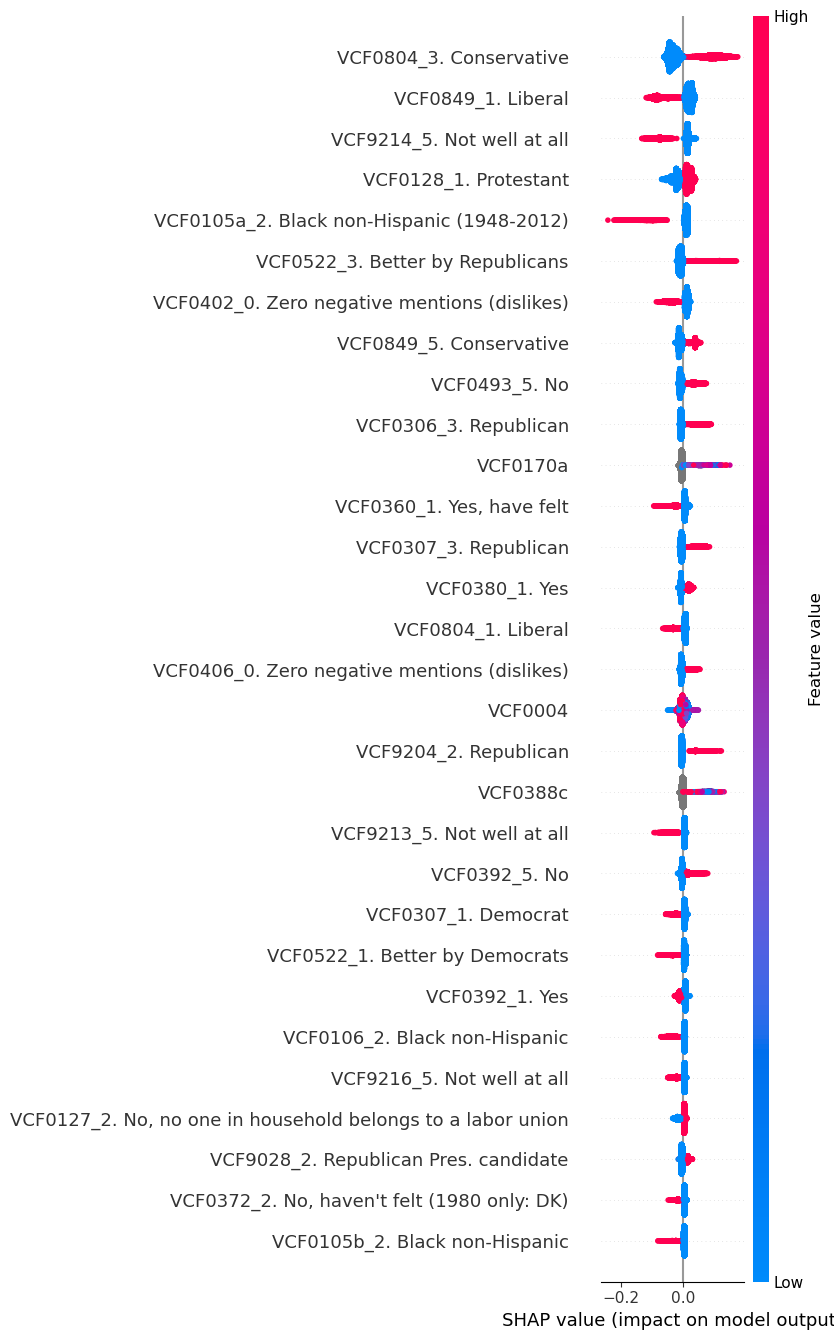

In [20]:
%%time
(explainer, shap_values, train_columns, train_index, alg,output_subfolder,metrics) = xgboost_run(
    title = "Trump V Biden 2020 Presidential Election",
                                                    dataset=anes_num[mask].drop(variances[variances<.01].index,axis=1),
                                                    var_list = [name],var_stub_list = [name,pattern,
                    "VCF9027","VCF0303", "VCF0301", "VCF0302", "VCF0305","VCF0713","VCF0734","VCF0735","VCF0736",
                    "VCF0704","VCF0704a","VCF0705","VCF0706","VCF0707","VCF0708","VCF0709","VCF0710","VCF0711",
                    "VCF0487","VCF0314","VCF0315","VCF0715","VCF0716",
                    "VCF9205","VCF1004","VCF0700","VCF9025",
                    "VCF0374", #Likes Anything about Democratic party
                    "VCF0475", #Likes Anything about Democratic Presidential Cand
                    "VCF0405", #Republican Presidential Cand: Respondent Likes - Number of Mentions
                    "VCF0386", #Likes Anything about Republican party
                    "VCF0318", #Republican Party: Respondent Likes - Number of Mentions
                    "VCF0426", #Thermometer - Republican Presidential Candidate
                    "VCF0376", #1972-2004 Mention 2: Like About Democratic Party
                    "VCF0401", #Democratic Presidential Cand: Respondent Likes - Number of Mentions
                    "VCF0319", #Republican Party: Respondent Dislikes - Number of Mentions
                    "VCF0201", #Thermometer - Democrats
                    "VCF0202", #Thermometer - Republicans
                    "VCF0218", #Thermometer - Democratic Party
                    "VCF0224", #Thermometer - Republican Party
                    "VCF0481", #Dislikes Anything about Democratic Presidential Cand                                                                   
                                                                                       
                                                                                       
                                                         ],
    verbosity=0)

In [ ]:
# VCF0804 Liberal-Conservative Scale 1972- COLLAPSED
# VCF0849 Liberal-Conservative Position 1984- COLLAPSED

# VCF0128 Respondent - Religion Major Group
# VCF0105a Race-ethnicity summary, 7 categories

# VCF9204 CSES: Which political party is it that represents R's views best

# "VCF9214", #How well does _really cares about people like you_ describe: Republican Presidential candidate (no RB,5 cat)
# VCF0522 Which Party Will Best Avoid War/Bigger War

# VCF0306 Party Identification of Respondent's Father
# VCF0307 Party Identification of Respondent's Mother

In [ ]:
# VCF0170a County of IW 1956-1960 ??? regional variation???
# VCF0004 Year of Study

In [25]:
search(anes_num,"VCF0734")

VCF0734_0. NA who will vote for; no Pre IW; no Post IW;       68224
VCF0734_1. INTENDED Democratic: voted Democratic              68224
VCF0734_2. INTENDED undecided: voted Democratic;              68224
VCF0734_3. INTENDED Republican: voted Democratic              68224
VCF0734_4. INTENDED Democratic: did not vote/voted 'other'    68224
VCF0734_5. INTENDED undecided: did not vote/voted 'other'     68224
VCF0734_6. INTENDED Republican: did not vote/voted 'other'    68224
VCF0734_7. INTENDED Democratic: voted Republican              68224
VCF0734_8. INTENDED undecided: voted Republican; INTENDED     68224
VCF0734_9. INTENDED Republican: voted Republican              68224
dtype: int64

In [21]:
gc.collect()

156853

In [ ]:
############################## SIDETEACKED LOOKING AT JBM Chart on Incumbency Disease in 2024

In [5]:
party = pd.read_excel("E:\\Users\\Gamer\\Documents\\GitHub\\BES_analysis\\BES_analysis_data\\Parlgov\\parlgov-stable.xlsx",
             sheet_name="party")
election = pd.read_excel("E:\\Users\\Gamer\\Documents\\GitHub\\BES_analysis\\BES_analysis_data\\Parlgov\\parlgov-stable.xlsx",
             sheet_name="election")
cabinet = pd.read_excel("E:\\Users\\Gamer\\Documents\\GitHub\\BES_analysis\\BES_analysis_data\\Parlgov\\parlgov-stable.xlsx",
             sheet_name="cabinet")
variable = pd.read_excel("E:\\Users\\Gamer\\Documents\\GitHub\\BES_analysis\\BES_analysis_data\\Parlgov\\parlgov-stable.xlsx",
             sheet_name="variable")

In [6]:
wdi_data = pd.read_excel("E:\\Users\\Gamer\\Documents\\GitHub\\BES_analysis\\BES_analysis_data\\Parlgov\\WDIEXCEL.xlsx",
             sheet_name="Data")
wdi_country = pd.read_excel("E:\\Users\\Gamer\\Documents\\GitHub\\BES_analysis\\BES_analysis_data\\Parlgov\\WDIEXCEL.xlsx",
             sheet_name="Country")
wdi_series = pd.read_excel("E:\\Users\\Gamer\\Documents\\GitHub\\BES_analysis\\BES_analysis_data\\Parlgov\\WDIEXCEL.xlsx",
             sheet_name="Series")
wdi_country_series = pd.read_excel("E:\\Users\\Gamer\\Documents\\GitHub\\BES_analysis\\BES_analysis_data\\Parlgov\\WDIEXCEL.xlsx",
             sheet_name="country-series")
wdi_series_time = pd.read_excel("E:\\Users\\Gamer\\Documents\\GitHub\\BES_analysis\\BES_analysis_data\\Parlgov\\WDIEXCEL.xlsx",
             sheet_name="series-time")

In [27]:
## jbm chart
# incumbent party change in vote share in each election by year
## dev only?, 5+ entries/year only

,country_name_short,country_name,party_name_short,party_name_english,party_name,party_name_ascii,family_name_short,family_name,left_right,state_market,...,euprofiler,ees,castles_mair,huber_inglehart,ray,benoit_laver,chess,country_id,party_id,family_id
0,AUS,Australia,ACP-V,Australian Country Party (Vic),Australian Country Party (Vic),Australian Country Party (Vic),con,Conservative,7.4000,6.4000,...,NaN,NaN,NaN,NaN,NaN,NaN,NaN,33,1935,26
1,AUS,Australia,AD,Australian Democrats,Australian Democrats,Australian Democrats,soc,Social democracy,3.7004,3.3684,...,NaN,NaN,102.0,203.0,NaN,4703.0,NaN,33,120,11
2,AUS,Australia,AG,Australian Greens,Australian Greens,Australian Greens,eco,Green/Ecologist,1.5439,1.2982,...,NaN,NaN,NaN,NaN,NaN,4739.0,NaN,33,751,19
3,AUS,Australia,ALP,Australian Labor Party,Australian Labor Party,Australian Labor Party,soc,Social democracy,3.8833,4.0351,...,NaN,NaN,101.0,NaN,NaN,4721.0,NaN,33,1253,11
4,AUS,Australia,AP,Australia Party,Australia Party,Australia Party,lib,Liberal,6.0000,6.7000,...,NaN,NaN,NaN,NaN,NaN,NaN,NaN,33,1760,6
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
1702,TUR,Turkey,YSPG,Party of Greens and the Left Future,Yeşiller ve Sol Gelecek Partisi,Yesiller ve Sol Gelecek Partisi,eco,Green/Ecologist,2.5000,2.5000,...,NaN,NaN,NaN,NaN,NaN,NaN,NaN,20,2895,19
1703,TUR,Turkey,YTP,New Turkey Party,Yeni Türkiye Partisi,Yeni Turkiye Partisi,soc,Social democracy,3.3000,3.5000,...,NaN,NaN,NaN,NaN,NaN,NaN,NaN,20,2304,11
1704,TUR,Turkey,ZP,Victory Party,Zafer Partisi,Zafer Partisi,right,Right-wing,8.7000,5.9000,...,NaN,NaN,NaN,NaN,NaN,NaN,NaN,20,2898,40
1705,TUR,Turkey,no-seat,no seat,no seat,no seat,none,no family,NaN,NaN,...,NaN,NaN,NaN,NaN,NaN,NaN,NaN,20,2316,12


In [ ]:
# poss biases - 2024 not complete, maybe there's a seasonal/delay effect with incumbents who are in shit going early in year?

In [4]:
# election[election["party_name_english"]=="Australian Labor Party"]

# parties are assigned static left-right positions!

In [ ]:
# election
# vote_share, party_id, election_id, previous_parliament_election_id, previous_cabinet_id (cabinet_id of incumbent govt)
# type (parliament|ep)

# incumbency
# can get pm/in cabinet -> incumbency from cabinet_id -> cabinet_party/prime_minister flag
# can also note how_many_incumbents (maybe weaker in multiparty???)

# voteshare change
# previous_parliament_election_id and vote_share!

# choice of countries/dates

In [7]:
def get_last_election_vote_share(x):
    # x= election row
    previous_id = x["previous_parliament_election_id"]
    if pd.isna( previous_id ):
        return np.nan

    elec_rows = election[(election["election_id"]==previous_id)]
    if x["party_id"] not in elec_rows["party_id"].values:
        return np.nan
    else:
        return elec_rows[elec_rows["party_id"]==x["party_id"]]["vote_share"].values[0]

In [8]:
def get_cabinet_party(x):
    # x= election row
    previous_cabinet = x["previous_cabinet_id"]
    if pd.isna( previous_cabinet ):
        return np.nan

    cabinet_rows = cabinet[(cabinet["cabinet_id"]==previous_cabinet)]
    if x["party_id"] not in cabinet_rows["party_id"].values:
        return np.nan
    else:
        return cabinet_rows[cabinet_rows["party_id"]==x["party_id"]]["cabinet_party"].values[0]
    
def get_pm_party(x):
    # x= election row
    previous_cabinet = x["previous_cabinet_id"]
    if pd.isna( previous_cabinet ):
        return np.nan

    cabinet_rows = cabinet[(cabinet["cabinet_id"]==previous_cabinet)]
    if x["party_id"] not in cabinet_rows["party_id"].values:
        return np.nan
    else:
        return cabinet_rows[cabinet_rows["party_id"]==x["party_id"]]["prime_minister"].values[0]    
    
def get_caretaker(x):
    # x= election row
    previous_cabinet = x["previous_cabinet_id"]
    if pd.isna( previous_cabinet ):
        return np.nan

    cabinet_rows = cabinet[(cabinet["cabinet_id"]==previous_cabinet)]
    if x["party_id"] not in cabinet_rows["party_id"].values:
        return np.nan
    else:
        return cabinet_rows[cabinet_rows["party_id"]==x["party_id"]]["caretaker"].values[0]  

In [9]:
# cabinet["prime_minister"].corr(cabinet["cabinet_party"])

In [12]:
# get_cabinet_party( election.loc[2284] )
# error due to CDU only appearing in cabinet as CDU + CSU (diff party)!

In [13]:
# get_pm_party( election.loc[2284] )

In [14]:
# election[]

In [11]:
# election.loc[2284]

In [15]:
# election.loc[343]

In [16]:
# election.loc[340:350]

In [17]:
# get_last_election_vote_share( election.loc[343] )

In [18]:
# election.groupby(["country_name_short","election_date"])["pm_party"].apply(lambda x: ~(x.any())).sum()

# 2926/9016 rows
# 37 elections - just by virtue of first row

In [ ]:
### manual fix for *start of datasets!*

In [19]:
# election.groupby(["country_name_short","election_date"])["pm_party"].apply(lambda x: ~(x.any())).groupby("country_name_short").sum().sort_values()

In [660]:
# temp = election.groupby(["country_name_short","election_year"])["pm_party"].apply(lambda x: ~(x.any())).groupby(["country_name_short","election_year"]).sum().sort_values()
# temp[temp>0].loc[["SWE","GRC","CZE","FIN","ITA","FRA","BGR","DEU","CHE"]].sort_index().tail(54)

In [20]:
# temp[temp>0].loc[["IRL"]].sort_index().tail(54)

In [21]:
# also bugs with FDP

# eu parliament dodgy for 'past cabinet'

# add caretake_govts

# DEU - CDU/CSU not tagged correctly
# CHE - just doesn't have "president/prime minister" in this manner, only "cabinet_party" makes sense
# BGR - genuinely incredibly messy
# FRA/ITA/FIN/CZE/ROU/GRC/SWE/HRV/ISL/ISR/DNK/JPN/HUN/LVA/NLD/NZL/CYP/PRT/AUT/SVK done

# -> create "combined incumbency by adding cabinet + pm"??
# fill in blanks in vote_share_change where vote_share, previous_vote_share exist!

# vote share missing in a bunch of places too!

In [22]:
# election["vote_share_previous"].dropna()

In [23]:
# election["cabinet_party"].value_counts(dropna=False)

In [24]:
# election["pm_party"].value_counts(dropna=False)

In [25]:
# election["cabinet_party"].corr(election["pm_party"])

In [29]:
# mask = (election["election_type"]=="parliament") & (election["pm_party"]==1)
# sns.scatterplot(data=election[mask],x="election_year",y="vote_share_change");

In [30]:
# mask = (election["election_type"]=="parliament") & (election["pm_party"]==1)\
#     & (~election["country_name_short"].isin(["PRT","ROU","LVA","CYP","LTU","BGR","POL","ESP", "SVN", "EST"]))
# year_vc = election[mask]["election_year"].value_counts()

# year_mask = election[mask]["election_year"].isin(year_vc[year_vc>=5].index)

# sns.scatterplot(data=election[mask][year_mask],x="election_year",y="vote_share_change");

In [26]:
# election.columns

In [27]:
# election[mask][year_mask].groupby("country_name_short")["vote_share_change"].min().sort_values()

In [28]:
# election[mask][year_mask].groupby("country_name_short")["vote_share_change"].max().sort_values()

In [ ]:
# PRT    20.70
# ROU    25.54

# LVA   -65.570000 # 2nd elec after fall of communism!
# CYP   -51.700000 # same but post military?
# LTU   -33.970000 # same but they are listed as having 
# BGR   -30.970000 # looks a bit similar, but a much longer process (97/01)
# POL   -29.740000 # bit like Bulgaria maybe?

# add ESP, SVN, EST

# Canada appears but seems smaller than listed

In [95]:
# election["election_year"].max()

2023

In [39]:
election["vote_share_previous"] = election.apply(get_last_election_vote_share,axis=1)
election["cabinet_party"] = election.apply(get_cabinet_party,axis=1)
election["pm_party"] = election.apply(get_pm_party,axis=1)
election["election_year"] = election["election_date"].apply(lambda x: x[0:4]).astype('int')
election["vote_share_change"] = election["vote_share"] - election["vote_share_previous"]
election["election_datetime"] = pd.to_datetime( election["election_date"] )

In [31]:
# election.sort_values(by="election_datetime")

In [32]:
# election[["country_name_short","country_name","country_id"]]

In [33]:
# wdi_country[["Country Code","Short Name","Table Name","Long Name",'2-alpha code']]

In [34]:
# election[election["country_name_short"].isin(wdi_country["Country Code"].unique())]

In [ ]:
# country_name_short -> Country Code

In [35]:
# wdi_data["Indicator Name"].value_counts().sort_values()

In [ ]:
## really excessive number of possible data rows! # may need to do some preemptive filtering

In [ ]:
## so every indicator for each of 266 countries

In [36]:
# wdi_data["Country Code"].value_counts()

In [ ]:
## 1496 x 266

In [37]:
# wdi_data.notnull().sum()[-50:]/397936

# 20-60% filled in

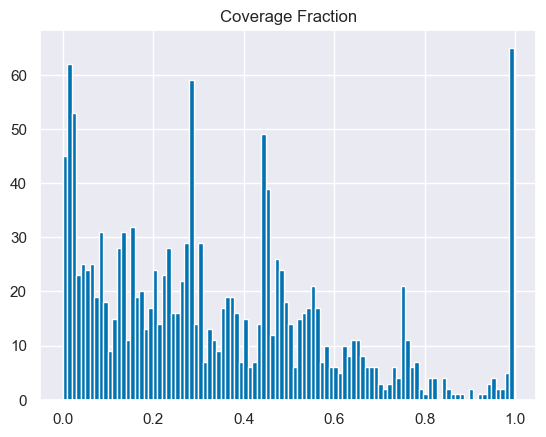

In [142]:
(wdi_data[wdi_data.columns[-64:]].notnull().sum(axis=1).groupby(wdi_data["Indicator Name"]).mean()/64).hist(bins=100);
plt.title("Coverage Fraction");

In [ ]:
# country + year -> grab indicator columns for year, year-1, year-2 ...

In [146]:
election[mask]["vote_share_change"].value_counts(dropna=False)
# -> 558 - 26

vote_share_change
 NaN     26
-1.50    10
 1.60     5
-0.10     5
 0.50     5
         ..
 1.60     1
 3.50     1
-1.20     1
 3.20     1
-7.02     1
Name: count, Length: 558, dtype: int64

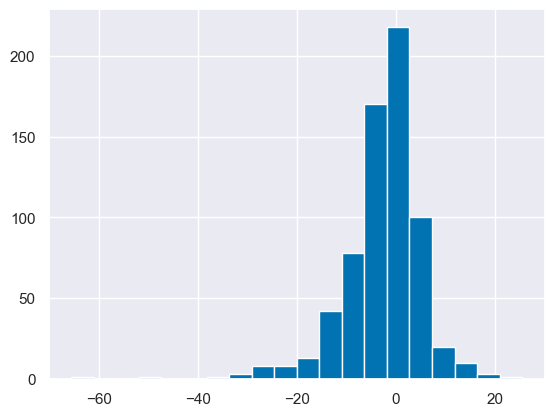

In [148]:
election[mask]["vote_share_change"].hist(bins=20);

In [162]:
election[mask]["country_name"].value_counts()

country_name
Australia         45
Denmark           45
New Zealand       37
Belgium           36
Canada            35
Norway            32
Iceland           31
Sweden            30
Ireland           30
United Kingdom    27
Netherlands       27
Japan             26
Austria           26
Finland           25
Luxembourg        23
France            23
Israel            23
Malta             18
Greece            15
Portugal          15
Spain             14
Italy             13
Germany           11
Turkey            11
Latvia             9
Poland             9
Slovenia           9
Lithuania          8
Hungary            8
Cyprus             8
Slovakia           8
Estonia            8
Czech Republic     5
Croatia            5
Bulgaria           4
Romania            4
Name: count, dtype: int64

In [38]:
# set(election["country_name"].value_counts().index)-set(election[mask]["country_name"].value_counts().index)

In [ ]:
# South Korea and USA are definitely OECD countries, but not included because presidential??

# except Cyrpus and Turkey are!

# Switzerland also not included for national elections??

# poor at best coverage of "presidential system" dynamics makes for a bad fit!

In [ ]:
# https://pbs.twimg.com/media/GbxVPLNXAA89QSA?format=jpg&name=900x900

# he obviously took some elements out - not raw parlgov

In [ ]:
# we'll need to add a bunch of elections (with incumbency status filled in, because they won't have 'cabinet' datasets)

# then we'll have a reduced country list
# -> use to filter out low coverage variables
# -> then add them to one giant (but shallow) dataset


In [169]:
# election.to_csv("E:\\Users\\Gamer\\Documents\\GitHub\\BES_analysis\\BES_analysis_data\\Parlgov\\election_manual.csv")

# don't overwrite!

In [ ]:
# I note that they don't record turnout!

In [715]:
# election_manual

In [ ]:
# mask = (election["election_type"]=="parliament") & (election["pm_party"]==1)
# sns.scatterplot(data=election[mask],x="election_year",y="vote_share_change");

In [714]:
# election_manual["vote_share_change"].groupby(election_manual["country_name_short"]).min().sort_values()

In [686]:
# election_manual.columns

In [717]:
# mask = (election_manual["election_type"]=="parliament") & (election_manual["pm_party"]==1)
# election_manual["election_year"][mask].value_counts().tail(50)

In [ ]:
# years with <5 elections: 3; 1967, 1978 4; 1970, 1975

In [712]:
# election_manual[election_manual["country_name_short"].isnull()]

In [ ]:
### try merging datasets to do some xgboosting

In [710]:
# [x for x in country_list if x not in wdi_data['Country Code'].unique()]

In [1082]:
country_list = election_manual["country_name_short"].unique()
country_mask = wdi_data['Country Code'].isin( country_list )

temp = (wdi_data[country_mask][wdi_data.columns[-64:]].notnull().sum(axis=1).groupby(wdi_data[country_mask]["Indicator Name"]).mean()/64)
indicator_list = list( temp[temp>0].index )
len(indicator_list)

1448

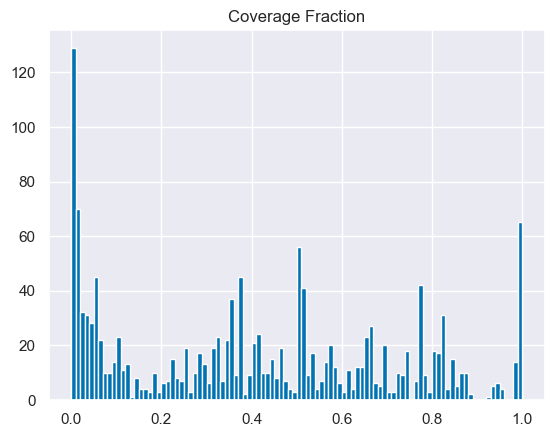

In [214]:
(wdi_data[country_mask][wdi_data.columns[-64:]].notnull().sum(axis=1).groupby(wdi_data[country_mask]["Indicator Name"]).mean()/64).hist(bins=100);
plt.title("Coverage Fraction");

In [40]:
election_manual = pd.read_csv("E:\\Users\\Gamer\\Documents\\GitHub\\BES_analysis\\BES_analysis_data\\Parlgov\\election_manual.csv",encoding='ansi')

In [1124]:
%%time
global_inf = wdi_data[wdi_data["Indicator Name"]=="Inflation, consumer prices (annual %)"].select_dtypes('number').median()

inf_corrs = wdi_data_ind.loc[wdi_data_ind.notnull().sum(axis=1)>2].select_dtypes('number').T.corrwith(global_inf)
# global_inf

CPU times: total: 15.6 s
Wall time: 1min 1s


In [1158]:
# global_inf.index
# wdi_data_ind.loc[inf_corrs[inf_corrs==-1].index]

temp_df = pd.DataFrame(inf_corrs)
temp_df.replace(-1.0,np.nan).replace(1.0,np.nan)[0].dropna().sort_values()
#.replace(-1.0,np.nan).replace(1,np.nan).dropna().sort_values().values

temp_df.loc[temp_df[0]>.95,0]=np.nan
temp_df.loc[temp_df[0]<-.95,0]=np.nan
temp_df[0].dropna().sort_values().tail(50)#.sort_index()
temp_df = temp_df.reset_index()
temp_df[temp_df["Indicator Name"].apply(lambda x: "inflation" in x.lower())][0].describe()

count    708.000000
mean       0.487145
std        0.260702
min       -0.722720
25%        0.309108
50%        0.498358
75%        0.684903
max        0.947830
Name: 0, dtype: float64

In [1178]:
USA_inf = wdi_data_ind.loc[("USA","Inflation, consumer prices (annual %)")][wdi_data_ind.columns[2:]].astype('float')
USA_inf

1960    1.457976
1961    1.070724
1962    1.198773
1963    1.239669
1964    1.278912
          ...   
2020    1.233584
2021    4.697859
2022    8.002800
2023    4.116338
2024    4.116338
Name: (USA, Inflation, consumer prices (annual %)), Length: 65, dtype: float64

In [1179]:
# USA_corrs= \
#     .corrwith(USA_inf)

In [1191]:
%%time
# mask =  (election_final['incumbency']>=1)\
#     &(election_final['election_type']=='parliament')\
#     &(election_final['country_name_short'].isin(["DEU",]))
# #     &(election_final['election_year']>=2000)\

temp_usa_ind = wdi_data[wdi_data["Country Code"]=="USA"][wdi_data.columns[2:]].drop("Indicator Code",axis=1).set_index("Indicator Name").T
temp_usa_ind["USA_inf"] = USA_inf
print(mask.sum())
# election_final.select_dtypes('number')[mask].corrwith(election_final["vote_share_change"][mask])\
#     .drop(["vote_share_change","vote_share","vote_share_previous"]).dropna().sort_values()

name="USA_inf"
# name="vote_share_frac"
# name="coal_vote_frac_change"
pattern = pattern

df, corr_type = make_corr_summary(temp_usa_ind, name, pattern=pattern,
                                  min_sample_size=10,min_p_value=.95)
display_corr(df,name,corr_type)


45


,r,p,N
USA_inf,1.000000,0.00,64
"Inflation, consumer prices (annual %)",1.000000,0.00,64
"Inflation, GDP deflator (annual %)",0.950000,0.00,63
"Inflation, GDP deflator: linked series (annual %)",0.900000,0.00,34
"PM2.5 air pollution, population exposed to levels[...]",0.810000,0.00,12
Adjusted savings: natural resources depletion (%[...],0.810000,0.00,52
Oil rents (% of GDP),0.810000,0.00,52
Adjusted savings: energy depletion (% of GNI),0.780000,0.00,52
Forest rents (% of GDP),0.770000,0.00,52
Total natural resources rents (% of GDP),0.770000,0.00,52


CPU times: total: 281 ms
Wall time: 1.06 s


In [ ]:
# Inflation, GDP deflator (annual %)                   0.854852
# Inflation, consumer prices (annual %)                0.881168
# Inflation, GDP deflator: linked series (annual %)    0.527549


In [1185]:
temp.loc[[x for x in temp.index if ("inflation" in x.lower()) or ("consumer" in x.lower()) ]]

Indicator Name
Consumer price index (2010 = 100)                    0.885691
Inflation, GDP deflator (annual %)                   0.854852
Inflation, GDP deflator: linked series (annual %)    0.527549
Inflation, consumer prices (annual %)                0.881168
dtype: float64

In [961]:
temp.loc[[x for x in temp.index if ("gdp" in x.lower())]].sort_values()

Indicator Name
Claims on other sectors of the domestic economy (% of GDP)             0.041530
Gross fixed capital formation, private sector (% of GDP)               0.071135
Domestic credit provided by financial sector (% of GDP)                0.082237
Government expenditure per student, secondary (% of GDP per capita)    0.207237
Government expenditure per student, primary (% of GDP per capita)      0.207237
                                                                         ...   
GDP per capita (constant 2015 US$)                                     0.870477
GDP per capita (constant LCU)                                          0.870477
GDP (constant 2015 US$)                                                0.870477
GDP (current LCU)                                                      0.874178
GDP per capita (current LCU)                                           0.874178
Length: 85, dtype: float64

In [41]:
vote_share_change_null = election_manual["vote_share_change"].isnull()
election_manual.loc[vote_share_change_null,"vote_share_change"] = election_manual['vote_share'][vote_share_change_null]\
    - election_manual['vote_share_previous'][vote_share_change_null]

vote_previous = election_manual["vote_share_previous"].isnull()
election_manual.loc[vote_previous,"vote_share_previous"] = election_manual['vote_share'][vote_previous]\
    - election_manual['vote_share_change'][vote_previous]

election_manual["caretaker_party"] = election.apply(get_caretaker,axis=1)
election_manual['cabinet_party'] = election_manual['cabinet_party'].fillna(0)
election_manual['pm_party'] = election_manual['pm_party'].fillna(0)
election_manual['caretaker_party'] = election_manual['caretaker_party'].fillna(0)

election_manual['incumbency'] = (election_manual['pm_party']*2)+(election_manual['cabinet_party'])+(election_manual['caretaker_party']*.5)

election_manual["vote_share_frac"] = election_manual["vote_share"]/election_manual["vote_share_previous"]
election_manual["coal_member"] = election_manual["incumbency"] > .5

coal_vote_share_change = election_manual.groupby(["country_name_short","election_date","election_type","coal_member"])["vote_share_change"].sum()

election_manual["coal_vote_share_change"]=election_manual.apply(lambda x: coal_vote_share_change.loc[(x["country_name_short"],x["election_date"],
                                                              x["election_type"],x["coal_member"])] ,axis=1)


coal_vote_frac_change = election_manual.groupby(["country_name_short","election_date","election_type","coal_member"]).apply(lambda x: x["vote_share"].sum()/(x["vote_share_previous"].sum()) )

election_manual["coal_vote_frac_change"]=election_manual.apply(lambda x: coal_vote_frac_change.loc[(x["country_name_short"],x["election_date"],
                                                              x["election_type"],x["coal_member"])] ,axis=1)

coal_left_right = election_manual.groupby(["country_name_short","election_date","election_type","coal_member"])\
    .apply(lambda x: (x["vote_share_previous"]*x["left_right"]).sum()/(x["vote_share_previous"].sum()))
election_manual["coal_left_right"]=election_manual.apply(lambda x: coal_left_right.loc[(x["country_name_short"],x["election_date"],
                                                              x["election_type"],x["coal_member"])] ,axis=1)
election_manual["coal_left_right"] = election_manual["coal_left_right"].replace(0.0,np.nan)

In [92]:
election_final = election_manual.drop(["Unnamed: 0","notes"],axis=1)
election_final["election_datetime"] = pd.to_datetime(election_final["election_datetime"])
election_final = election_final[election_final["election_year"]>=1960]
# election_final = election_final[election_final["election_year"]<=2023]

# wdi data only goes back this far

In [1020]:
# election_manual[(election_manual['vote_share_previous'].notnull())&election_manual['vote_share_change'].isnull()&(election_manual["election_type"]=="parliament")]\
#     [["country_name_short","election_date","vote_share","vote_share_previous","vote_share_change"]].tail(50)

# mostly mergers/new parties/some weird choice among coders to switch between parties/alliances

In [709]:
# election_manual[election_manual["election_type"]=="parliament"].groupby(["country_name_short","election_date"])["vote_share"].sum().sort_values().head(50)

# fixed manual error with GBR2024
# one bug with France 1978 (118%voteshare!)

In [929]:
wdi_data["Indicator Code"].value_counts()

Indicator Code
EG.CFT.ACCS.ZS       266
SH.STA.HYGN.ZS       266
SE.PRM.PRSL.ZS       266
SE.PRM.PRSL.MA.ZS    266
SE.PRM.PRSL.FE.ZS    266
                    ... 
NY.GNP.MKTP.CN       266
NY.GNP.MKTP.KN       266
NY.GNP.MKTP.KD       266
SI.POV.GINI          266
SH.HIV.INCD.YG       266
Name: count, Length: 1496, dtype: int64

In [957]:
wid_pca = wdi_data[wdi_data["Indicator Name"].isin(indicator_list)].set_index("Indicator Name")
wid_pca = wid_pca.drop(["Country Name","Country Code","Indicator Code"],axis=1)
wid_pca = wid_pca.fillna(method='ffill',axis=1)
wid_pca = wid_pca.fillna(method='bfill',axis=1)
wid_pca = wid_pca.dropna()

CPU times: total: 3.97 s
Wall time: 9.86 s


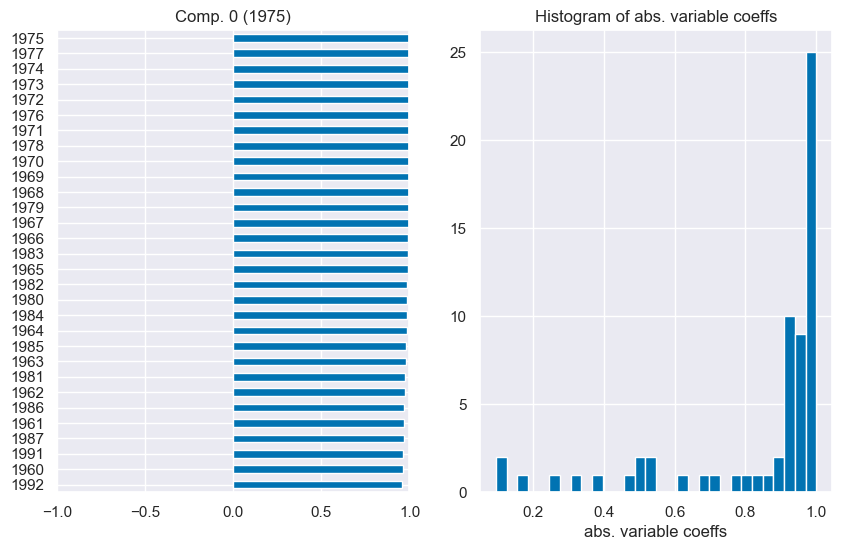

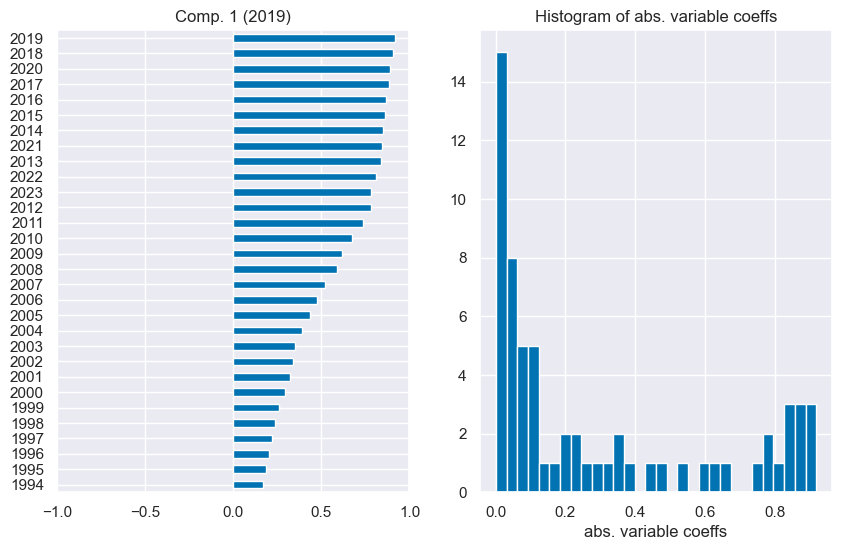

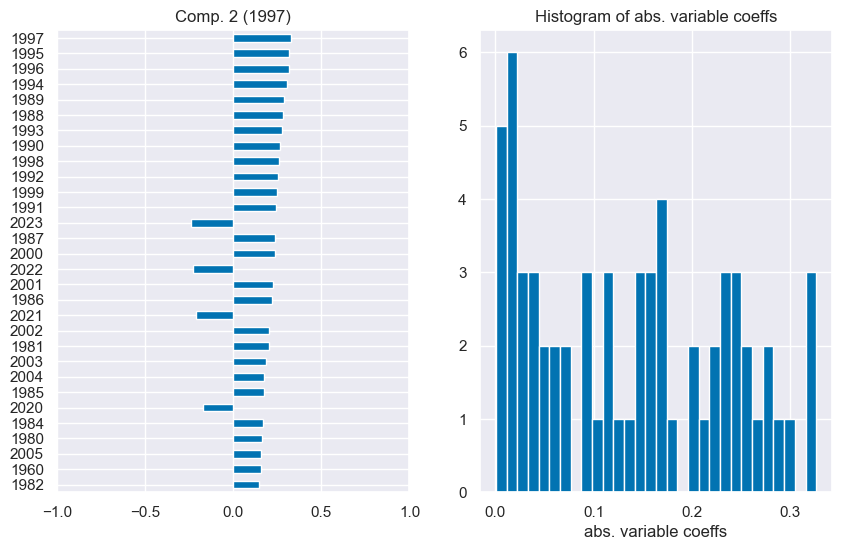

In [958]:
%%time
from sklearn.decomposition import PCA, FactorAnalysis
from sklearn.preprocessing import StandardScaler
n_components = 3

# decomp = PCA(svd_solver="full",n_components =n_components )
decomp = FactorAnalysis(n_components =n_components )

scaler = StandardScaler()
BES_std = scaler.fit_transform(wid_pca)

decomp.fit(BES_std)
wid_pca_decomp = decomp.transform(BES_std)
# BES_decomp  = pd.DataFrame(BES_decomp,index=BES_num.index)
cols = wid_pca.columns
(BES_decomp, comp_labels, comp_dict) = display_components(n_components, decomp, cols, wid_pca_decomp,
                                                          show_first_x_comps=n_components);

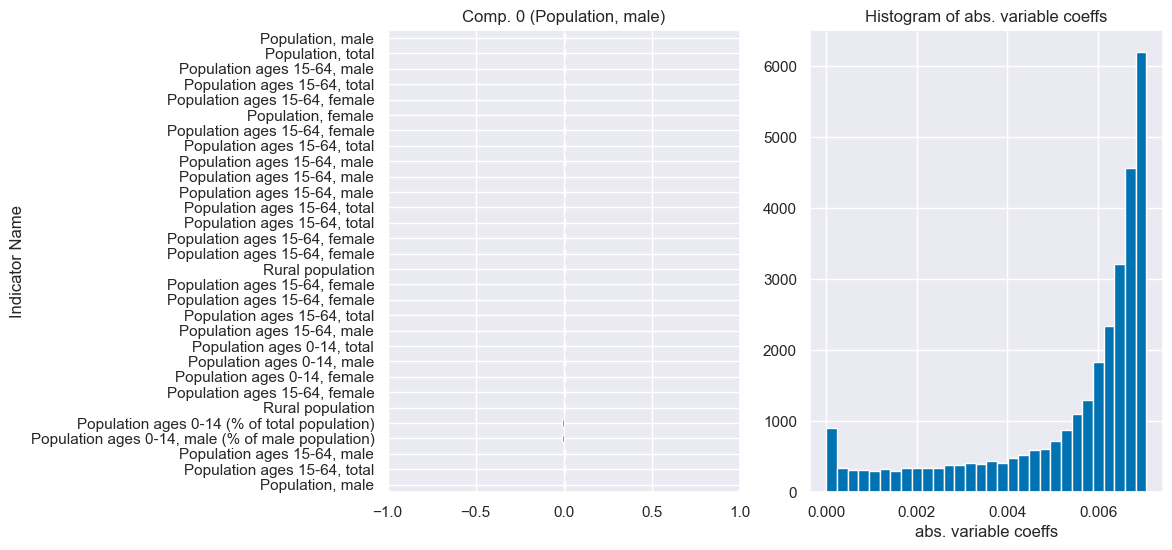

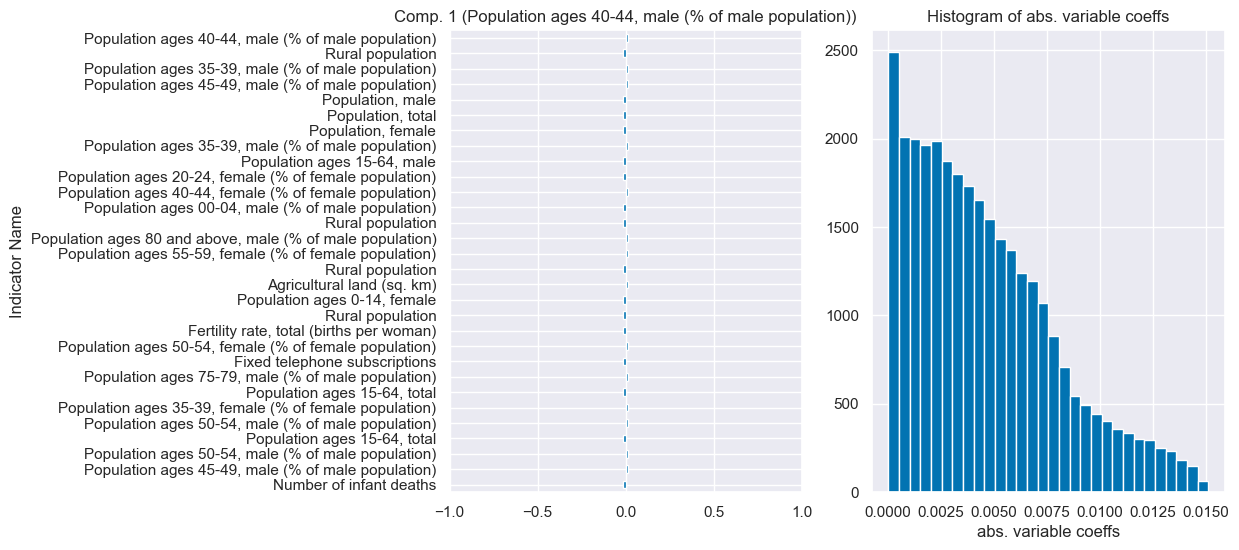

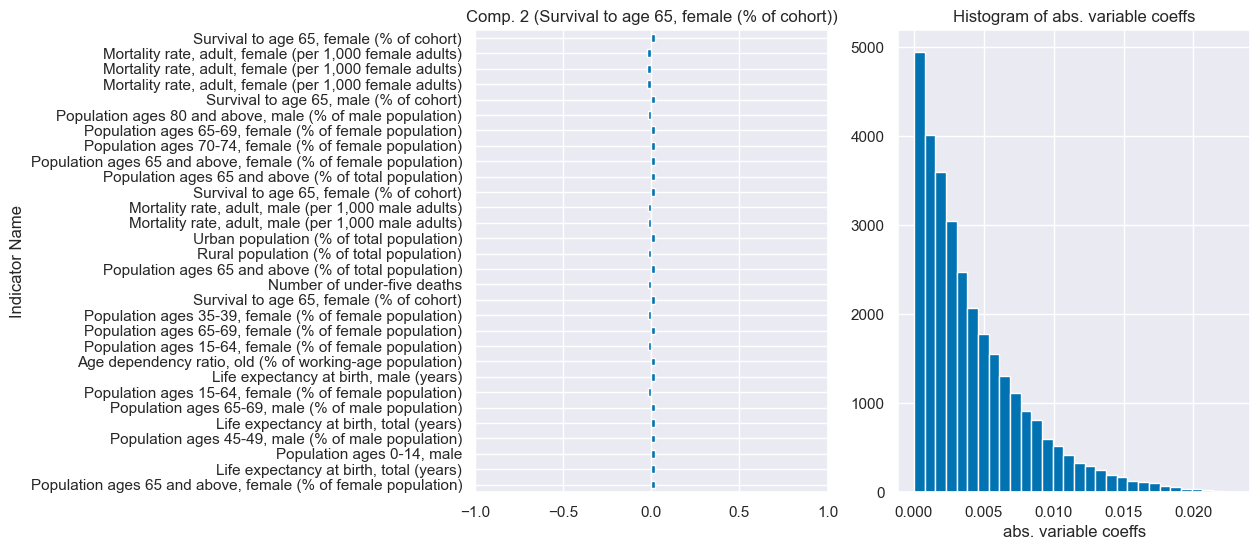

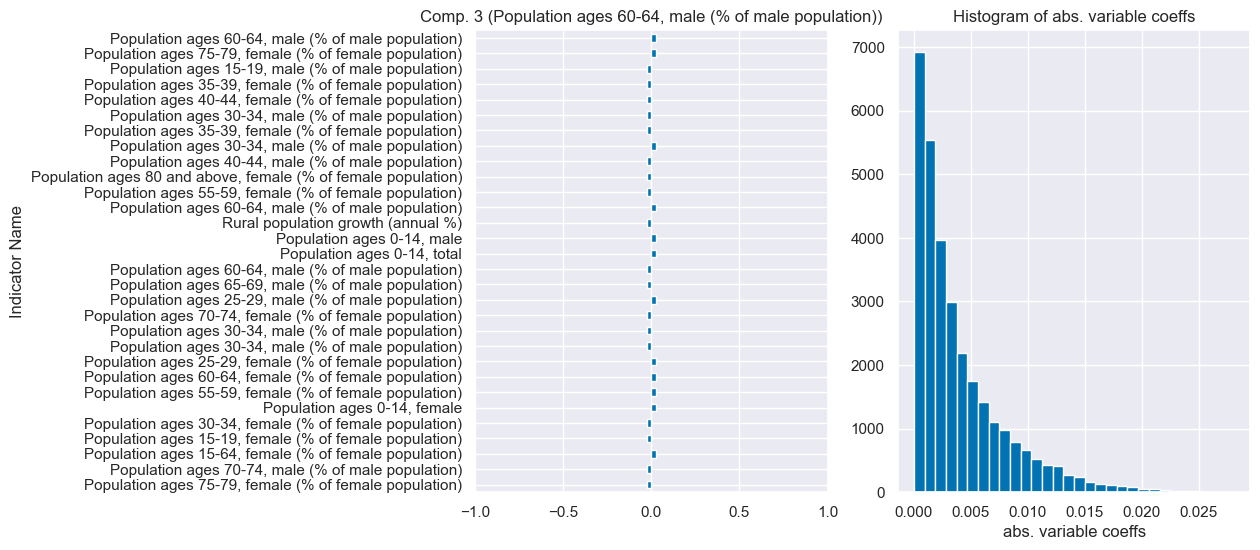

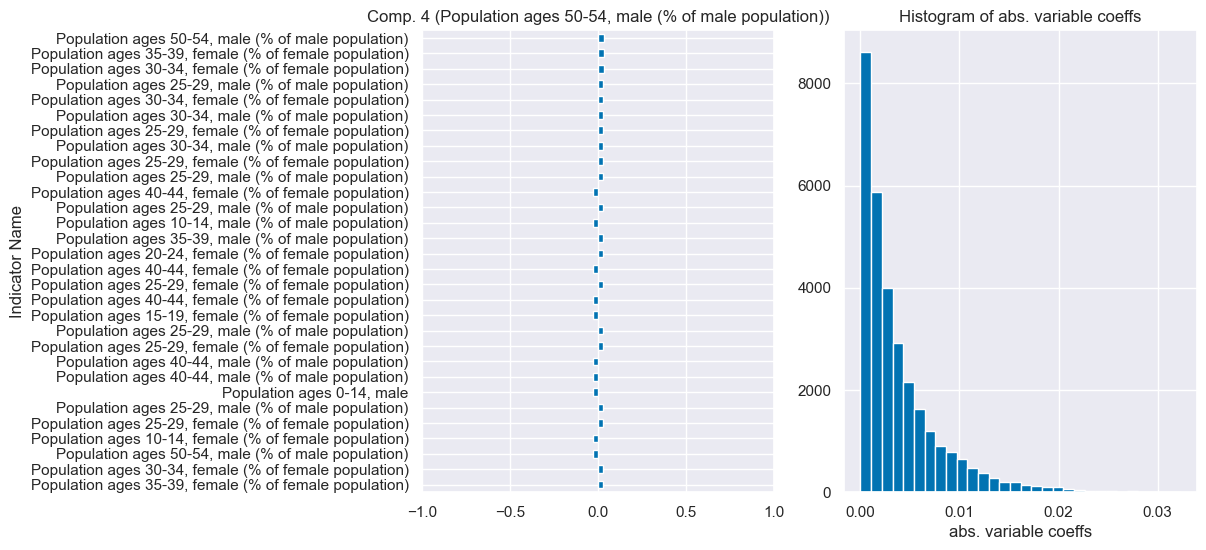

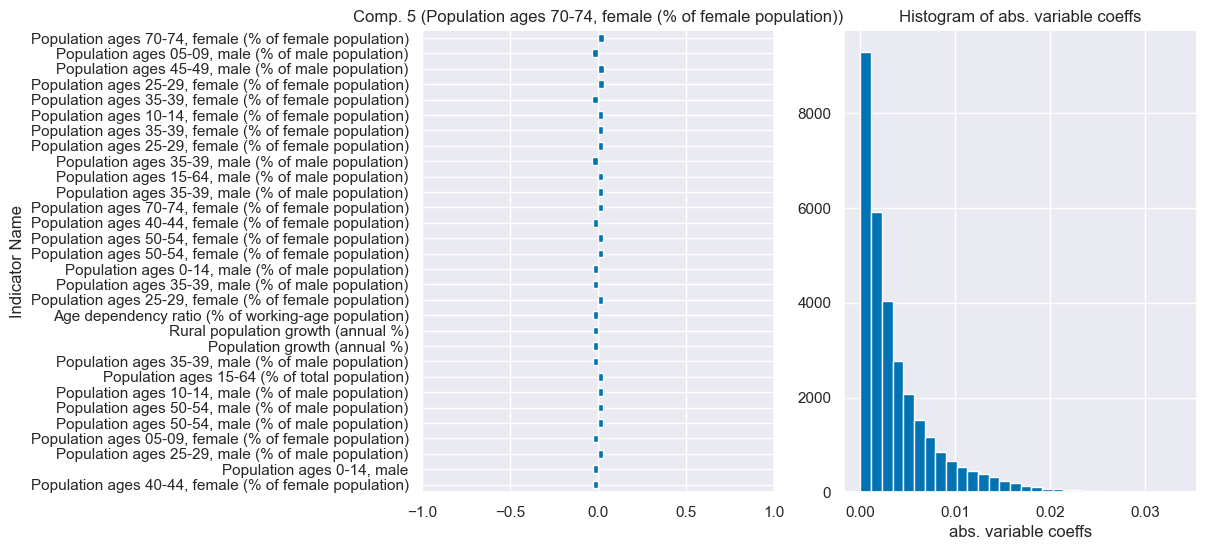

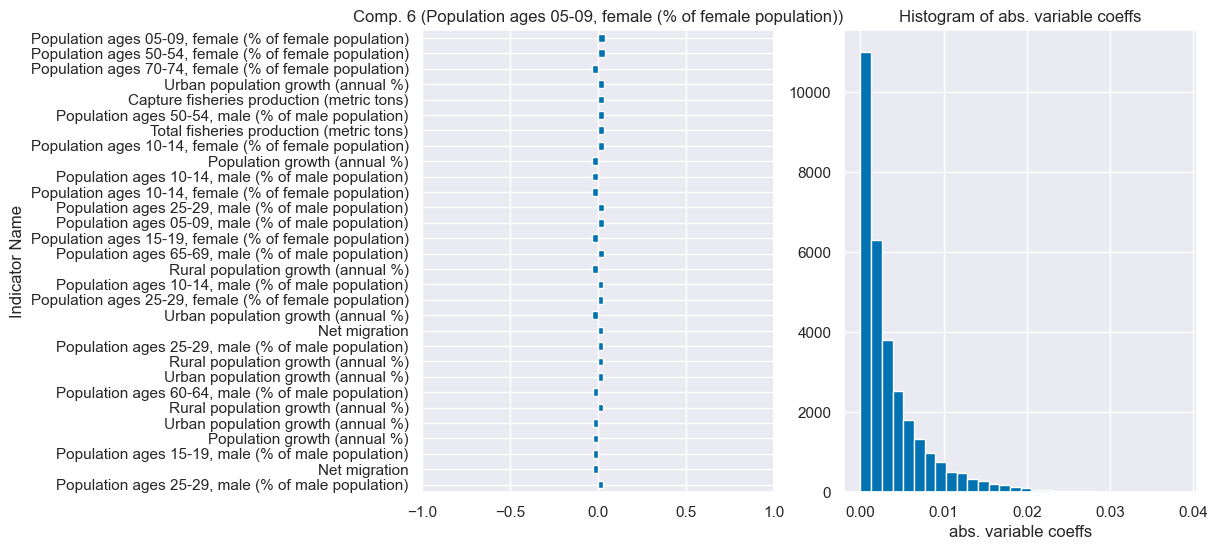

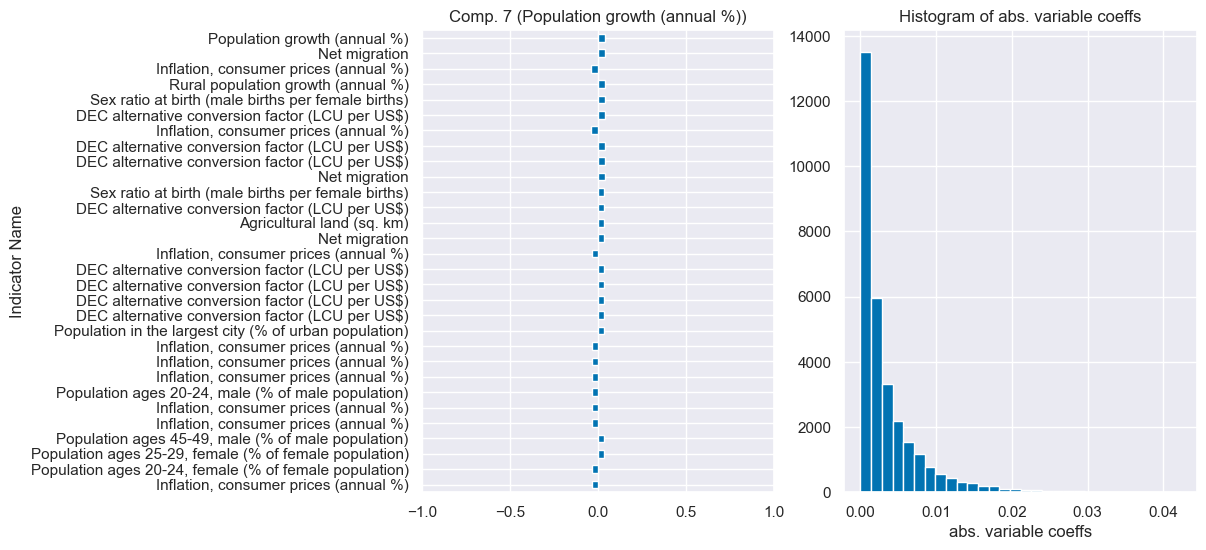

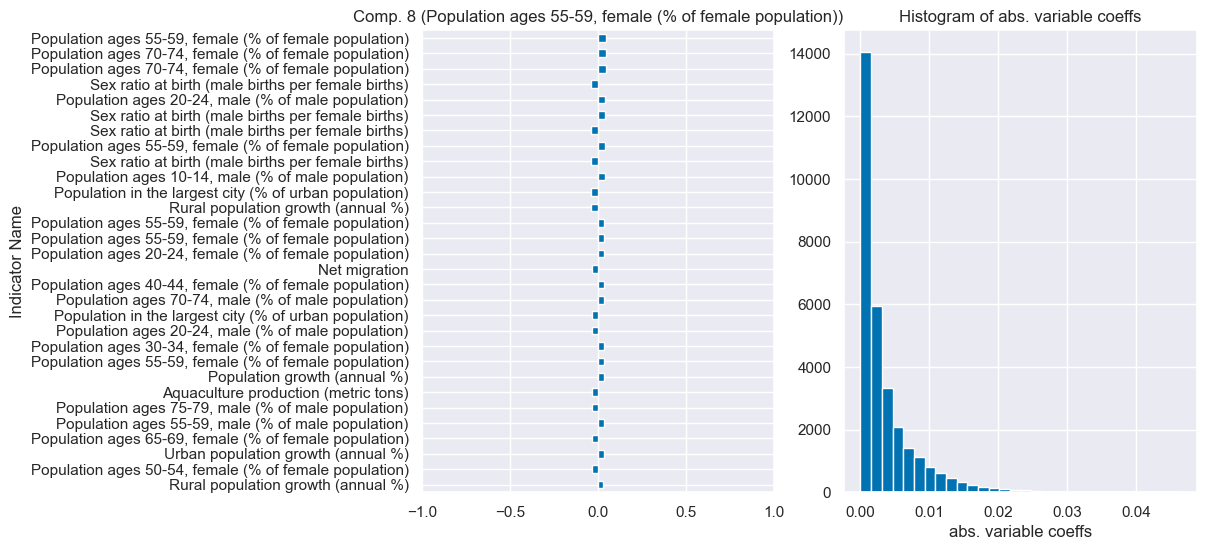

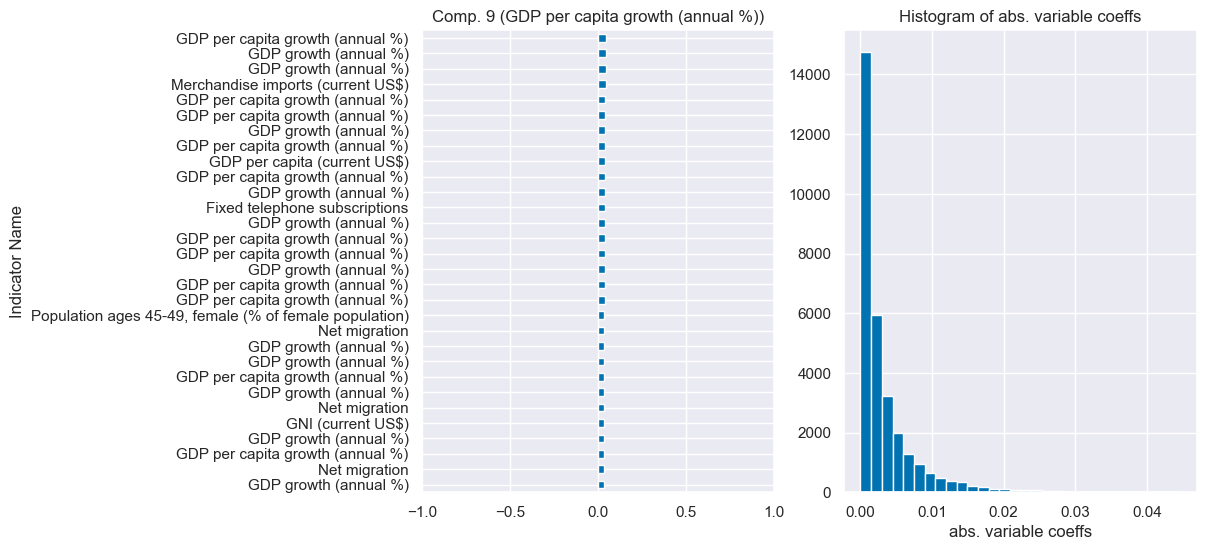

In [963]:
n_components = 10

decomp = PCA(svd_solver="full",n_components =n_components )
# decomp = FactorAnalysis(n_components =n_components )
scaler = StandardScaler()
BES_std = scaler.fit_transform(wid_pca.T)
decomp.fit(BES_std)
wid_pca_decomp = decomp.transform(BES_std)
# BES_decomp  = pd.DataFrame(BES_decomp,index=BES_num.index)
cols = wid_pca.T.columns
(BES_decomp, comp_labels, comp_dict) = display_components(n_components, decomp, cols, wid_pca_decomp,
                                                          show_first_x_comps=n_components);

In [ ]:
# PCA/FA on wdi indicators - accidentally did it in terms of years ... even after standardising, it's 2019-2023

In [975]:
pd.DataFrame(BES_decomp).corr()

## this is a *global* PCA on traits
# -> we can 

,0,1,2,3,4,5,6,7,8,9
0,1.000000,0.035206,-0.019757,0.008425,-0.002444,-0.020111,0.026266,-0.020883,-0.027180,0.020734
1,0.035206,1.000000,0.018554,-0.007912,0.002295,0.018886,-0.024666,0.019611,0.025524,-0.019471
2,-0.019757,0.018554,1.000000,0.004440,-0.001288,-0.010599,0.013842,-0.011005,-0.014324,0.010927
3,0.008425,-0.007912,0.004440,1.000000,0.000549,0.004520,-0.005903,0.004693,0.006108,-0.004660
4,-0.002444,0.002295,-0.001288,0.000549,1.000000,-0.001311,0.001712,-0.001362,-0.001772,0.001352
5,-0.020111,0.018886,-0.010599,0.004520,-0.001311,1.000000,0.014090,-0.011203,-0.014580,0.011123
6,0.026266,-0.024666,0.013842,-0.005903,0.001712,0.014090,1.000000,0.014631,0.019043,-0.014527
7,-0.020883,0.019611,-0.011005,0.004693,-0.001362,-0.011203,0.014631,1.000000,-0.015140,0.011550
8,-0.027180,0.025524,-0.014324,0.006108,-0.001772,-0.014580,0.019043,-0.015140,1.000000,0.015032
9,0.020734,-0.019471,0.010927,-0.004660,0.001352,0.011123,-0.014527,0.011550,0.015032,1.000000


In [981]:
comp_dict[0]['components_']

Indicator Name
Renewable internal freshwater resources, total (billion cubic meters)    0.000000
DEC alternative conversion factor (LCU per US$)                          0.000000
Average precipitation in depth (mm per year)                             0.000000
Renewable internal freshwater resources, total (billion cubic meters)    0.000000
Renewable internal freshwater resources, total (billion cubic meters)    0.000000
                                                                           ...   
Population ages 15-64, female                                            0.007067
Population ages 15-64, total                                             0.007067
Population ages 15-64, male                                              0.007067
Population, total                                                        0.007067
Population, male                                                         0.007067
Name: components_, Length: 30993, dtype: float64

In [1026]:
# wid_pca

In [978]:
comp_dict[0]

,components_,comp_absmag
Indicator Name,,
"Renewable internal freshwater resources, total (billion cubic meters)",0.000000,0.000000
DEC alternative conversion factor (LCU per US$),0.000000,0.000000
Average precipitation in depth (mm per year),0.000000,0.000000
"Renewable internal freshwater resources, total (billion cubic meters)",0.000000,0.000000
"Renewable internal freshwater resources, total (billion cubic meters)",0.000000,0.000000
...,...,...
"Population ages 15-64, female",0.007067,0.007067
"Population ages 15-64, total",0.007067,0.007067
"Population ages 15-64, male",0.007067,0.007067


In [967]:
cols

Index(['Adolescent fertility rate (births per 1,000 women ages 15-19)',
       'Age dependency ratio (% of working-age population)',
       'Age dependency ratio, old (% of working-age population)',
       'Age dependency ratio, young (% of working-age population)',
       'Agricultural land (sq. km)', 'Aquaculture production (metric tons)',
       'Birth rate, crude (per 1,000 people)',
       'Capture fisheries production (metric tons)',
       'Death rate, crude (per 1,000 people)',
       'Fertility rate, total (births per woman)',
       ...
       'Sex ratio at birth (male births per female births)',
       'Surface area (sq. km)', 'Survival to age 65, female (% of cohort)',
       'Survival to age 65, male (% of cohort)',
       'Total fisheries production (metric tons)',
       'Total reserves (includes gold, current US$)',
       'Total reserves minus gold (current US$)', 'Urban population',
       'Urban population (% of total population)',
       'Urban population growth (an

In [968]:
wid_pca.T

Indicator Name,"Adolescent fertility rate (births per 1,000 women ages 15-19)",Age dependency ratio (% of working-age population),"Age dependency ratio, old (% of working-age population)","Age dependency ratio, young (% of working-age population)",Agricultural land (sq. km),Aquaculture production (metric tons),"Birth rate, crude (per 1,000 people)",Capture fisheries production (metric tons),"Death rate, crude (per 1,000 people)","Fertility rate, total (births per woman)",...,Sex ratio at birth (male births per female births),Surface area (sq. km),"Survival to age 65, female (% of cohort)","Survival to age 65, male (% of cohort)",Total fisheries production (metric tons),"Total reserves (includes gold, current US$)",Total reserves minus gold (current US$),Urban population,Urban population (% of total population),Urban population growth (annual %)
1960,140.180526,89.594604,5.626944,83.668705,6170420.00,380.00,47.438554,1411417.00,20.918108,6.724125,...,1.027,390760.0,51.617663,43.317482,1300.00,8.707489e+07,6.487000e+07,479900.0,12.608,4.770006
1961,140.810248,89.873370,5.598776,83.936992,6170420.00,410.00,47.530552,1555717.00,20.681404,6.742752,...,1.027,390760.0,51.893786,43.903806,1300.00,8.707489e+07,6.487000e+07,503346.0,12.821,4.770006
1962,141.664168,90.191721,5.571718,84.243994,6167940.00,360.00,47.597558,1658417.00,20.393118,6.762930,...,1.026,390760.0,52.495371,44.487855,1300.00,8.707489e+07,6.487000e+07,529792.0,13.082,5.120667
1963,142.324951,90.574678,5.549702,84.613140,6173000.00,380.00,47.636140,1765431.00,20.254634,6.778712,...,1.027,390760.0,53.068424,45.162921,1300.00,8.707489e+07,6.487000e+07,567279.0,13.578,6.836677
1964,143.456933,90.952719,5.534236,84.994512,6170130.00,430.00,47.645480,1960723.00,19.808492,6.788420,...,1.027,390760.0,53.607703,45.661490,1900.00,8.707489e+07,6.487000e+07,607412.0,14.092,6.835606
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
2019,99.085572,82.692059,5.718424,76.028564,6891016.22,339123.60,34.341450,3535673.93,7.434644,4.482898,...,1.023,390760.0,57.729252,46.791842,46925.27,1.512405e+08,1.506267e+08,4945719.0,32.210,1.992351
2020,97.413585,81.968963,5.733111,75.310862,6898158.22,369846.12,33.916746,3491664.85,7.620548,4.416900,...,1.024,390760.0,58.110161,44.917408,47947.89,3.340502e+07,3.193753e+07,5052214.0,32.242,2.130421
2021,96.181442,81.189988,5.706199,74.565149,6900855.82,414614.85,33.546266,3737249.15,8.036899,4.354709,...,1.024,390760.0,54.307570,40.235315,27791.82,8.387802e+08,8.367310e+08,5166388.0,32.303,2.234724
2022,94.688181,80.385344,5.662353,73.799990,6900855.82,413258.19,33.142041,3366712.63,7.840951,4.288788,...,1.024,390760.0,54.538231,41.037746,34514.01,5.986216e+08,5.887763e+08,5287038.0,32.395,2.308437


In [50]:
wdi_data_ind = wdi_data.set_index(["Country Code","Indicator Name"])
wdi_data_ind['2024'] = wdi_data_ind['2023']

wdi_data_ind.loc[("USA","Inflation, GDP deflator (annual %)"),"1960"] = ((22.4/22.2)-1)*100
# temp.loc[1960] = ((22.4/22.2)-1)*100
# temp.loc[1959] = ((22.2/21.9)-1)*100
# temp.loc[1958] = ((21.9/21.6)-1)*100
# temp.loc[1957] = ((21.6/21.1)-1)*100

In [ ]:
# Inflation, GDP deflator (annual %)                   0.854852
# Inflation, consumer prices (annual %)                0.881168
# Inflation, GDP deflator: linked series (annual %)    0.527549

In [1193]:
indicator_list = ["Inflation, GDP deflator (annual %)","Inflation, consumer prices (annual %)","Inflation, GDP deflator: linked series (annual %)"]

In [1194]:
new_col_names = indicator_list
# sanitise column names for xgboost
new_col_names = [x.replace("[","").replace("]","").replace("<","") for x in new_col_names]
election_final[new_col_names] = np.nan

In [276]:
# election_final[0:3].apply(lambda x: get_wdi_rows(x["country_name_short"],x["election_year"]))

# election_final[new_col_names] = election_final.apply(lambda x: get_wdi_rows(x["country_name_short"],x["election_year"],indicator_list,0),axis=1)

In [368]:
# election_final[0:4].apply(lambda x: get_wdi_rows(x["country_name_short"],x["election_year"],indicator_list,0),axis=1)

In [1200]:
len( indicator_list )

3

In [52]:
wdi_data_ind["1957"]=np.nan
wdi_data_ind["1958"]=np.nan
wdi_data_ind["1959"]=np.nan


In [1289]:
%%time
for ind_var in indicator_list:
    election_final[ind_var] = election_final.apply(lambda x: wdi_data_ind.loc[(x["country_name_short"],ind_var),str(x["election_year"]-1)],axis=1)

CPU times: total: 312 ms
Wall time: 743 ms


In [1230]:
election_final["country_name_short"][mask].value_counts()

country_name_short
BEL    31
CHE    24
NLD    21
AUS    20
DNK    20
FIN    20
ISR    20
DEU    17
ISL    15
ITA    15
NOR    14
FRA    13
SWE    10
LUX    10
IRL    10
AUT     9
JPN     9
NZL     9
CAN     9
GBR     7
PRT     7
USA     7
MLT     5
GRC     3
ESP     2
CYP     2
Name: count, dtype: int64

In [1315]:
# # Didn't work!
# for year in range(1964,2025):
#     for country in election_final["country_name_short"].unique():
#         conpound_con_inf = 100
#         conpound_con_inf = conpound_con_inf* ((100+wdi_data_ind.loc[(country,"Inflation, consumer prices (annual %)"),str(year-2)])/100)
#         conpound_con_inf = conpound_con_inf* ((100+wdi_data_ind.loc[(country,"Inflation, consumer prices (annual %)"),str(year-1)])/100)
#         conpound_con_inf = conpound_con_inf* ((100+wdi_data_ind.loc[(country,"Inflation, consumer prices (annual %)"),str(year)])/100)
#         conpound_con_inf = conpound_con_inf-100
#         wdi_data_ind.loc[(country,"Inflation, consumer prices (3-year-compund)"),str(year)] = conpound_con_inf
    

In [1316]:
# wdi_data_ind.loc[("USA","Inflation, consumer prices (3-year-compund)"),:].dropna()

# indicator_list = indicator_list+["Inflation, consumer prices (3-year-compund)"]

In [1327]:
indicator_list = ['Inflation, GDP deflator (annual %)',
 'Inflation, consumer prices (annual %)',
 'Inflation, GDP deflator: linked series (annual %)',
]

In [1329]:
%%time
for ind_var in indicator_list:
    election_final[ind_var] = election_final\
    .apply(lambda x: wdi_data_ind.loc[(x["country_name_short"],ind_var),str(x["election_year"]-2)],axis=1)


mask =  (election_final['incumbency']>=1)\
    &(election_final['election_type']=='parliament')\
    &(election_final['country_name_short'].isin(["GBR",]))\
    &(election_final['election_year']>=2000)



print(mask.sum())
# election_final.select_dtypes('number')[mask].corrwith(election_final["vote_share_change"][mask])\
#     .drop(["vote_share_change","vote_share","vote_share_previous"]).dropna().sort_values()

name="coal_vote_share_change"
# name="vote_share_frac"
# name="coal_vote_frac_change"
pattern = pattern

df, corr_type = make_corr_summary(election_final.drop(drop_list,axis=1)[mask], name, pattern=pattern,
                                  min_sample_size=5,min_p_value=.9)
display_corr(df,name,corr_type)


8


,r,p,N
coal_vote_frac_change,1.000000,0.00,8
vote_share_frac,0.780000,0.02,8
pm_party,0.330000,0.42,8
incumbency,0.330000,0.42,8
left_right,0.150000,0.72,8
election_year,-0.160000,0.71,8
"Inflation, consumer prices (3-year-compund)",-0.350000,0.40,8
"Inflation, consumer prices (annual %)",-0.610000,0.11,8
"Inflation, GDP deflator (annual %)",-0.780000,0.02,8
"Inflation, GDP deflator: linked series (annual %)",-0.780000,0.02,8


CPU times: total: 266 ms
Wall time: 820 ms


In [ ]:
# Now trying with "3-year compound consumer prices"
# USA >=2000 -0 year: Inflation, consumer prices (annual %)	-0.54, Inflation, consumer prices (3-year-compund)	-0.54
# USA >=2000 -1 year: Inflation, consumer prices (3-year-compund)	-0.25,Inflation, consumer prices (annual %)	-0.39

# USA -0 year: Inflation, GDP deflator: linked	-0.41;Inflation, consumer prices -0.29;Inflation, GDP deflator -0.27
# USA -1 year: Inflation, GDP deflator: linked	-0.47;Inflation, consumer prices -0.36;Inflation, GDP deflator -0.34
# USA -2 year: Inflation, GDP deflator: linked	-0.55;Inflation, consumer prices -0.36;Inflation, GDP deflator -0.33
# USA -3 year: Inflation, GDP deflator: linked	-0.17;Inflation, consumer prices -0.18;Inflation, GDP deflator -0.14 p>.5!

# UK -0 year: Inflation, GDP deflator: linked	-0.18;Inflation, consumer prices --;Inflation, GDP deflator -0.11
# UK -1 year: Inflation, GDP deflator: linked	-;Inflation, consumer prices +.07;Inflation, GDP deflator +.14
# UK -2 year: Inflation, GDP deflator: linked	-0.18;Inflation, consumer prices --;Inflation, GDP deflator -0.11

# global -1 year: Inflation, GDP deflator: linked	-0.06;Inflation, consumer prices+.03;Inflation, GDP deflator .01
# global -2 year: Inflation, GDP deflator: linked	-0.04;Inflation, consumer prices+.01;Inflation, GDP deflator .02

# DEU -1 year: Inflation, GDP deflator: linked	+.35;Inflation, consumer prices +.28;Inflation, GDP deflator +.56
# DEU -2 year: Inflation, GDP deflator: linked	-0.31;Inflation, consumer prices +.22;Inflation, GDP deflator +.15

# FRA -1 year: Inflation, GDP deflator: linked	+.2;Inflation, consumer prices +.27;Inflation, GDP deflator +.35
# FRA -2 year: Inflation, GDP deflator: linked	+.09;Inflation, consumer prices +.11;Inflation, GDP deflator -.22
################################ - <=1985
# USA -0 year: Inflation, GDP deflator: linked	-;Inflation, consumer prices -0.54;Inflation, GDP deflator -0.54
# USA -1 year: Inflation, GDP deflator: linked	-;Inflation, consumer prices -0.14;Inflation, GDP deflator -0.2
# USA -2 year: Inflation, GDP deflator: linked	-;Inflation, consumer prices -0.31;Inflation, GDP deflator -0.31
# USA -3 year: Shit
################################ - >=2000
# USA -0 year: Inflation, GDP deflator: linked	-;Inflation, consumer prices -0.54;Inflation, GDP deflator -
# USA -1 year: Inflation, GDP deflator: linked	-.46;Inflation, consumer prices -0.39;Inflation, GDP deflator -0.46
# USA -2 year: Inflation, GDP deflator: linked	-.57;Inflation, consumer prices -0.64;Inflation, GDP deflator -0.57
# USA -3 year: Shit


In [ ]:
# just looking at inf variables

# USA vote_share_change > vore_share_frac for USA, Inflation, consumer prices (annual %) best
# GBR same, but better for coal, GDP deflator best
# AUS Inflation, GDP deflator: linked series (annual %)	-0.150000	0.49	22 # weak
# NZL Inflation, GDP deflator: linked series (annual %)	-0.35, Inflation, consumer prices (annual %)	-0.22, Inflation, GDP deflator (annual %)	-0.19
# CAN Inflation, GDP deflator: linked series (annual %)	0.71, Inflation, GDP deflator (annual %)	0.48, Inflation, consumer prices (annual %)	0.37
# DEU Inflation, GDP deflator (annual %)
# FRA Inflation, GDP deflator: linked series (annual %)
# FIN Inflation, Inflation, GDP deflator: linked series (annual %)	-0.62,consumer prices (annual %)	+0.22, Inflation, GDP deflator (annual %)	0.1
    ## -.62 on 'linked' series N=35 but +.22 on consumer N=59!!
# ISR Inflation, Inflation, GDP deflator (annual %)	-0.27,Inflation, consumer prices (annual %)	-0.19,GDP deflator: linked series (annual %)	-0.12,
# IRL Inflation, consumer prices (annual %)	0.51,Inflation, GDP deflator (annual %)	0.5,Inflation, GDP deflator: linked series (annual %)	0.38
# ITA Inflation, GDP deflator (annual %)	0.12
# SWE Inflation, consumer prices (annual %)	0.25
# NOR Inflation, GDP deflator: linked series (annual %)	-0.48, Inflation, GDP deflator (annual %)	-0.35,
#     Inflation, consumer prices (annual %)	+.26!!!

# global - barely any inflat effect, Inflation, GDP deflator: linked series (annual %)	-0.05
    # none, if you restrict to > 2000
    # bigger if restrict to <1985, Inflation, GDP deflator (annual %) best
## looks mostly like period effects

## <=1985
# USA, Inflation, GDP deflator (annual %), Inflation, consumer prices (annual %) -.54
# GBR, Inflation, GDP deflator (annual %), Inflation, consumer prices (annual %) -.45
# FRA -
# DEU Inflation, consumer prices (annual %) +.39, Inflation, GDP deflator (annual %) +.32
# BEL Inflation, GDP deflator (annual %) +.39, Inflation, consumer prices (annual %) +.33
# CHE Inflation, consumer prices (annual %)	+0.2
# NLD Inflation, consumer prices (annual %)	+0.23
# AUS -.# NZL -#IRL -
# CAN - Inflation, GDP deflator (annual %)	+0.67, Inflation, consumer prices (annual %)	+0.47
# DNK - Inflation, consumer prices (annual %)	0.23
# FIN - Inflation, consumer prices (annual %)	0.940000	0.00	20(!!!),Inflation, GDP deflator (annual %)	0.73
# ISR - Inflation, consumer prices (annual %)	-0.61,Inflation, GDP deflator (annual %)	-0.67
# SWE - Inflation, consumer prices (annual %)	-0.68, Inflation, GDP deflator (annual %)	-0.56
    # NOR -

In [ ]:
# FRA - demographics + Net Migration
# DEU - Inflation, GDP deflator (annual %)	0.33, Death rate, crude (per 1,000 people)	0.31, Surface area (sq. km)	-0.31

In [1079]:
# Restrict to just GBR
# Fixed telephone subscriptions	-0.290000	0.27	17
# GDP per capita (current US$)	-0.280000	0.28	17 - WTF!
# pm_party	0.360000	0.16	17 # if you're in a coalition, best to be in driving seat!

In [ ]:
# Restrict to just USA
# Sex ratio at birth (male births per female births)	-0.44000 ???
# Inflation, consumer prices (annual %)	-0.410000	0.11	17
# Inflation, GDP deflator (annual %)	-0.290000	0.25	17
# GDP growth (annual %)	0.270000	0.31	16

In [ ]:
# Restrict to just >=2000, 'vote_share_change'
# election_year disappears, Net migration ++ (still pos!), rural pop % ++ (-.16)
# GDP/capita -> .12-1.14
# bunch of age/pop/birth demographics

In [ ]:
# Restrict to just <=1980, 'vote_share_change'
# Inflation, GDP deflator (annual %)	-0.18  BOOM (bigger for just 60-70s, falls off when you get to 90s)
# can just about see it for >=2019

In [ ]:
# incumbency, pm_party, cabinet_party?,coal_member
# vote_share_frac, coal_vote_frac_change, vote_share, vote_share_previous, coal_vote_share_change, vote_share_change
# election_year
# left_right
# Net migration
# Consumer price index (2010 = 100)
# Population ages ...
# Population growth (annual %), Birth rate, crude (per 1,000 people), Fertility rate, total (births per woman)
# GDP per capita (constant 2015 US$), GDP per capita (constant LCU), GDP (constant 2015 US$), GDP (constant LCU)
# Rural population (% of total population), urban population (% of total population), Urban population growth (annual %)?, Rural population

In [ ]:
# vote_share_change corr election_year = -.09
# vote_share_frac corr election_year = -.14

# coal_vote_frac_change, coal_vote_share_change
#     -> election year, Net migration

# election_year -> Consumer price index (2010 = 100)
    # could just chuck all of these > cut off to reduce period confound?

In [ ]:
wdi_data_ind["1957"]=np.nan
wdi_data_ind["1958"]=np.nan
wdi_data_ind["1959"]=np.nan

194

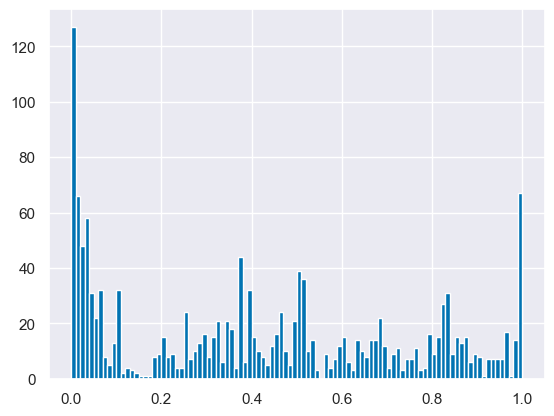

In [96]:
country_list = election_manual["country_name_short"].unique()

country_list = [x for x in country_list if x not in ["BGR","LTU","LVA","MLT","EST","SVN","GRC","JPN","ISR","CYP",
                                                 "CZE","SVK","ROU"]]

country_mask = wdi_data['Country Code'].isin( country_list )

temp = (wdi_data[country_mask][wdi_data.columns[-64:]].notnull().sum(axis=1).groupby(wdi_data[country_mask]["Indicator Name"]).mean()/64)
indicator_list = list( temp[temp>.85].index )
temp.hist(bins=100);
len(indicator_list)

In [100]:
# 
# election_final = election_final.drop(indicator_list,axis=1)
for ind_var in indicator_list:
    election_final[ind_var] = election_final\
    .apply(lambda x: wdi_data_ind.loc[(x["country_name_short"],ind_var),str(x["election_year"]-2)],axis=1)

temp = election_final[mask].drop(drop_list+extra_drop_list,axis=1).drop_duplicates()
df, corr_type = make_corr_summary(temp, name, pattern=pattern,min_sample_size=20,min_p_value=.2)
indicator_list = [x for x in indicator_list if x in df.index]
election_final = election_final.drop(indicator_list,axis=1)
len(indicator_list)

19

In [101]:
indicator_list = indicator_list + ["Inflation, consumer prices (annual %)","Net migration","GDP growth (annual %)"]

In [116]:
# 
# election_final = election_final.drop(indicator_list,axis=1)
for ind_var in indicator_list:
    election_final[ind_var] = election_final\
    .apply(lambda x: wdi_data_ind.loc[(x["country_name_short"],ind_var),str(x["election_year"]-2)],axis=1)

In [103]:
indicator_list

['Aquaculture production (metric tons)',
 'DEC alternative conversion factor (LCU per US$)',
 'Electricity production from renewable sources, excluding hydroelectric (% of total)',
 'GDP growth (annual %)',
 'GDP per capita growth (annual %)',
 'Livestock production index (2014-2016 = 100)',
 'Merchandise exports to economies in the Arab World (% of total merchandise exports)',
 'Merchandise exports to low- and middle-income economies in East Asia & Pacific (% of total merchandise exports)',
 'Merchandise exports to low- and middle-income economies in Europe & Central Asia (% of total merchandise exports)',
 'Merchandise exports to low- and middle-income economies in Latin America & the Caribbean (% of total merchandise exports)',
 'Merchandise exports to low- and middle-income economies in Middle East & North Africa (% of total merchandise exports)',
 'Merchandise imports from economies in the Arab World (% of total merchandise imports)',
 'Merchandise imports from low- and middle-inc

In [115]:
election_final.drop(election_final.columns[32:],axis=1,inplace=True)

In [359]:
# election_final.columns[0:50]

In [45]:
drop_list = ['country_name_short', 'country_name', 'election_type', 'election_date',
       'vote_share', 'seats', 'seats_total', 'party_name_short', 'party_name',
       'party_name_english', 'country_id', 'election_id',
       'previous_parliament_election_id', 'previous_cabinet_id', 'party_id',
       'vote_share_previous',
        'election_datetime', 'manual',
       'turnout',]

# 'left_right',  'cabinet_party', 'pm_party','election_year', 'presidential', 'vote_share_change',

In [344]:
election_final.select_dtypes('number').corrwith(election_final.select_dtypes('number')["vote_share_change"]).sort_values().head(20)

vote_share_previous                                             -0.295743
cabinet_party                                                   -0.262084
pm_party                                                        -0.242199
turnout                                                         -0.111991
Mortality rate, adult, male (per 1,000 male adults)             -0.044906
Death rate, crude (per 1,000 people)                            -0.038006
Inflation, consumer prices (annual %)                           -0.036562
Inflation, GDP deflator (annual %)                              -0.033565
Rural population (% of total population)                        -0.030889
Population ages 35-39, male (% of male population)              -0.029954
Mortality rate, adult, female (per 1,000 female adults)         -0.028782
Adolescent fertility rate (births per 1,000 women ages 15-19)   -0.027315
Population, female (% of total population)                      -0.026631
Population ages 60-64, female (% of fe

In [345]:
election_final.select_dtypes('number').corrwith(election_final.select_dtypes('number')["vote_share_change"]).sort_values().tail(20)

Population ages 10-14, female (% of female population)    0.016271
Fertility rate, total (births per woman)                  0.016515
GDP per capita (current US$)                              0.018696
Life expectancy at birth, total (years)                   0.021352
GDP per capita growth (annual %)                          0.022027
seats_total                                               0.023035
Life expectancy at birth, male (years)                    0.025516
Net migration                                             0.025662
Population, male (% of total population)                  0.026631
Urban population (% of total population)                  0.030889
GDP growth (annual %)                                     0.031742
Survival to age 65, male (% of cohort)                    0.034869
Urban population growth (annual %)                        0.036484
GDP per capita (constant 2015 US$)                        0.039074
Population growth (annual %)                              0.04

In [107]:
len( indicator_list )

22

In [68]:
# election_final[mask]["country_name_short"].value_counts()

In [43]:
country_dummies = pd.get_dummies(election_final["country_name_short"]).astype('float')
election_final[country_dummies.columns] = country_dummies

In [63]:
election_final = election_final.drop(country_dummies.columns,axis=1)

In [108]:
# election_final[country_dummies.columns]
election_final.columns

Index(['country_name_short', 'country_name', 'election_type', 'election_date',
       'vote_share', 'seats', 'seats_total', 'party_name_short', 'party_name',
       'party_name_english',
       ...
       'Merchandise exports to low- and middle-income economies in Latin America & the Caribbean (% of total merchandise exports)',
       'Merchandise exports to low- and middle-income economies in Middle East & North Africa (% of total merchandise exports)',
       'Merchandise imports from economies in the Arab World (% of total merchandise imports)',
       'Merchandise imports from low- and middle-income economies in East Asia & Pacific (% of total merchandise imports)',
       'Merchandise imports from low- and middle-income economies in South Asia (% of total merchandise imports)',
       'Net migration', 'Ores and metals exports (% of merchandise exports)',
       'Total fisheries production (metric tons)',
       'Total reserves (includes gold, current US$)',
       'Total reserves 

,r,p,N
Merchandise exports to economies in the Arab World[...],0.170000,0.01,257
Merchandise exports to low- and middle-income[...],0.170000,0.01,257
,r,p,N
Merchandise exports to economies in the Arab World[...],0.170000,0.01,257
Merchandise exports to low- and middle-income[...],0.170000,0.01,257


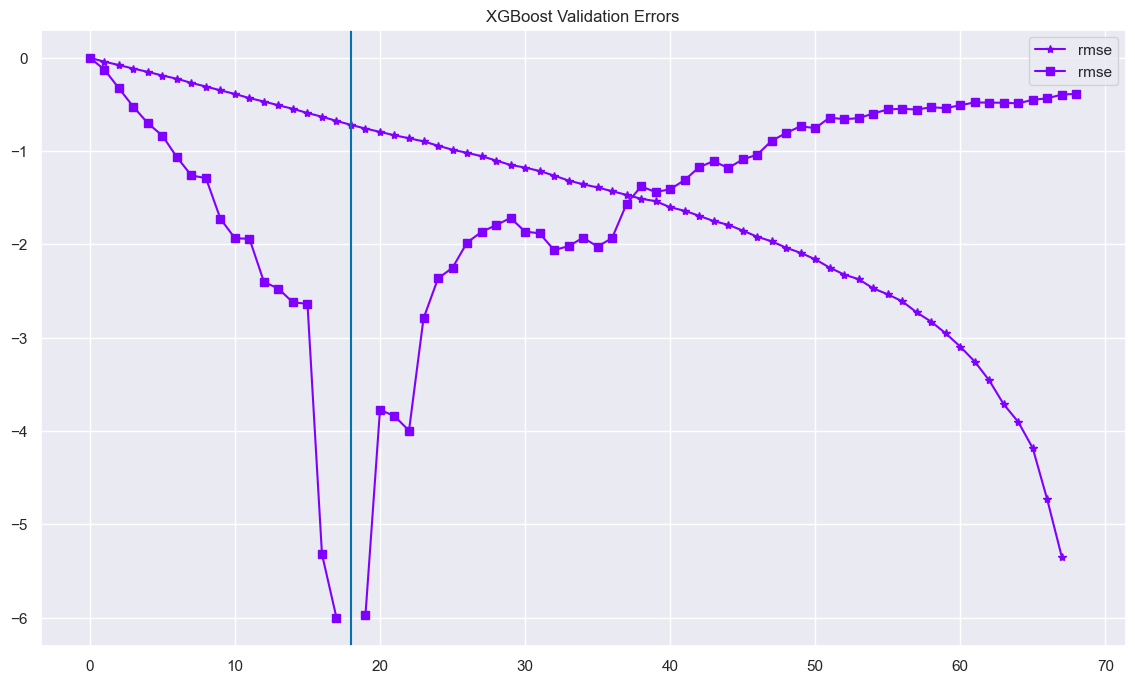

MSE: 67.92, MAE: 5.87, EV: -0.12, R2: -0.21


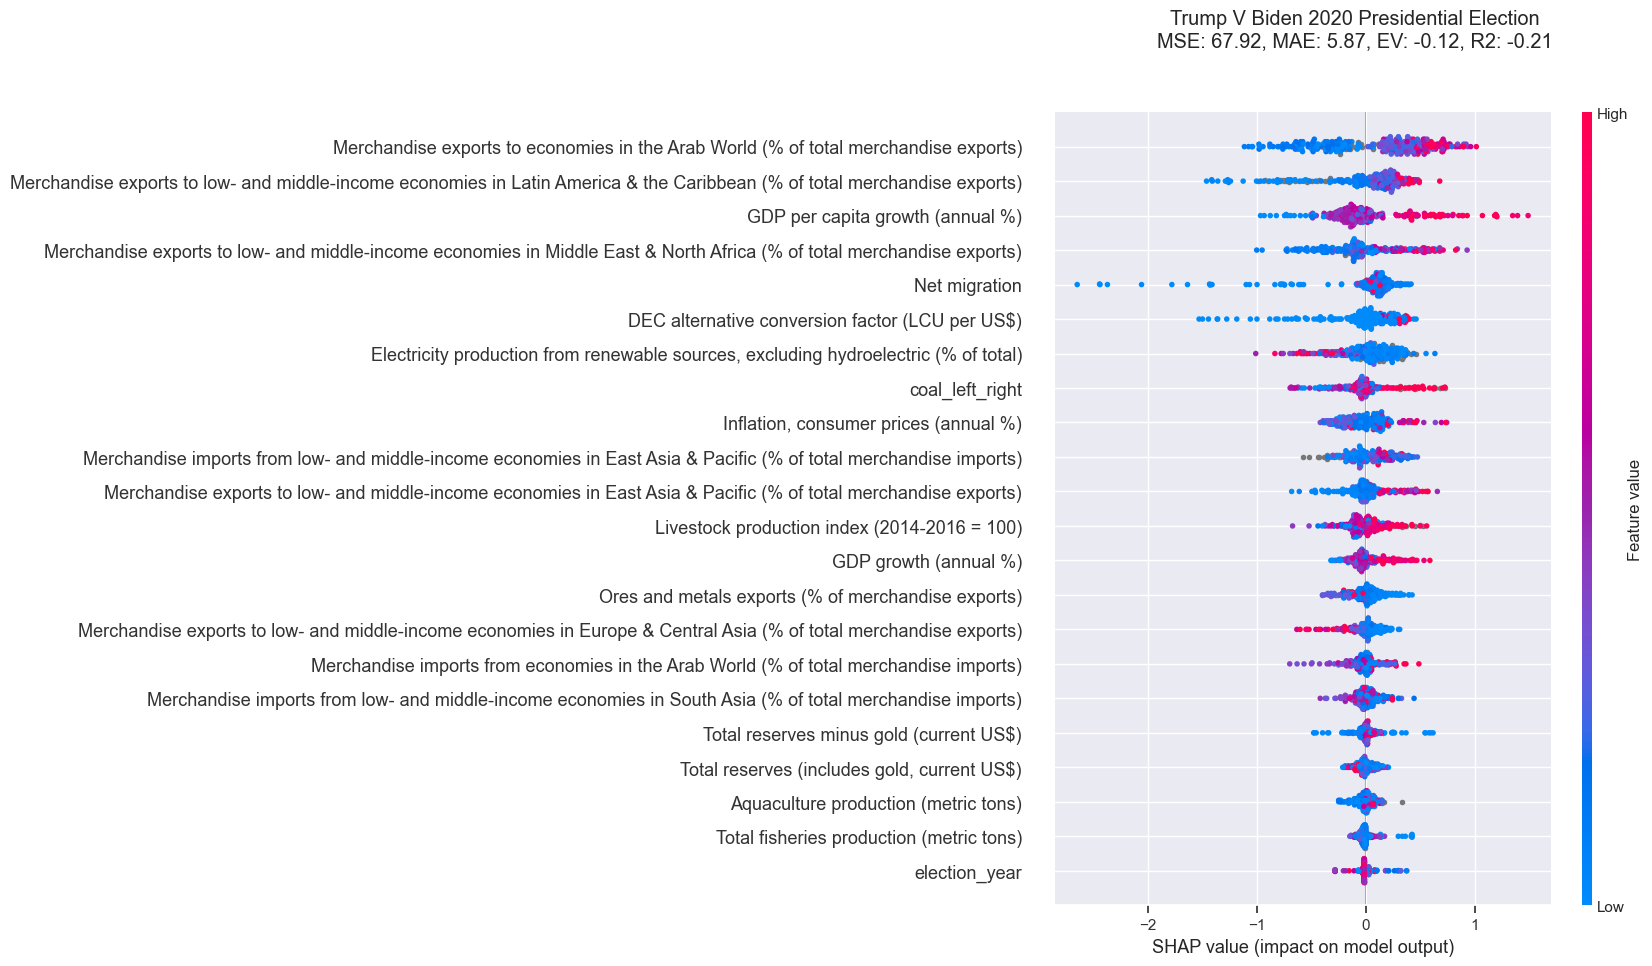

<Figure size 1600x1000 with 0 Axes>

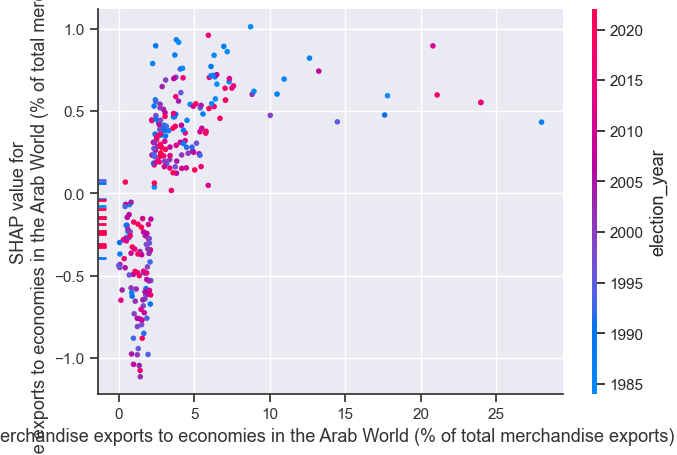

<Figure size 1600x1000 with 0 Axes>

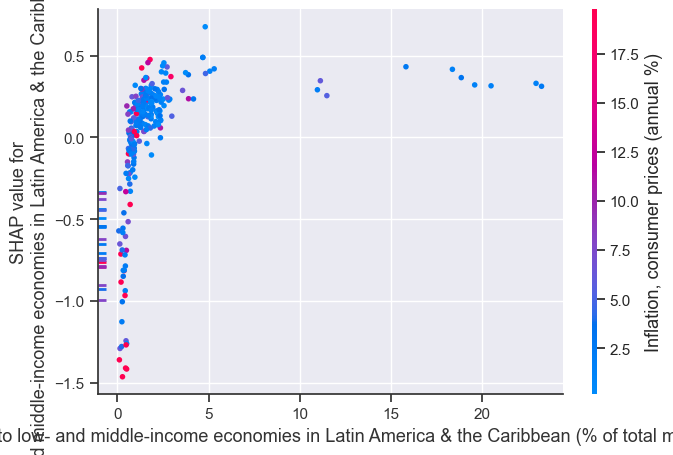

<Figure size 1600x1000 with 0 Axes>

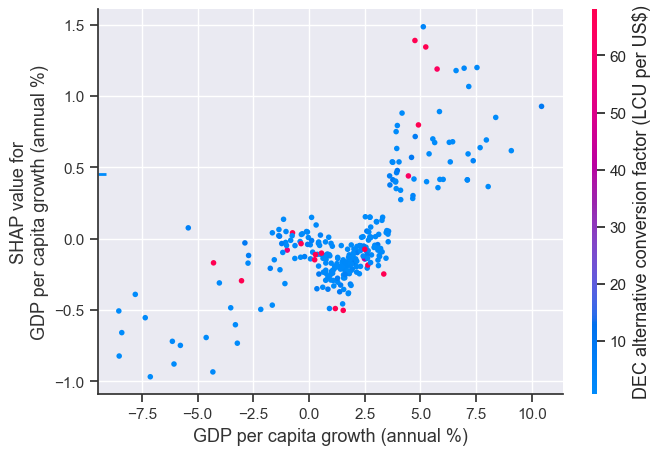

<Figure size 1600x1000 with 0 Axes>

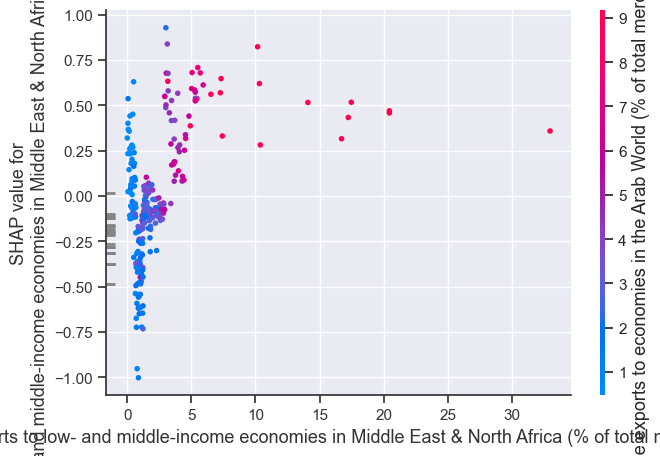

<Figure size 1600x1000 with 0 Axes>

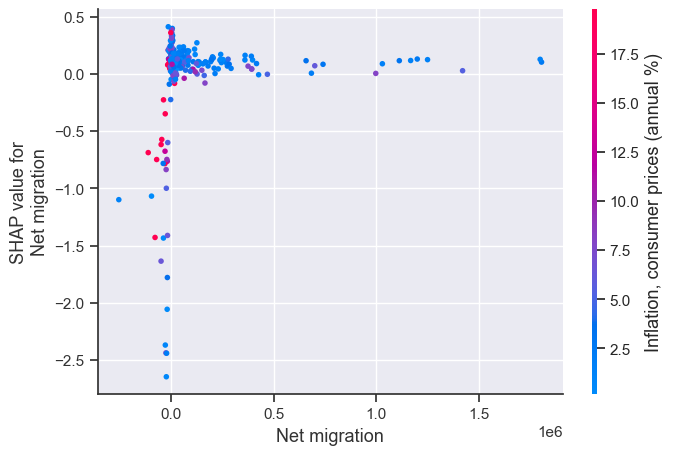

<Figure size 1600x1000 with 0 Axes>

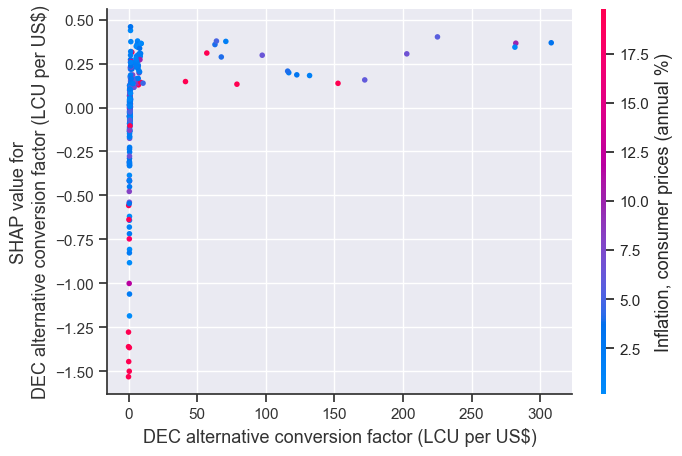

<Figure size 1600x1000 with 0 Axes>

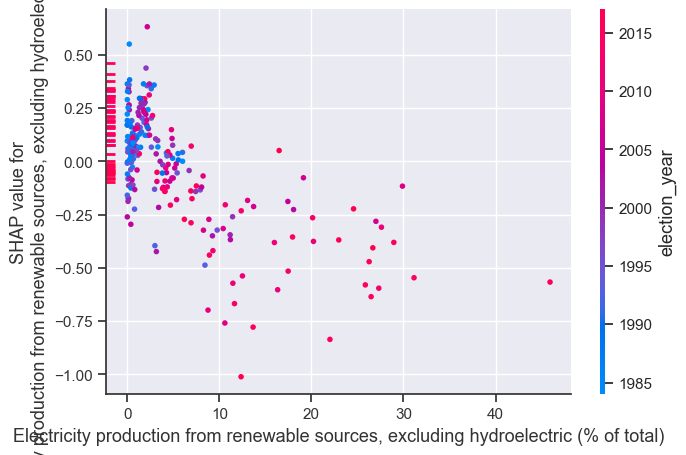

<Figure size 1600x1000 with 0 Axes>

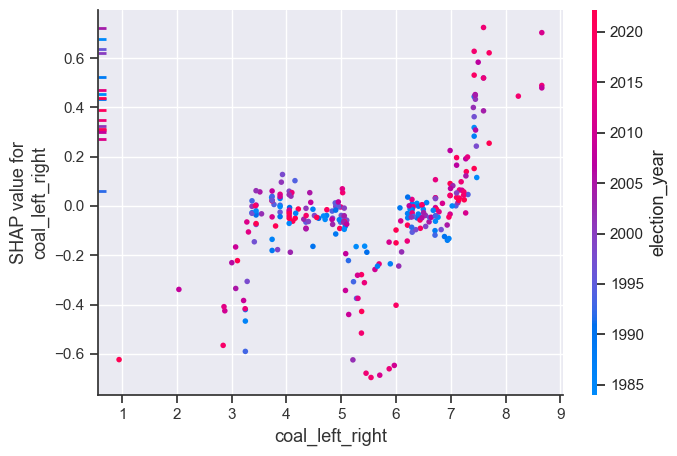

<Figure size 1600x1000 with 0 Axes>

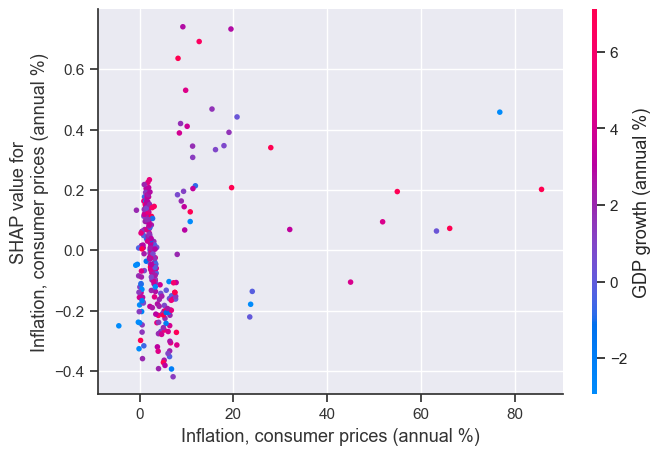

<Figure size 1600x1000 with 0 Axes>

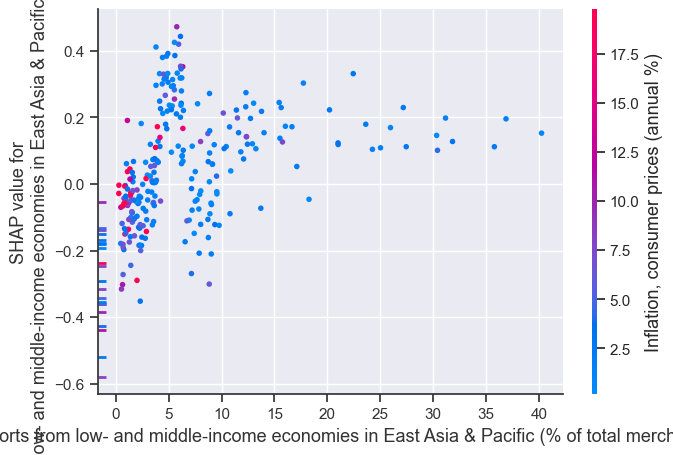

<Figure size 1600x1000 with 0 Axes>

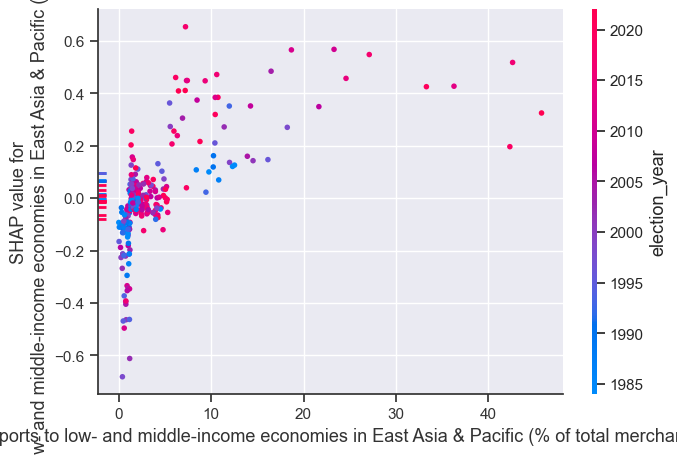

<Figure size 1600x1000 with 0 Axes>

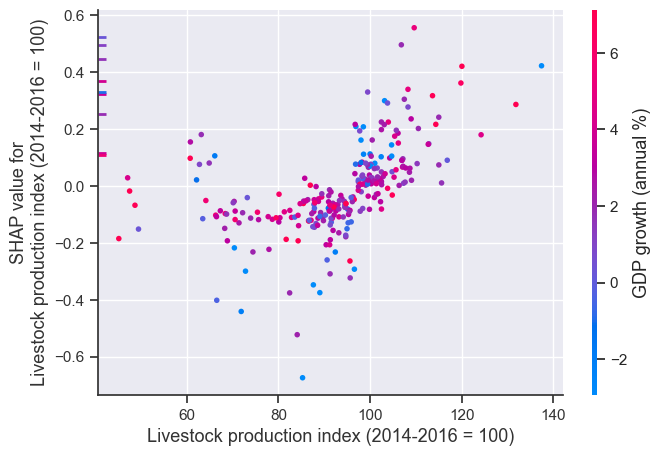

<Figure size 1600x1000 with 0 Axes>

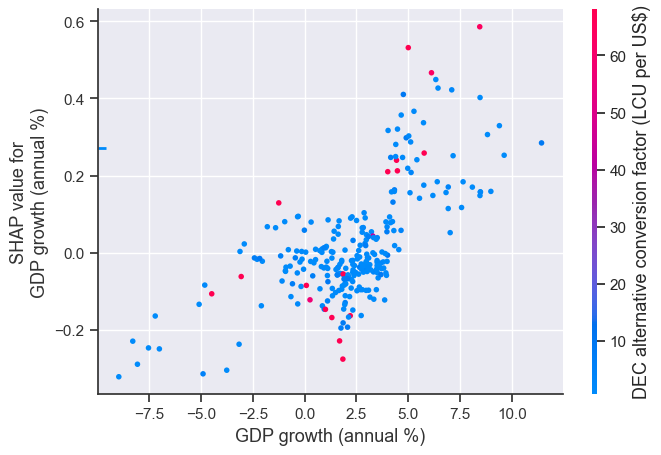

<Figure size 1600x1000 with 0 Axes>

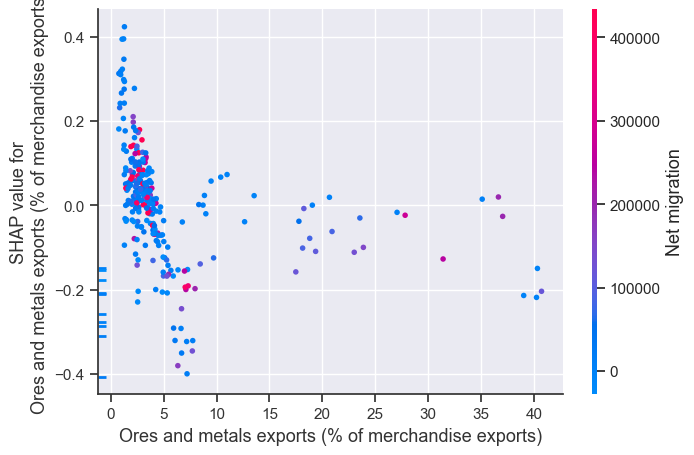

<Figure size 1600x1000 with 0 Axes>

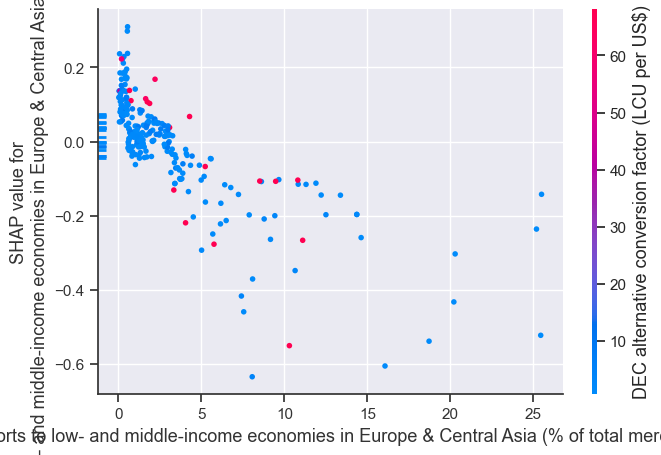

<Figure size 1600x1000 with 0 Axes>

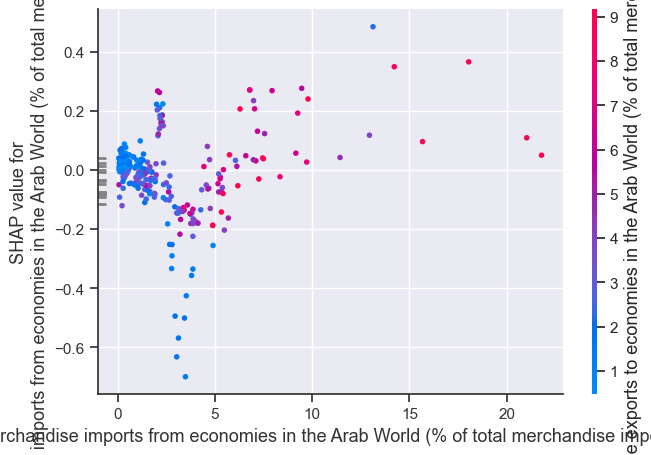

<Figure size 1600x1000 with 0 Axes>

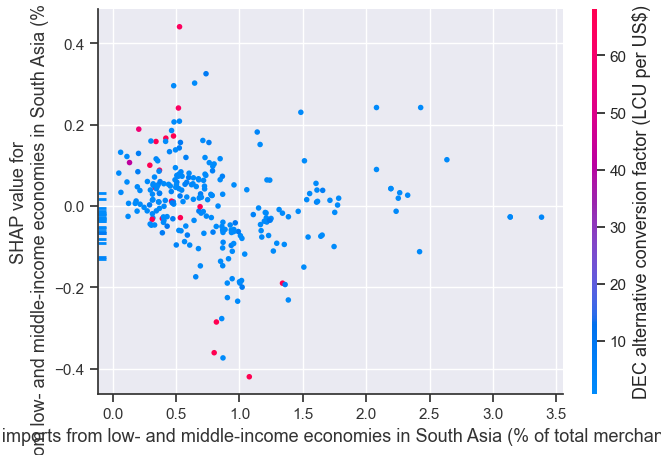

<Figure size 1600x1000 with 0 Axes>

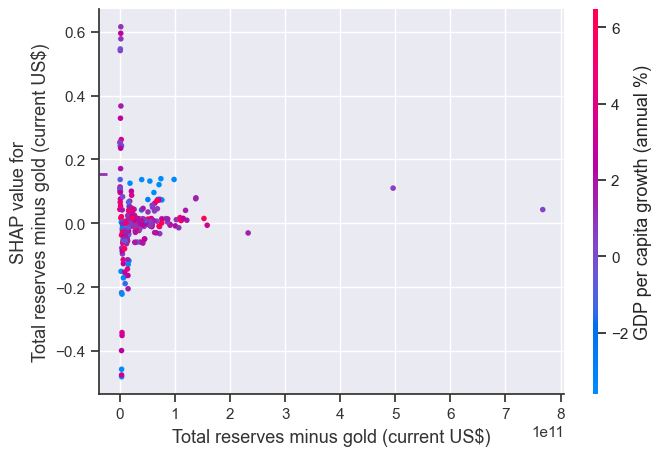

<Figure size 1600x1000 with 0 Axes>

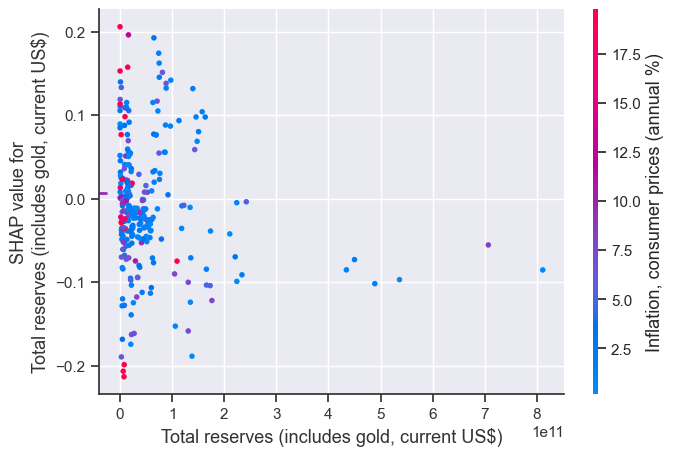

<Figure size 1600x1000 with 0 Axes>

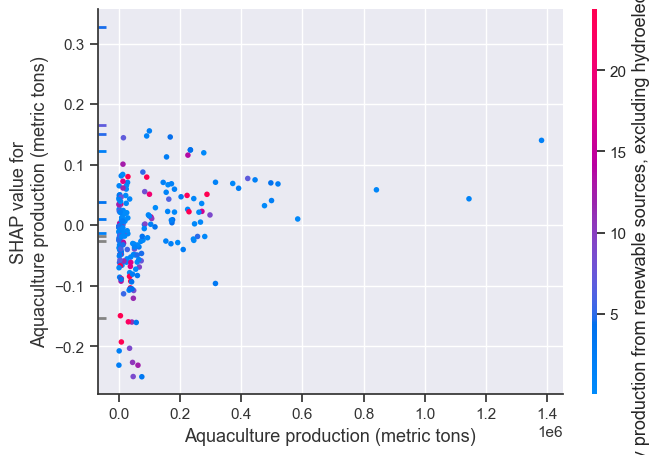

<Figure size 1600x1000 with 0 Axes>

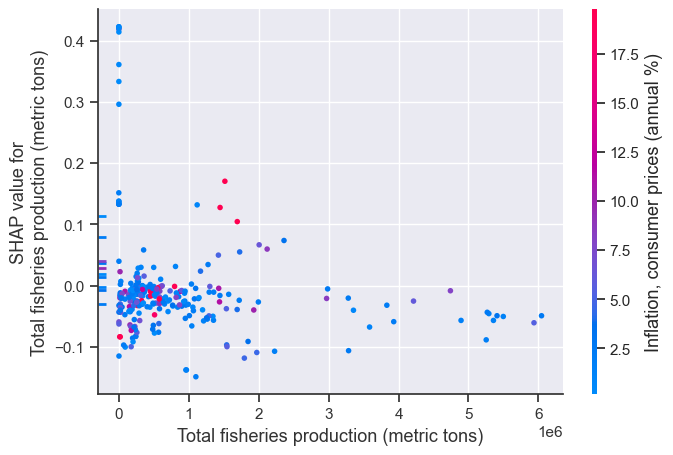

<Figure size 1600x1000 with 0 Axes>

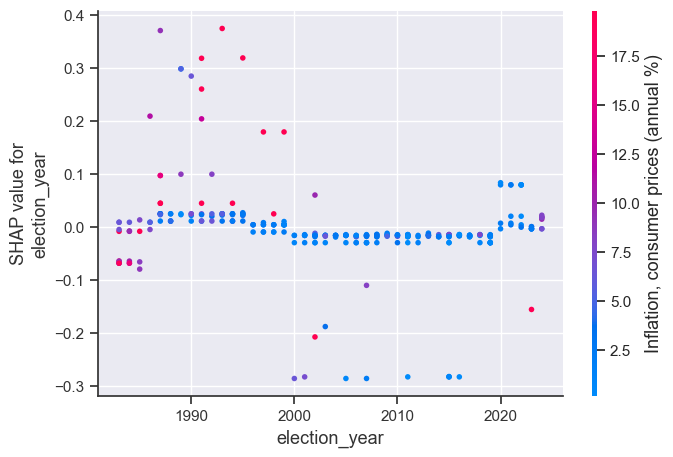

CPU times: total: 3.2 s
Wall time: 3.67 s


In [117]:
%%time
extra_drop_list = ["presidential","caretaker_party","coal_member","coal_vote_frac_change",
                   "vote_share_change","vote_share_frac","pm_party","cabinet_party","left_right","incumbency"]

name="coal_vote_share_change"
pattern = "coal_vote_share_change"
 # type = parl; vital - eu parl elections too confusing for alg!
mask =  (election_final['incumbency']>=1)\
    &(election_final['election_type']=='parliament')\
    &(election_final['election_year']>=1983)\
    &(~election_final['country_name_short'].isin(["BGR","LTU","LVA","MLT","EST","SVN","GRC","JPN","ISR","CYP",
                                                 "CZE","SVK","ROU"]))

temp = election_final[mask].drop(drop_list+extra_drop_list,axis=1).drop_duplicates()

df, corr_type = make_corr_summary(temp, name, pattern=pattern,min_sample_size=20)
display_corr(df,name,corr_type)

(explainer, shap_values, train_columns, train_index, alg,output_subfolder,metrics) = xgboost_run(
    title = "Trump V Biden 2020 Presidential Election",
                                                    dataset=temp,
                                                    var_list = [name],var_stub_list = [name,pattern                                                            
                                                         ],dependence_plots=True,plot_validation=True,
    verbosity=0)

In [ ]:
## correlates

# Net lending (+) / net borrowing (-) (% of GDP)	
# Households and NPISHs Final consumption
# Time required to start a business (days)

## all the variables R2=-.15 # Hun, Pol, Hrv, Tur outliers
    # pca 0 - GDP/cap, PPP; Employment in services, male (% of male employment), Rural population (% of total population)???
    # pca 1 - Net lending/Adjusted net savings/S&P Global Equity/Real effective exchange rate/Unemployment
    
## xgboost
# Merchandise exports to economics in the Arab World
# Communications, computer, etc. (% of service imports)/Exployment in services/Transport services/Food imports/Fuel imports/Ores and metals
# Forest area (% of land area)
# Refugee population by country or territory of asylum
# Adjust net enrollment rate
# Electricity production from renewable sources
# Sex ratio at birth



In [118]:
temp["country_name_short"] = election_final.loc[temp.index,"country_name_short"]
data = pd.DataFrame(shap_values,columns=train_columns,index=temp.apply(lambda x: (x["country_name_short"],x["election_year"]),axis=1))

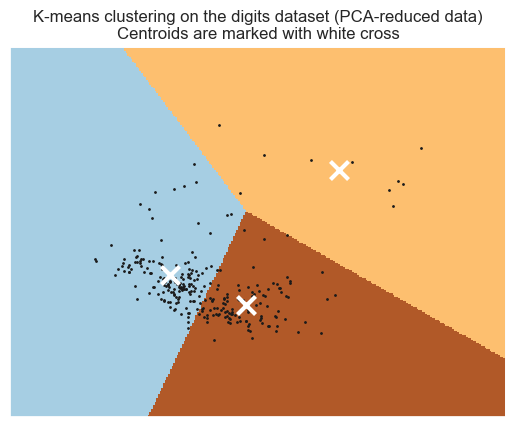

In [119]:
import matplotlib.pyplot as plt
from sklearn.cluster import KMeans
from sklearn.decomposition import PCA
n_digits = 3

reduced_data = PCA(n_components=2).fit_transform(data)
kmeans = KMeans(init="k-means++", n_clusters=n_digits, n_init=4)

kmeans.fit(reduced_data)
kmeans.cluster_centers_ = kmeans.cluster_centers_.astype(float)
# Step size of the mesh. Decrease to increase the quality of the VQ.
h = 0.02  # point in the mesh [x_min, x_max]x[y_min, y_max].

# Plot the decision boundary. For that, we will assign a color to each
x_min, x_max = reduced_data[:, 0].min() - 1, reduced_data[:, 0].max() + 1
y_min, y_max = reduced_data[:, 1].min() - 1, reduced_data[:, 1].max() + 1
xx, yy = np.meshgrid(np.arange(x_min, x_max, h), np.arange(y_min, y_max, h))

# Obtain labels for each point in mesh. Use last trained model.
Z = kmeans.predict(np.c_[xx.ravel(), yy.ravel()])

# Put the result into a color plot
Z = Z.reshape(xx.shape)
plt.figure(1)
plt.clf()
plt.imshow(
    Z,
    interpolation="nearest",
    extent=(xx.min(), xx.max(), yy.min(), yy.max()),
    cmap=plt.cm.Paired,
    aspect="auto",
    origin="lower",
)

plt.plot(reduced_data[:, 0], reduced_data[:, 1], "k.", markersize=2)
# import pylab as py
# for item in data:
#     py.scatter(reduced_data[:, 0], reduced_data[:, 1],
# #                s=700*item[1], 
# #            c=(item[2]/10.0, 0, 1 - item[2]/10.0), 
#            marker=r"$ {} $".format([x[0]+"-"+str(x[1]) for x in data.index]), edgecolors='none' )

# py.show()

# Plot the centroids as a white X
centroids = kmeans.cluster_centers_
ax = plt.scatter(
    centroids[:, 0],
    centroids[:, 1],
    marker="x",
    s=169,
    linewidths=3,
    color="w",
    zorder=10,
)

# for i, txt in enumerate(n):
#     ax.annotate(txt, (x[i], y[i]))

plt.title(
    "K-means clustering on the digits dataset (PCA-reduced data)\n"
    "Centroids are marked with white cross"
)
plt.xlim(x_min, x_max)
plt.ylim(y_min, y_max)
plt.xticks(())
plt.yticks(())
plt.show()

In [120]:
kmeans.fit(reduced_data)
kmeans.cluster_centers_ = kmeans.cluster_centers_.astype(np.float32)

data['cluster'] = kmeans.predict(reduced_data)

temp = data.reset_index()
temp["country"] = temp["index"].apply(lambda x: x[0])
temp["year"] = temp["index"].apply(lambda x: x[1])
temp["red_x"] = reduced_data[:,0]
temp["red_y"] = reduced_data[:,1]

In [ ]:
# two axes
# one all vars correlated
# two left_right/inf/migration correlated, gdp non-corre, year anti-correlated

In [121]:
data.select_dtypes('number').corrwith(pd.Series(reduced_data[:,0],index=data.index)).dropna().sort_values()

Merchandise exports to economies in the Arab World (% of total merchandise exports)                                         -0.850125
Merchandise exports to low- and middle-income economies in Middle East & North Africa (% of total merchandise exports)      -0.721102
Merchandise exports to low- and middle-income economies in Latin America & the Caribbean (% of total merchandise exports)   -0.665796
Net migration                                                                                                               -0.467244
Aquaculture production (metric tons)                                                                                        -0.374144
coal_left_right                                                                                                             -0.351261
Electricity production from renewable sources, excluding hydroelectric (% of total)                                         -0.351233
cluster                                                       

In [124]:
data.select_dtypes('number').corrwith(pd.Series(reduced_data[:,1],index=data.index)).dropna().sort_values().round(2)

Net migration                                                                                                               -0.77
DEC alternative conversion factor (LCU per US$)                                                                             -0.45
Merchandise exports to low- and middle-income economies in Europe & Central Asia (% of total merchandise exports)           -0.37
Livestock production index (2014-2016 = 100)                                                                                -0.20
Merchandise exports to low- and middle-income economies in Latin America & the Caribbean (% of total merchandise exports)   -0.19
Total reserves (includes gold, current US$)                                                                                 -0.19
election_year                                                                                                               -0.17
Merchandise exports to low- and middle-income economies in East Asia & Pacific (% of total

In [1641]:
temp.drop(["index","election_year","cluster"],axis=1).select_dtypes('number').mean().round(3)

coal_left_right                             0.008
Inflation, consumer prices (annual %)      -0.005
Net migration                               0.026
GDP growth (annual %)                      -0.005
year                                     1994.150
red_x                                      -0.000
red_y                                      -0.000
dtype: float64

In [1642]:
temp[temp["cluster"]==0].drop(["index","election_year","cluster"],axis=1).describe(include='all')

,coal_left_right,"Inflation, consumer prices (annual %)",Net migration,GDP growth (annual %),country,year,red_x,red_y
count,203.000000,203.000000,203.000000,203.000000,203,203.000000,203.000000,203.000000
unique,NaN,NaN,NaN,NaN,25,NaN,NaN,NaN
top,NaN,NaN,NaN,NaN,AUS,NaN,NaN,NaN
freq,NaN,NaN,NaN,NaN,12,NaN,NaN,NaN
mean,0.103930,0.033095,0.185797,-0.064953,NaN,2006.206897,0.310496,-0.648837
std,0.780573,0.605170,0.667946,0.534477,NaN,10.278139,0.668911,0.510407
min,-2.631378,-2.567798,-2.869369,-1.360310,NaN,1984.000000,-1.343546,-2.019495
25%,-0.366858,-0.247582,-0.159510,-0.432402,NaN,1998.000000,-0.158453,-0.918948
50%,-0.032585,0.077715,0.218465,-0.082462,NaN,2007.000000,0.294953,-0.635978
75%,0.690719,0.431072,0.657002,0.269468,NaN,2015.000000,0.860797,-0.316088


In [1647]:
temp[temp["cluster"]==0]["country"].value_counts()

country
AUS    12
PRT    10
NZL    10
AUT    10
FIN     9
NOR     9
GBR     9
FRA     9
USA     9
ESP     9
DNK     9
DEU     9
CAN     9
BEL     9
ISL     8
LUX     8
CHE     8
SWE     8
NLD     7
TUR     7
HRV     5
IRL     5
ITA     5
POL     5
HUN     5
Name: count, dtype: int64

In [1643]:
temp[temp["cluster"]==1].drop(["index","election_year","cluster"],axis=1).describe(include='all')

,coal_left_right,"Inflation, consumer prices (annual %)",Net migration,GDP growth (annual %),country,year,red_x,red_y
count,168.000000,168.000000,168.000000,168.000000,168,168.000000,168.000000,168.000000
unique,NaN,NaN,NaN,NaN,22,NaN,NaN,NaN
top,NaN,NaN,NaN,NaN,DNK,NaN,NaN,NaN
freq,NaN,NaN,NaN,NaN,13,NaN,NaN,NaN
mean,0.124065,0.254955,0.077857,0.141277,NaN,1978.648810,-0.828951,0.620668
std,0.569426,0.609383,0.605302,0.480167,NaN,13.916406,0.612441,0.582895
min,-1.069874,-2.460730,-1.908131,-1.052614,NaN,1962.000000,-2.482793,-0.890339
25%,-0.269887,-0.106337,-0.285970,-0.171826,NaN,1969.000000,-1.144461,0.260040
50%,-0.016623,0.109401,0.120044,0.121514,NaN,1976.500000,-0.770099,0.641006
75%,0.533487,0.511865,0.448383,0.437705,NaN,1983.000000,-0.430594,0.942143


In [1646]:
temp[temp["cluster"]==1]["country"].value_counts()

country
DNK    13
AUS    11
CAN    11
SWE    10
NZL    10
IRL     9
BEL     9
NLD     9
FIN     9
GBR     8
AUT     8
ITA     7
USA     7
FRA     7
DEU     7
CHE     7
NOR     6
ISL     5
LUX     5
ESP     5
PRT     4
HRV     1
Name: count, dtype: int64

In [1644]:
temp[temp["cluster"]==2].drop(["index","election_year","cluster"],axis=1).describe(include='all')

,coal_left_right,"Inflation, consumer prices (annual %)",Net migration,GDP growth (annual %),country,year,red_x,red_y
count,30.000000,30.000000,30.000000,30.000000,30,30.000000,30.000000,30.000000
unique,NaN,NaN,NaN,NaN,11,NaN,NaN,NaN
top,NaN,NaN,NaN,NaN,ISL,NaN,NaN,NaN
freq,NaN,NaN,NaN,NaN,5,NaN,NaN,NaN
mean,-1.290077,-1.716952,-1.351042,-0.412406,NaN,1999.366667,2.541102,0.914725
std,1.006021,1.322319,1.398590,0.627038,NaN,13.152903,1.109021,0.605106
min,-3.499624,-3.976315,-4.147015,-1.297327,NaN,1978.000000,1.022247,-0.141120
25%,-1.536907,-2.879282,-1.932035,-0.878481,NaN,1987.750000,1.719694,0.483816
50%,-1.107822,-1.254886,-0.808236,-0.374103,NaN,2001.500000,2.211791,0.941069
75%,-0.566083,-0.679918,-0.233622,-0.094931,NaN,2010.000000,3.279437,1.365969


In [1645]:
temp[temp["cluster"]==2]["country"].value_counts()

country
ISL    5
POL    5
TUR    4
HUN    3
NLD    3
HRV    2
IRL    2
ITA    2
PRT    2
ESP    1
NZL    1
Name: count, dtype: int64

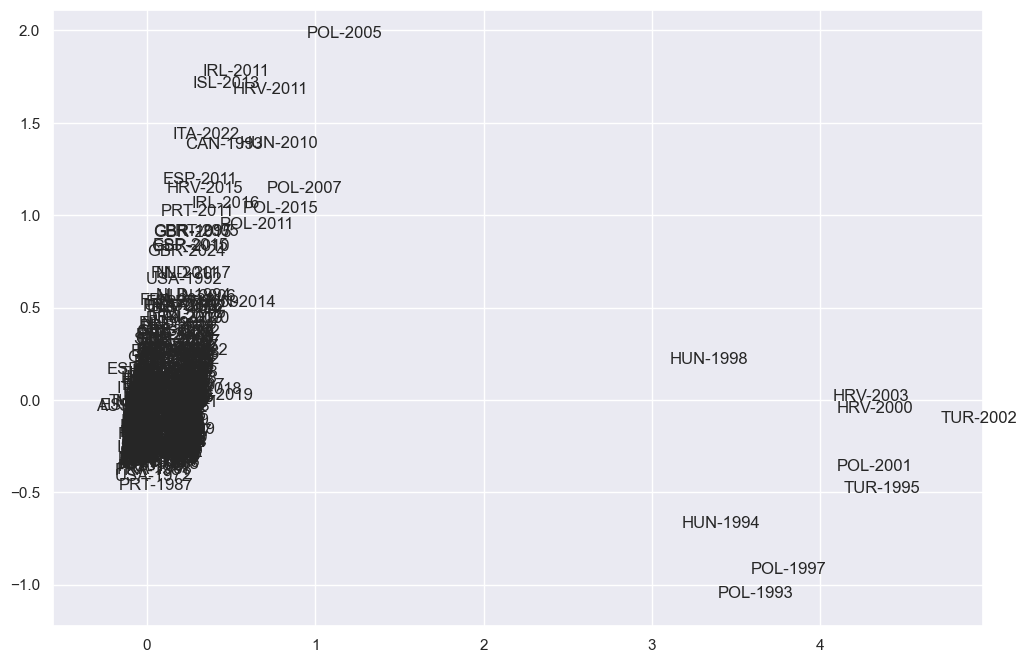

In [1679]:
plt.figure(figsize=(12,8));
mask = reduced_data[:, 0]>-100

plt.scatter(reduced_data[:, 0][mask], reduced_data[:, 1][mask],alpha=0)
for i, txt in enumerate(data.loc[mask].index):
    plt.annotate(txt[0]+"-"+str(txt[1]), (reduced_data[mask][i, 0], reduced_data[mask][i, 1]))

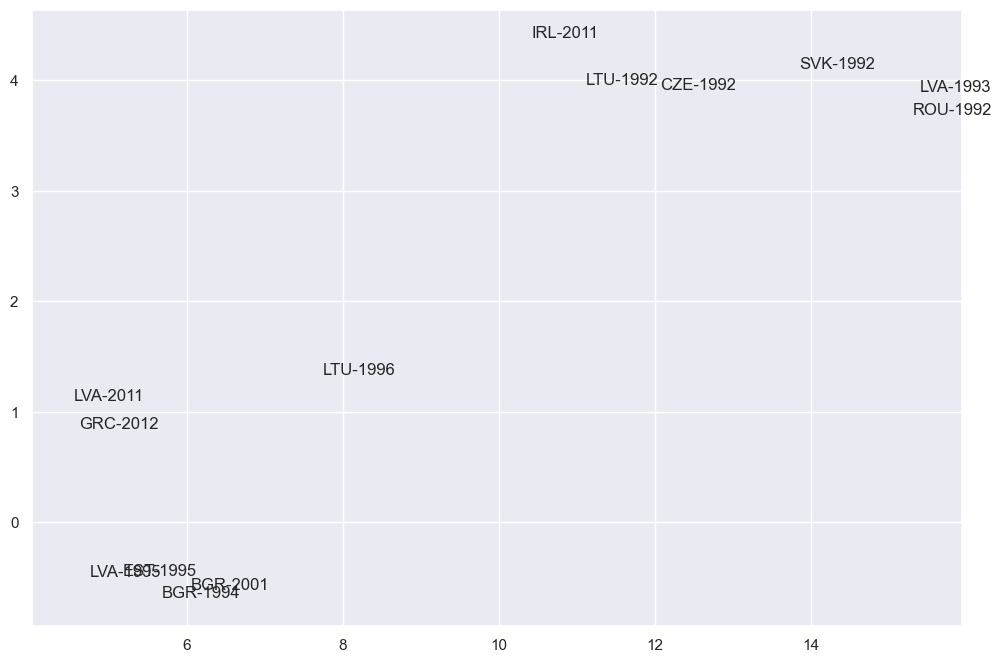

In [1580]:
plt.figure(figsize=(12,8));
mask = reduced_data[:, 0]>4.5

plt.scatter(reduced_data[:, 0][mask], reduced_data[:, 1][mask],alpha=0)
for i, txt in enumerate(data.loc[mask].index):
    plt.annotate(txt[0]+"-"+str(txt[1]), (reduced_data[mask][i, 0], reduced_data[mask][i, 1]))

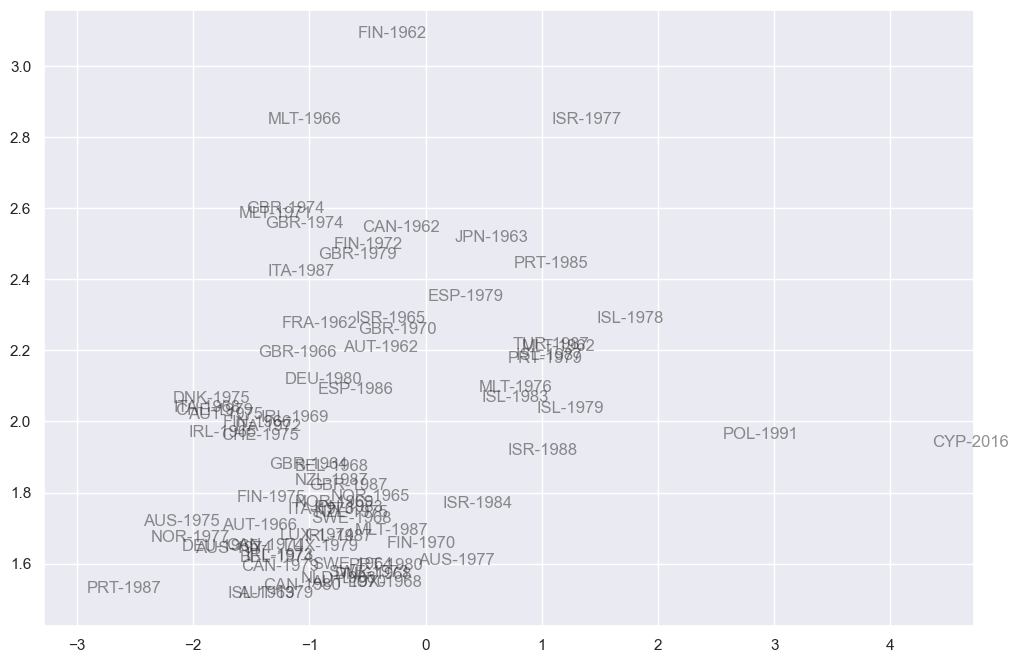

In [1573]:
plt.figure(figsize=(12,8));
mask = (reduced_data[:, 1]>1.5) & (reduced_data[:, 1]<3.5)

plt.scatter(reduced_data[:, 0][mask], reduced_data[:, 1][mask],alpha=0)
for i, txt in enumerate(data.loc[mask].index):
    plt.annotate(txt[0]+"-"+str(txt[1]), (reduced_data[mask][i, 0], reduced_data[mask][i, 1]),alpha=.5)

In [1581]:
country_outliers = ["BGR","LTU","LVA"]

In [1576]:
pd.DataFrame( reduced_data ).describe()

,0,1
count,5.530000e+02,5.530000e+02
mean,-8.277824e-08,1.552092e-08
std,1.907028e+00,1.308411e+00
min,-2.915866e+00,-2.308136e+00
25%,-9.792413e-01,-1.089266e+00
50%,-2.839853e-01,-4.131543e-01
75%,4.820913e-01,1.224443e+00
max,1.539652e+01,4.385601e+00


In [1500]:
temp

,election_year,coal_vote_share_change,coal_left_right,"Inflation, consumer prices (annual %)",Net migration,GDP growth (annual %)
131,1961,-4.40,7.476866,NaN,NaN,NaN
135,1963,4.00,7.477708,2.287582,64374.0,2.482618
140,1966,3.90,7.473863,2.866242,91169.0,6.980438
146,1969,-6.50,7.475122,3.478261,81057.0,6.305066
151,1972,-2.00,7.475884,3.439153,258627.0,7.175799
...,...,...,...,...,...,...
9167,2008,-5.07,NaN,3.225944,1113259.0,2.784540
9170,2012,-1.87,NaN,1.640043,1030731.0,2.695193
9172,2016,-2.88,NaN,1.622223,1250914.0,2.523820
9173,2020,0.77,NaN,2.442583,1200796.0,2.966505


,r,p,N
,r,p,N


MSE: 66.57, MAE: 6.03, EV: -0.04, R2: -0.13


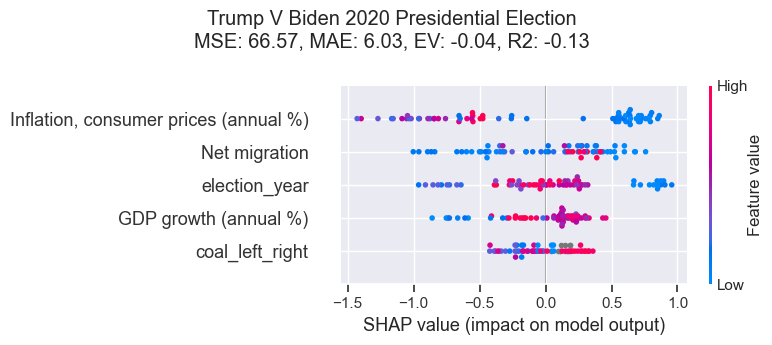

CPU times: total: 531 ms
Wall time: 339 ms


In [1489]:
%%time
extra_drop_list = ["presidential","caretaker_party","coal_member","coal_vote_frac_change",
                   "vote_share_change","vote_share_frac","pm_party","cabinet_party","left_right","incumbency"]

name="coal_vote_share_change"
pattern = "coal_vote_share_change"
mask =  (election_final['incumbency']>=1)\
    &(election_final['election_type']=='parliament')\
    &(election_final['election_year']>=1980)\
    &(election_final['country_name_short'].isin(["USA","GBR","AUS","NZL","CAN"]))

temp = election_final[mask].drop(drop_list+extra_drop_list,axis=1).drop_duplicates()

df, corr_type = make_corr_summary(temp, name, pattern=pattern,min_sample_size=20)
display_corr(df,name,corr_type)

(explainer, shap_values, train_columns, train_index, alg,output_subfolder,metrics) = xgboost_run(
    title = "Trump V Biden 2020 Presidential Election",
                                                    dataset=temp,
                                                    var_list = [name],var_stub_list = [name,pattern                                                            
                                                         ],
    verbosity=0)

In [ ]:
# Net migration = immigrants - emigrants (net immigration)

In [351]:
country_drop_list = ["ISL","LUX","MLT","CYP","LVA","ROU","FIN"]

In [358]:
# election_final["country_name_short"].value_counts().sort_index()

,r,p,N
pm_party,-0.210000,0.00,3692
cabinet_party,-0.250000,0.00,3660
,r,p,N
cabinet_party,-0.250000,0.00,3660
pm_party,-0.210000,0.00,3692


MSE: 25.11, MAE: 3.14, EV: 0.08, R2: 0.07


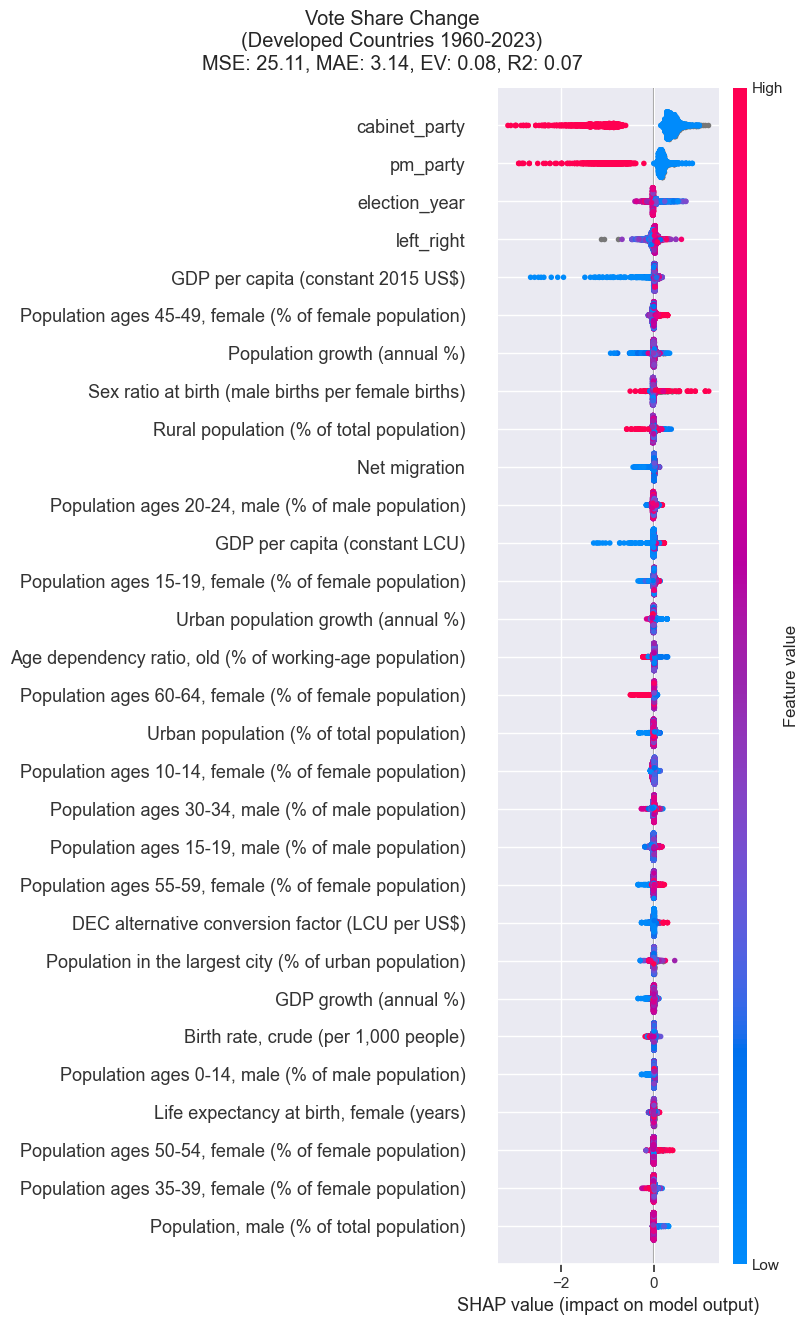

CPU times: total: 2.92 s
Wall time: 3.03 s


In [353]:
%%time

name="vote_share_change"
pattern = "vote_share_change"

mask = ~election_final["country_name_short"].isin( country_drop_list )

df, corr_type = make_corr_summary(election_final.drop(drop_list,axis=1)[mask], name, pattern=pattern)
display_corr(df,name,corr_type)

(explainer, shap_values, train_columns, train_index, alg,output_subfolder,metrics) = xgboost_run(
    title = "Vote Share Change\n(Developed Countries 1960-2023)",
                                                    dataset=election_final.drop(drop_list,axis=1)[mask],
                                                    var_list = [name],var_stub_list = [name,pattern                                                            
                                                         ],
    verbosity=0)

,r,p,N
pm_party,-0.210000,0.00,3725
cabinet_party,-0.260000,0.00,3691
,r,p,N
cabinet_party,-0.260000,0.00,3691
pm_party,-0.210000,0.00,3725


MSE: 25.86, MAE: 3.17, EV: 0.06, R2: 0.06


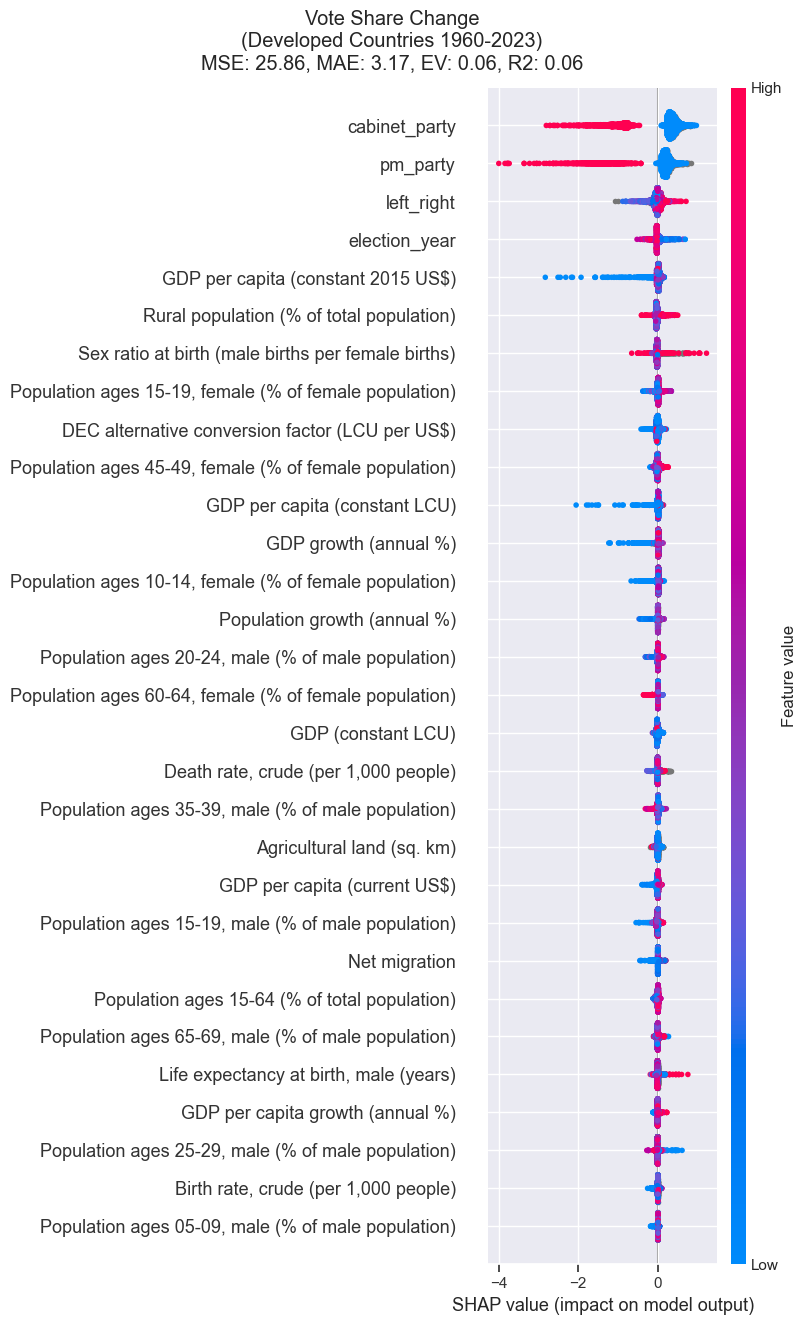

CPU times: total: 3.58 s
Wall time: 2.45 s


In [371]:
%%time

name="vote_share_change"
pattern = "vote_share_change"

mask = ~election_final["country_name_short"].isin( country_drop_list )

df, corr_type = make_corr_summary(election_final.drop(drop_list,axis=1)[mask], name, pattern=pattern)
display_corr(df,name,corr_type)

(explainer, shap_values, train_columns, train_index, alg,output_subfolder,metrics) = xgboost_run(
    title = "Vote Share Change\n(Developed Countries 1960-2023)",
                                                    dataset=election_final.drop(drop_list,axis=1)[mask],
                                                    var_list = [name],var_stub_list = [name,pattern                                                            
                                                         ],
    verbosity=0)

,r,p,N
GDP per capita (constant LCU),0.120000,0.00,1112
Urban population (% of total population),0.110000,0.00,1112
GDP per capita (constant 2015 US$),0.110000,0.00,1112
Net migration,0.090000,0.00,1112
Population growth (annual %),0.090000,0.00,1106
left_right,0.090000,0.00,1108
DEC alternative conversion factor (LCU per US$),0.080000,0.01,1112
GDP (constant 2015 US$),0.080000,0.01,1112
GDP (constant LCU),0.080000,0.01,1112
"Population ages 15-19, female (% of female[...]",0.070000,0.01,1112


MSE: 45.33, MAE: 4.60, EV: -0.01, R2: -0.04


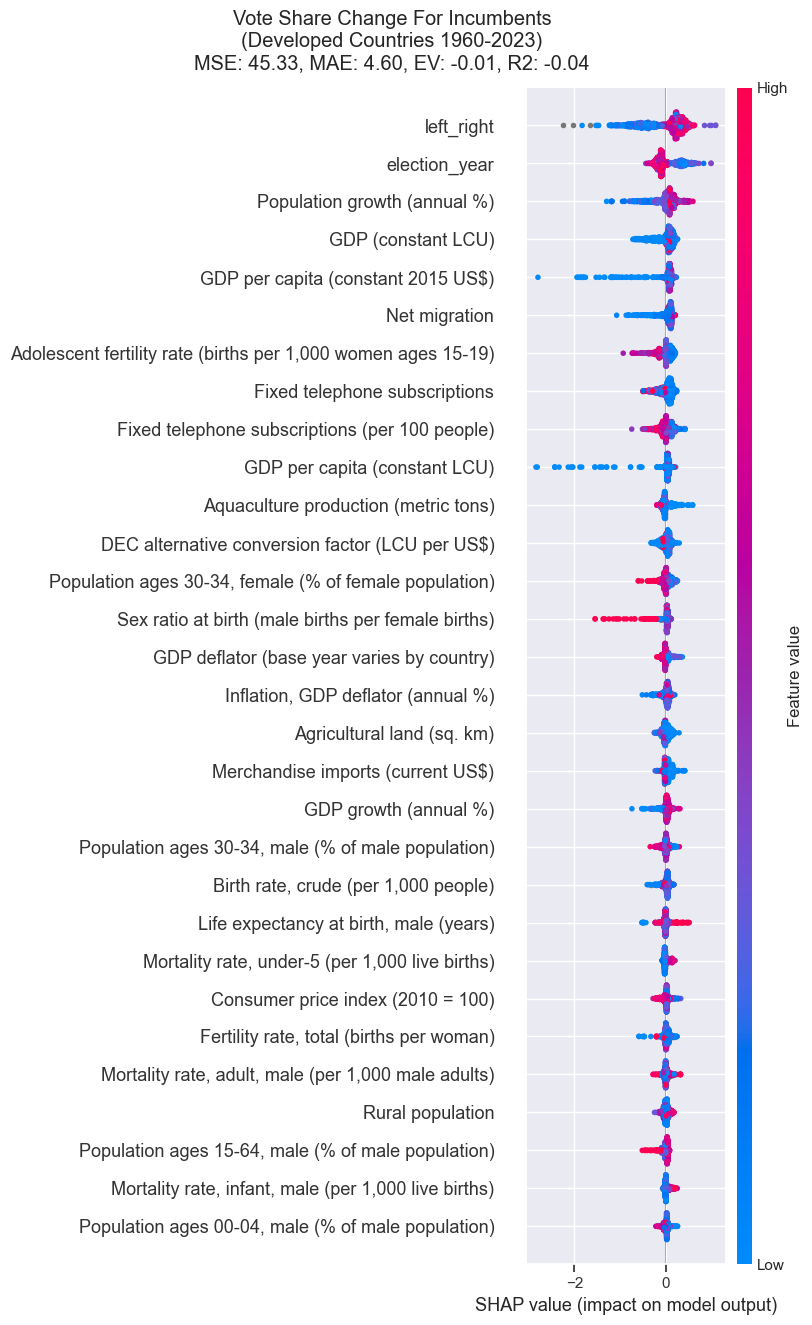

CPU times: total: 2.22 s
Wall time: 1.49 s


In [357]:
%%time

name="vote_share_change"
pattern = "vote_share_change"

mask = (~election_final["country_name_short"].isin( country_drop_list )) & (election_final["cabinet_party"]==1)

df, corr_type = make_corr_summary(election_final.drop(drop_list,axis=1)[mask], name, pattern=pattern)
display_corr(df,name,corr_type)

(explainer, shap_values, train_columns, train_index, alg,output_subfolder,metrics) = xgboost_run(
    title = "Vote Share Change For Incumbents\n(Developed Countries 1960-2023)",
                                                    dataset=election_final.drop(drop_list,axis=1)[mask],
                                                    var_list = [name],var_stub_list = [name,pattern, "pm_party"                                                           
                                                         ],
    verbosity=0)

,r,p,N
GDP per capita (constant LCU),0.120000,0.00,1119
Urban population (% of total population),0.110000,0.00,1119
GDP per capita (constant 2015 US$),0.110000,0.00,1119
Population growth (annual %),0.090000,0.00,1113
left_right,0.090000,0.00,1115
Net migration,0.090000,0.00,1119
"Population ages 15-19, female (% of female[...]",0.080000,0.01,1119
GDP (constant 2015 US$),0.080000,0.01,1119
"Population ages 10-14, female (% of female[...]",0.080000,0.01,1119
DEC alternative conversion factor (LCU per US$),0.080000,0.01,1119


MSE: 40.58, MAE: 4.39, EV: 0.03, R2: 0.02


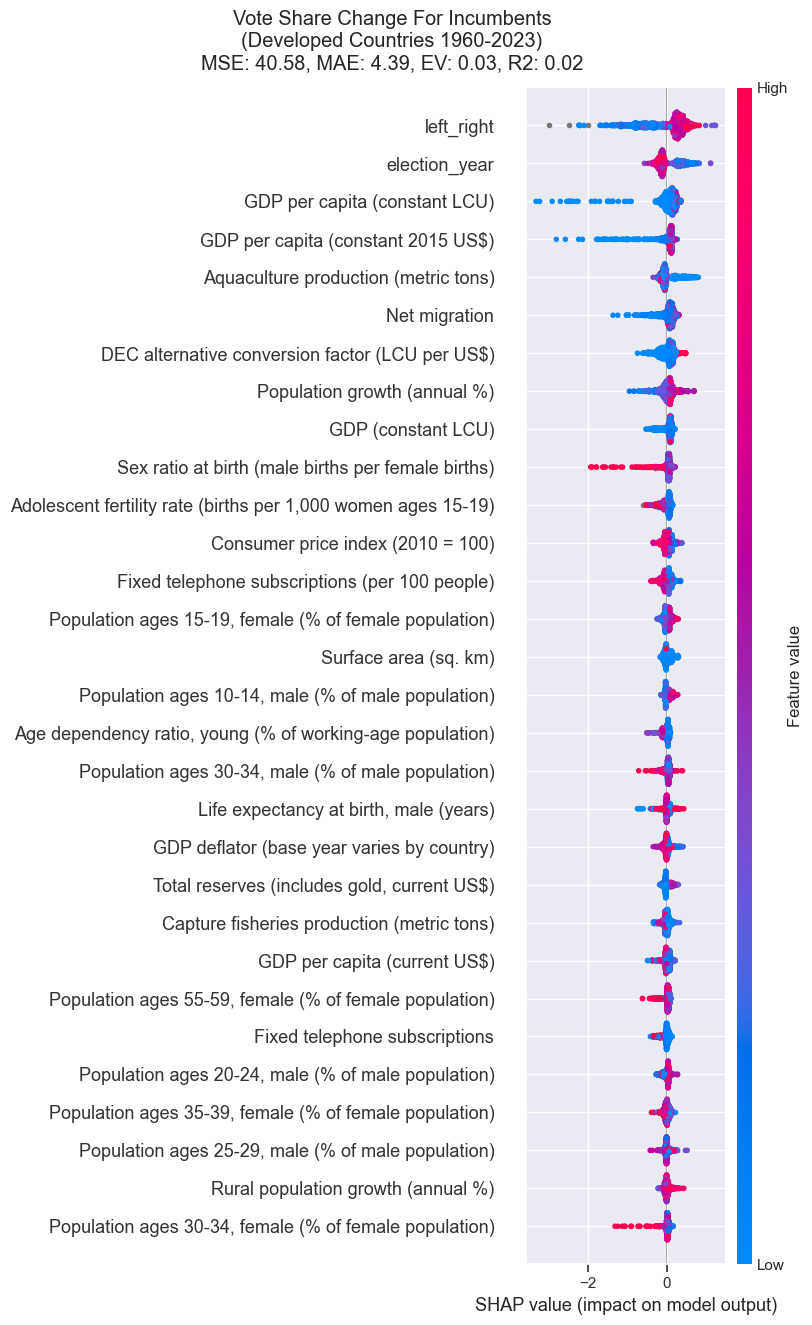

CPU times: total: 2.84 s
Wall time: 1.57 s


In [373]:
%%time

name="vote_share_change"
pattern = "vote_share_change"

mask = (~election_final["country_name_short"].isin( country_drop_list )) & (election_final["cabinet_party"]==1)

df, corr_type = make_corr_summary(election_final.drop(drop_list,axis=1)[mask], name, pattern=pattern)
display_corr(df,name,corr_type)

(explainer, shap_values, train_columns, train_index, alg,output_subfolder,metrics) = xgboost_run(
    title = "Vote Share Change For Incumbents\n(Developed Countries 1960-2023)",
                                                    dataset=election_final.drop(drop_list,axis=1)[mask],
                                                    var_list = [name],var_stub_list = [name,pattern, "pm_party"                                                           
                                                         ],
    verbosity=0)

,r,p,N
GDP per capita (constant LCU),0.120000,0.00,1119
Urban population (% of total population),0.110000,0.00,1119
GDP per capita (constant 2015 US$),0.110000,0.00,1119
Population growth (annual %),0.090000,0.00,1113
left_right,0.090000,0.00,1115
Net migration,0.090000,0.00,1119
"Population ages 15-19, female (% of female[...]",0.080000,0.01,1119
GDP (constant 2015 US$),0.080000,0.01,1119
"Population ages 10-14, female (% of female[...]",0.080000,0.01,1119
DEC alternative conversion factor (LCU per US$),0.080000,0.01,1119


MSE: 42.43, MAE: 4.52, EV: -0.02, R2: -0.03


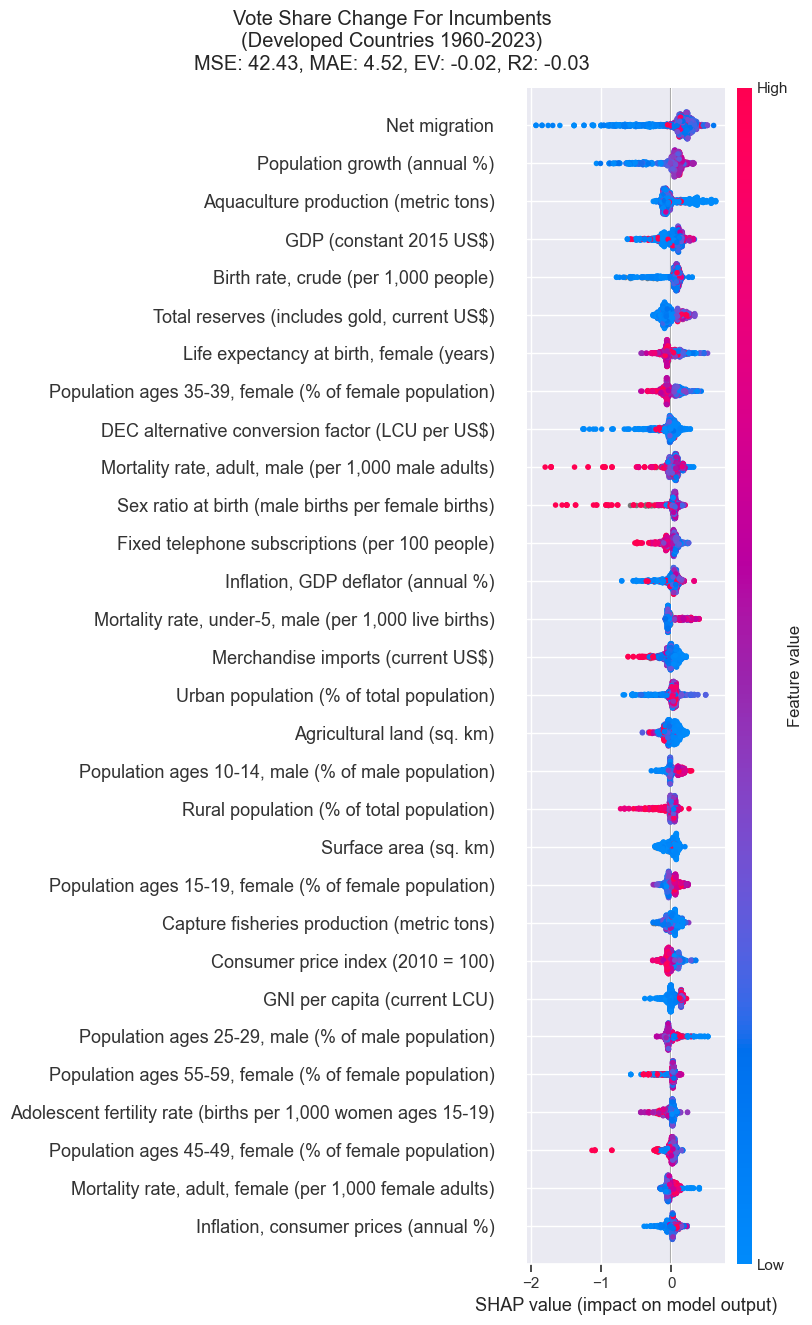

CPU times: total: 2.66 s
Wall time: 1.48 s


In [382]:
%%time

name="vote_share_change"
pattern = "vote_share_change"

mask = (~election_final["country_name_short"].isin( country_drop_list )) & (election_final["cabinet_party"]==1)

df, corr_type = make_corr_summary(election_final.drop(drop_list,axis=1)[mask], name, pattern=pattern)
display_corr(df,name,corr_type)

(explainer, shap_values, train_columns, train_index, alg,output_subfolder,metrics) = xgboost_run(
    title = "Vote Share Change For Incumbents\n(Developed Countries 1960-2023)",
                                                    dataset=election_final.drop(drop_list+gdp_list,axis=1)[mask],
                                                    var_list = [name],var_stub_list = [name,pattern,
                                                    "pm_party","left_right","election_year",
                                                         ],
    verbosity=0)

In [380]:
indicator_list

['Adolescent fertility rate (births per 1,000 women ages 15-19)',
 'Age dependency ratio (% of working-age population)',
 'Age dependency ratio, old (% of working-age population)',
 'Age dependency ratio, young (% of working-age population)',
 'Agricultural land (sq. km)',
 'Aquaculture production (metric tons)',
 'Average precipitation in depth (mm per year)',
 'Birth rate, crude (per 1,000 people)',
 'Capture fisheries production (metric tons)',
 'Consumer price index (2010 = 100)',
 'DEC alternative conversion factor (LCU per US$)',
 'Death rate, crude (per 1,000 people)',
 'Fertility rate, total (births per woman)',
 'Fixed telephone subscriptions',
 'Fixed telephone subscriptions (per 100 people)',
 'GDP (constant 2015 US$)',
 'GDP (constant LCU)',
 'GDP (current LCU)',
 'GDP (current US$)',
 'GDP deflator (base year varies by country)',
 'GDP growth (annual %)',
 'GDP per capita (constant 2015 US$)',
 'GDP per capita (constant LCU)',
 'GDP per capita (current LCU)',
 'GDP per cap

In [381]:
 gdp_list = [
#      'GDP (constant 2015 US$)',
 'GDP (constant LCU)',
 'GDP (current LCU)',
 'GDP (current US$)',
 'GDP deflator (base year varies by country)',
 'GDP growth (annual %)',
 'GDP per capita (constant 2015 US$)',
 'GDP per capita (constant LCU)',
 'GDP per capita (current LCU)',
 'GDP per capita (current US$)',
 'GDP per capita growth (annual %)',]

In [398]:
mask = (~election_final["country_name_short"].isin( country_drop_list )) & (election_final["cabinet_party"]==1)
election_final.drop(drop_list+gdp_list,axis=1)[mask].corrwith(election_final.drop(drop_list+gdp_list,axis=1)[mask]["vote_share_change"]).dropna().sort_values().tail(50)

Population ages 0-14, female                                 0.001695
DEC alternative conversion factor (LCU per US$)              0.002658
GNI per capita (current LCU)                                 0.004439
Population ages 25-29, female (% of female population)       0.004698
Life expectancy at birth, male (years)                       0.007128
Inflation, consumer prices (annual %)                        0.009797
Aquaculture production (metric tons)                         0.010564
GNI (current LCU)                                            0.010985
Inflation, GDP deflator (annual %)                           0.012453
Surface area (sq. km)                                        0.014936
Mortality rate, adult, female (per 1,000 female adults)      0.016206
Total reserves minus gold (current US$)                      0.018183
Rural population growth (annual %)                           0.018476
Total reserves (includes gold, current US$)                  0.023457
Survival to age 65, 

In [ ]:
# Consumer price index (2010 = 100)                        -0.093895

# age bias - younger pop more supportive of incumbents? Credible as not a period confound?

In [395]:
wdi_data_ind.loc[("SWE","Consumer price index (2010 = 100)")]

Country Name           Sweden
Indicator Code    FP.CPI.TOTL
1960                 9.210913
1961                 9.409682
1962                 9.858166
                     ...     
2020               111.058857
2021               113.461279
2022               122.957183
2023               133.468332
2024               133.468332
Name: (SWE, Consumer price index (2010 = 100)), Length: 67, dtype: object

In [399]:
wdi_data_ind.loc[("SWE","Inflation, GDP deflator (annual %)")]

Country Name                 Sweden
Indicator Code    NY.GDP.DEFL.KD.ZG
1960                            NaN
1961                        2.93738
1962                       4.020266
                        ...        
2020                       1.994046
2021                       2.585885
2022                       6.016235
2023                       5.618098
2024                       5.618098
Name: (SWE, Inflation, GDP deflator (annual %)), Length: 67, dtype: object

,r,p,N
People using at least basic sanitation services (%[...],0.240000,0.00,550
"Adjusted net savings, including particulate[...]",0.180000,0.00,630
"Adjusted net savings, excluding particulate[...]",0.170000,0.00,630
Gross savings (% of GDP),0.170000,0.00,862
Gross savings (% of GNI),0.160000,0.00,862
"GDP per capita, PPP (constant 2021 international[...]",0.160000,0.00,759
"Industry (including construction), value added per[...]",0.160000,0.00,678
Adjusted savings: net national savings (% of GNI),0.160000,0.00,766
"Services, value added per worker (constant 2015[...]",0.160000,0.00,678
"School enrollment, preprimary, female (% gross)",0.150000,0.00,811


MSE: 38.84, MAE: 4.34, EV: 0.08, R2: 0.06


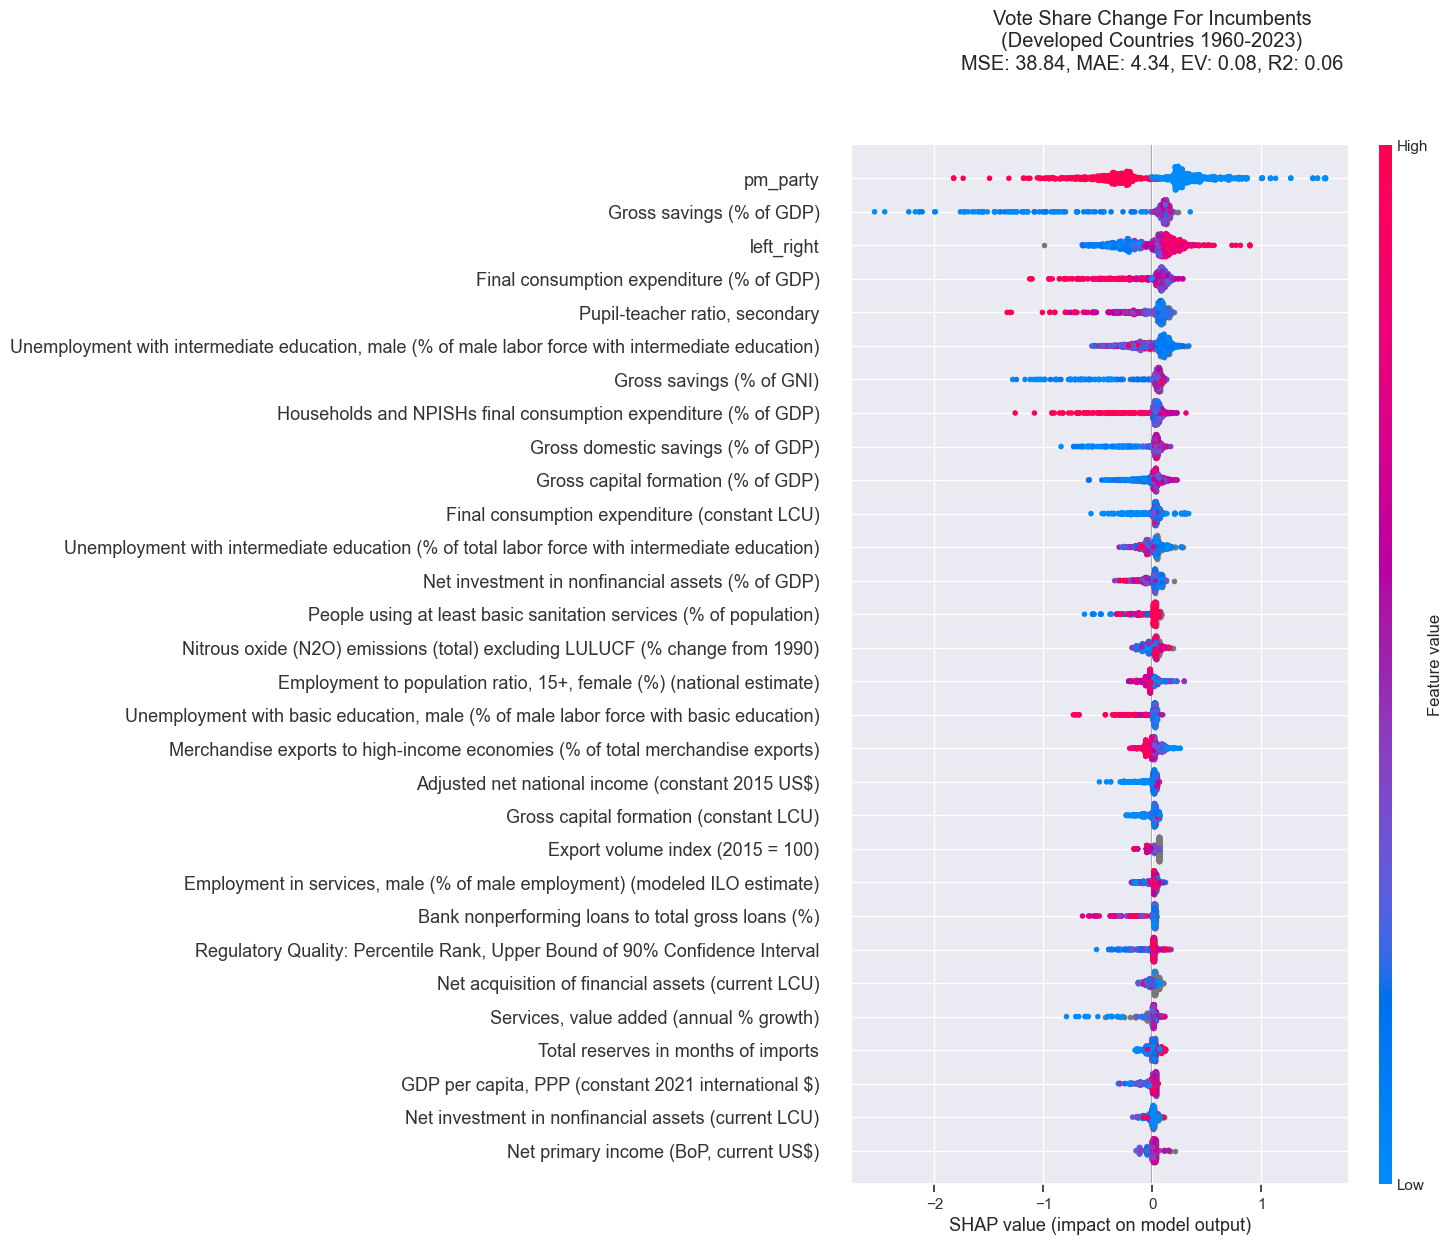

CPU times: total: 20.1 s
Wall time: 5.97 s


In [409]:
%%time

name="vote_share_change"
pattern = "vote_share_change"

mask = (~election_final["country_name_short"].isin( country_drop_list )) & (election_final["cabinet_party"]==1)

df, corr_type = make_corr_summary(election_final.drop(drop_list,axis=1)[mask], name, pattern=pattern)
display_corr(df,name,corr_type)

(explainer, shap_values, train_columns, train_index, alg,output_subfolder,metrics) = xgboost_run(
    title = "Vote Share Change For Incumbents\n(Developed Countries 1960-2023)",
                                                    dataset=election_final.drop(drop_list+gdp_list,axis=1)[mask],
                                                    var_list = [name],var_stub_list = [name,pattern,
#                                                     "pm_party","left_right","election_year",
                                                         ],
    verbosity=0)

,r,p,N
Rule of Law: Standard Error,0.050000,0.01,2227
"Industry (including construction), value added[...]",0.040000,0.01,3153
Merchandise imports from low- and middle-income[...],0.040000,0.01,3868
"Primary education, pupils",0.040000,0.01,3726
Control of Corruption: Number of Sources,-0.050000,0.01,2227
Prevalence of current tobacco use (% of adults),-0.100000,0.01,661
pm_party,-0.210000,0.00,3725
cabinet_party,-0.260000,0.00,3691
,r,p,N
cabinet_party,-0.260000,0.00,3691


MSE: 25.80, MAE: 3.18, EV: 0.07, R2: 0.06


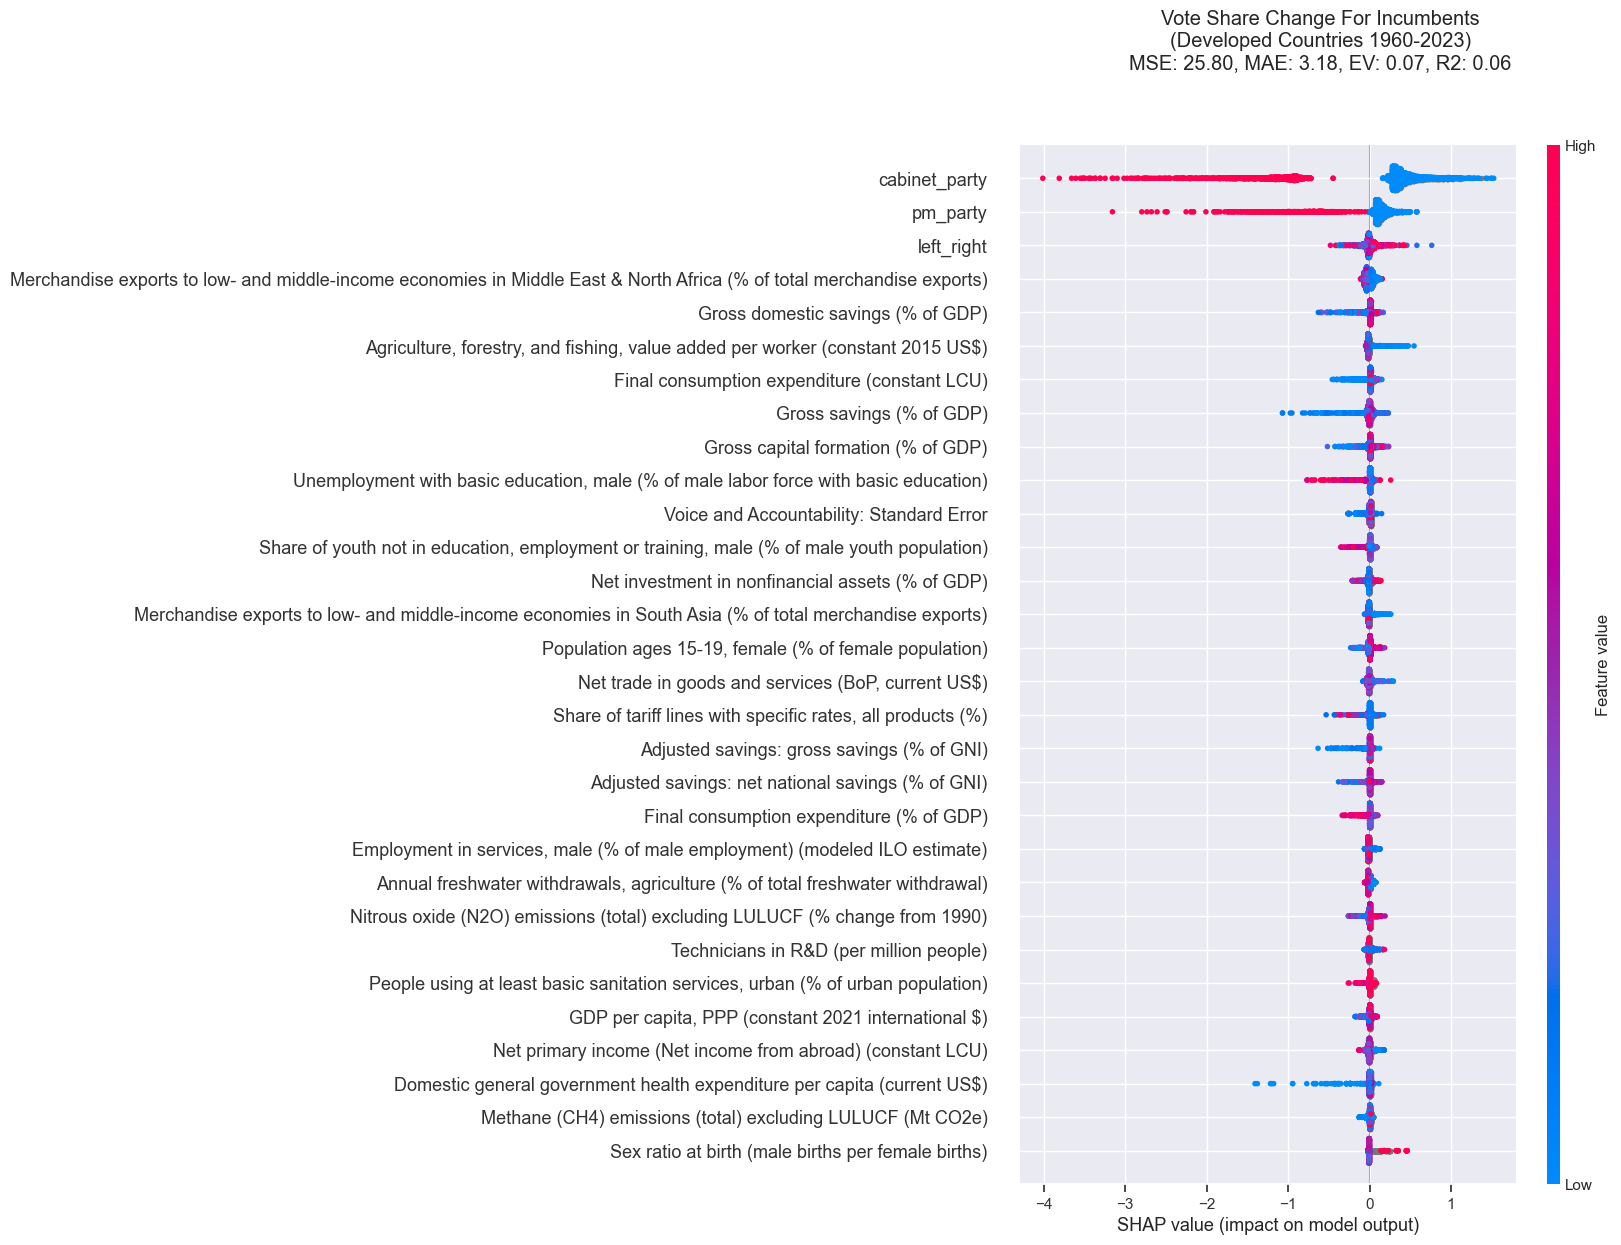

CPU times: total: 27.7 s
Wall time: 8.89 s


In [410]:
%%time

name="vote_share_change"
pattern = "vote_share_change"

mask = (~election_final["country_name_short"].isin( country_drop_list ))

df, corr_type = make_corr_summary(election_final.drop(drop_list,axis=1)[mask], name, pattern=pattern)
display_corr(df,name,corr_type)

(explainer, shap_values, train_columns, train_index, alg,output_subfolder,metrics) = xgboost_run(
    title = "Vote Share Change For Incumbents\n(Developed Countries 1960-2023)",
                                                    dataset=election_final.drop(drop_list+gdp_list,axis=1)[mask],
                                                    var_list = [name],var_stub_list = [name,pattern,
#                                                     "pm_party","left_right","election_year",
                                                         ],
    verbosity=0)

In [ ]:
# bleh - this is incredibly noisy!

In [ ]:
## try just plotting US incumbent vote share change vs some measure of inflation

In [895]:
elec_USA

election_year
1960    -7.81
1964    11.33
1968   -18.33
1972    17.25
1976   -12.65
1980    -9.07
1984     8.02
1988    -5.40
1992   -15.92
1996     6.22
2000    -0.85
2004     2.86
2008    -5.07
2012    -1.87
2016    -2.88
2020     0.77
2024    -3.21
Name: vote_share_change, dtype: float64

In [854]:
elec_USA =election_final[ (election_final["country_name_short"]=="USA")&(election_final['pm_party']==1) ].set_index("election_year")["vote_share_change"]

In [470]:
temp = wdi_data_ind.loc[("USA","Inflation, GDP deflator (annual %)")]
temp = temp.loc[temp.index[2:]]
temp.index = temp.index.astype(int)

# patch for missing 1960 value
wdi_data_ind.loc[("USA","Inflation, GDP deflator (annual %)"),"1960"] = ((22.4/22.2)-1)*100
temp.loc[1960] = ((22.4/22.2)-1)*100
temp.loc[1959] = ((22.2/21.9)-1)*100
temp.loc[1958] = ((21.9/21.6)-1)*100
temp.loc[1957] = ((21.6/21.1)-1)*100


temp.tail(10)

2018     2.29089
2019    1.678508
2020    1.320618
2021    4.584745
2022    7.041026
2023    3.644995
2024    3.644995
1959    1.369863
1958    1.388889
1957    2.369668
Name: (USA, Inflation, GDP deflator (annual %)), dtype: object

In [851]:
# Inflation, consumer prices (annual %)
temp = wdi_data_ind.loc[("USA","Inflation, consumer prices (annual %)")]
temp = temp.loc[temp.index[2:]]
temp.index = temp.index.astype(int)

temp.loc[1959] = 1.08
temp.loc[1958] = 2.7
temp.loc[1957] = 3.3

In [1368]:
# temp2=pd.Series()
# for year in range(1960,2025,4):
#     temp2[year]= (100+temp.loc[year-3])*(100+temp.loc[year-2])*(100+temp.loc[year-1])*(100+temp.loc[year])/(100*100*100*100) 

# temp2=(temp2-1)*100
# temp2

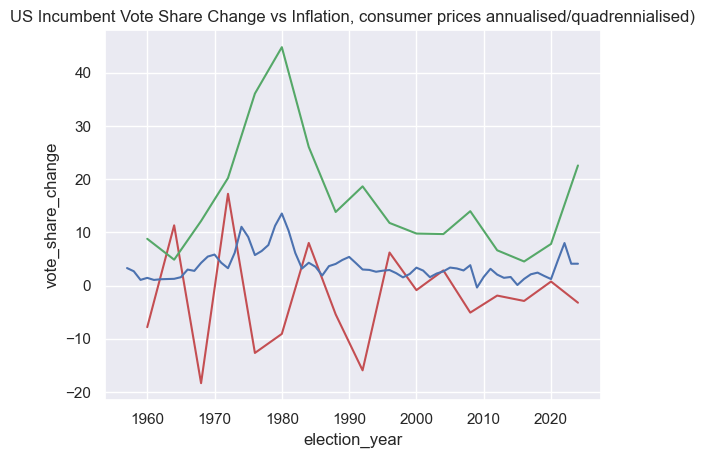

In [855]:
sns.lineplot(elec_USA,c='r');
sns.lineplot(temp,c='b');
sns.lineplot(temp2,c='g');
plt.title("US Incumbent Vote Share Change vs Inflation, consumer prices annualised/quadrennialised)");

In [865]:
pd.Series(temp.loc[1960::4].values).corr(pd.Series(elec_USA.values)),(pd.Series(temp2.values)).corr(pd.Series(elec_USA.values))

(-0.30536982860226014, -0.23552964859434022)

In [870]:
pd.Series(temp2.values).corr(pd.Series(elec_USA.values))

-0.23552964859434022

In [894]:
pd.Series(temp.loc[1960::4].values).corr((pd.Series(elec_USA.values)))

-0.30536982860226014

In [890]:
temp

1957         3.3
1958         2.7
1959        1.08
1960    1.457976
1961    1.070724
          ...   
2020    1.233584
2021    4.697859
2022      8.0028
2023    4.116338
2024    4.116338
Name: (USA, Inflation, consumer prices (annual %)), Length: 68, dtype: object

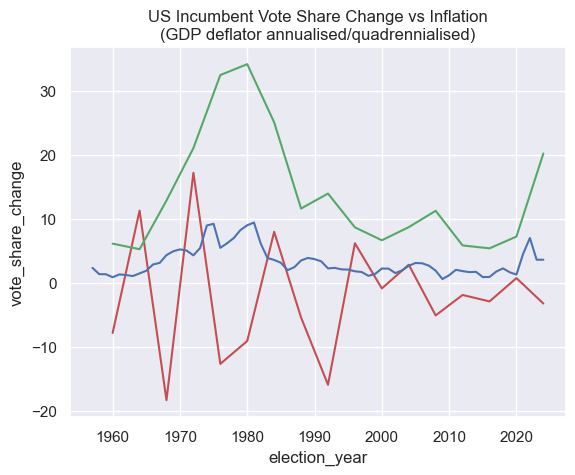

In [506]:
sns.lineplot(elec_USA,c='r');
sns.lineplot(temp,c='b');
sns.lineplot(temp2,c='g');
plt.title("US Incumbent Vote Share Change vs Inflation\n(GDP deflator annualised/quadrennialised)");

In [729]:
election_final['incumbency'].value_counts()

incumbency
0.0    5192
1.0     795
3.0     668
0.5     367
1.5      51
3.5      39
2.0      17
Name: count, dtype: int64

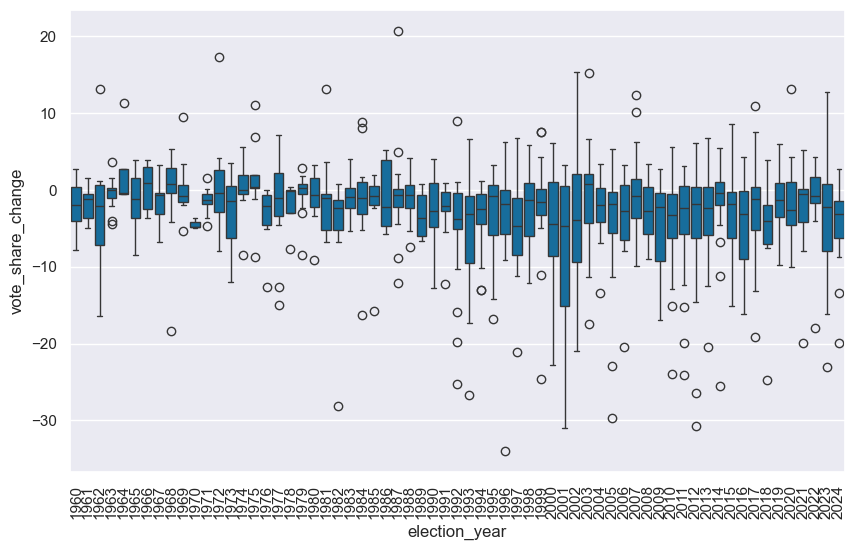

In [770]:
mask = (election_final['incumbency']>=1) &(election_final['election_type']=='parliament')&(~election_final["country_name_short"].isin( country_drop_list ))
plt.figure(figsize=(10,6));
sns.boxplot(data=election_final[mask],x="election_year",y="vote_share_change");
plt.xticks(rotation=90);

In [772]:
election_final[mask][election_final["election_year"]==2024][["country_name_short","vote_share_change"]]

,country_name_short,vote_share_change
939,BEL,-1.42
941,BEL,2.70
942,BEL,-3.21
943,BEL,-3.09
944,BEL,-0.91
946,BEL,1.40
947,BEL,-1.45
3999,FRA,-4.47
4372,GBR,-19.90
4735,HRV,-2.84


In [774]:
election_final[mask][(election_final["election_year"]==2024)&(election_final["country_name_short"]=="BEL")][["vote_share_change"]].sum()

# bit cheeky to add this all together for "governing coalition"!
# should we do this for all of them?

vote_share_change   -5.98
dtype: float64

In [1332]:
search( election_final, "coal")

coal_member               7129
coal_vote_share_change    7129
coal_vote_frac_change     7103
dtype: int64

In [1334]:
%%time
inflat_corr=pd.Series()
elec_country = {}
inf_country = {}
for cnt in election_final["country_name_short"].unique():
    # mean incumbent voteshare loss per election_year # actually - take the max!
    elec_country[cnt] =election_final[ (election_final["country_name_short"]==cnt)\
                                      &(election_final['incumbency']>=1)\
                                      &(election_final['election_type']=='parliament')\
                                      &(election_final['election_year']>=2000)
                                     
                                     
                                     ].groupby("election_year")["coal_vote_share_change"].max()
    
    temp = wdi_data_ind.loc[(cnt,"Inflation, consumer prices (annual %)")]
    temp = temp.loc[temp.index[2:]]
    temp.index = temp.index.astype(int)
    temp = temp.loc[elec_country[cnt].index]
    inf_country[cnt]=temp
    
    inflat_corr.loc[cnt] = elec_country[cnt].corr(temp ,method='spearman')
inflat_corr.sort_values()

CPU times: total: 15.6 ms
Wall time: 121 ms


TUR   -0.771429
FIN   -0.738769
BGR   -0.619048
ROU   -0.600000
USA   -0.535714
NZL   -0.523810
AUS   -0.404762
ISR   -0.400000
BEL   -0.257143
CHE   -0.200000
DNK   -0.142857
LVA   -0.142857
PRT   -0.119048
ITA   -0.100000
DEU   -0.085714
GBR   -0.071429
HRV    0.023810
JPN    0.066667
ESP    0.142857
HUN    0.151794
NLD    0.190476
SVK    0.214286
POL    0.250000
NOR    0.257143
AUT    0.257143
LTU    0.285714
EST    0.314286
FRA    0.371429
CZE    0.428571
MLT    0.500000
IRL    0.500000
GRC    0.523810
LUX    0.600000
CYP    0.600000
SWE    0.714286
ISL    0.714286
CAN    0.738095
SVN    0.892857
dtype: float64

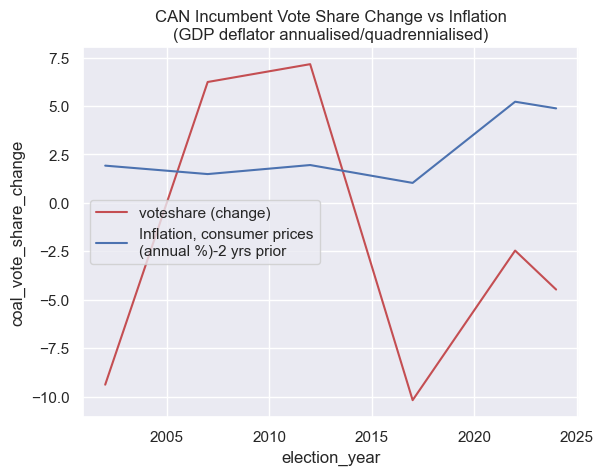

In [1358]:
sns.lineplot(elec_country["FRA"],c='r',label='voteshare (change)');
sns.lineplot(inf_country["FRA"],c='b',label="Inflation, consumer prices\n(annual %)-2 yrs prior");
# sns.lineplot(temp2,c='g');
plt.title("CAN Incumbent Vote Share Change vs Inflation\n(GDP deflator annualised/quadrennialised)");

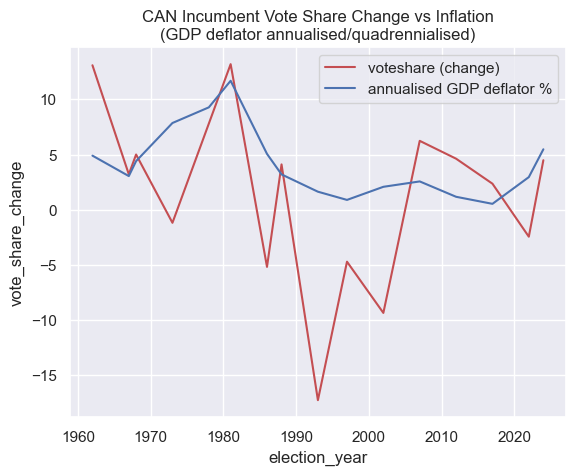

In [777]:
sns.lineplot(elec_country["FRA"],c='r',label='voteshare (change)');
sns.lineplot(inf_country["FRA"],c='b',label='annualised GDP deflator %');
# sns.lineplot(temp2,c='g');
plt.title("CAN Incumbent Vote Share Change vs Inflation\n(GDP deflator annualised/quadrennialised)");

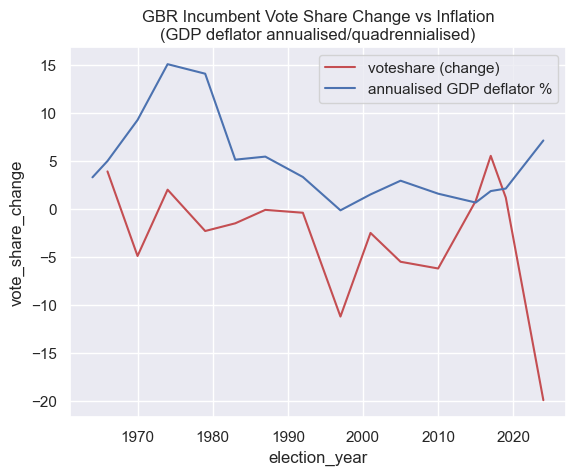

In [778]:
sns.lineplot(elec_country["GBR"],c='r',label='voteshare (change)');
sns.lineplot(inf_country["GBR"],c='b',label='annualised GDP deflator %');
# sns.lineplot(temp2,c='g');
plt.title("GBR Incumbent Vote Share Change vs Inflation\n(GDP deflator annualised/quadrennialised)");

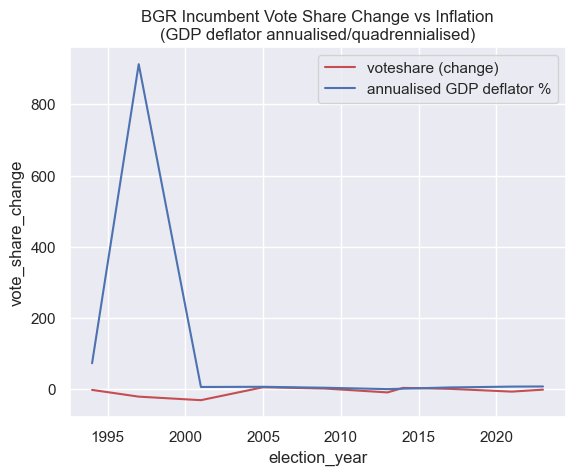

In [779]:
sns.lineplot(elec_country["BGR"],c='r',label='voteshare (change)');
sns.lineplot(inf_country["BGR"],c='b',label='annualised GDP deflator %');
# sns.lineplot(temp2,c='g');
plt.title("BGR Incumbent Vote Share Change vs Inflation\n(GDP deflator annualised/quadrennialised)");

In [ ]:
### BUG! ****in my code**** somehow I'm sometimes missing the prime_minister 

In [747]:
elec_USA

election_year
1960    -7.81
1964    11.33
1968   -18.33
1972    17.25
1976   -12.65
1980    -9.07
1984     8.02
1988    -5.40
1992   -15.92
1996     6.22
2000    -0.85
2004     2.86
2008    -5.07
2012    -1.87
2016    -2.88
2020     0.77
2024    -3.21
Name: vote_share_change, dtype: float64

In [478]:
temp3=temp

In [480]:
temp3 = temp3.sort_index()

In [547]:
pd.Series(temp3.loc[1960::4].values).corr(pd.Series(elec_USA.values))

-0.23411218339206563

In [537]:
election_final["country_name_short"].value_counts()

country_name_short
DNK    383
ITA    343
BEL    336
NLD    315
FRA    285
ESP    284
ISR    279
GBR    273
FIN    238
GRC    221
PRT    216
CHE    209
IRL    207
SWE    204
DEU    201
BGR    183
JPN    180
SVN    179
SVK    175
LTU    174
AUS    165
POL    161
LUX    157
ROU    154
LVA    150
CZE    145
HRV    144
AUT    140
NOR    134
NZL    129
HUN    125
ISL    123
CAN    118
EST    114
CYP    104
TUR     84
MLT     62
USA     34
Name: count, dtype: int64

In [845]:
mask =  (election_final['incumbency']>=1)\
    &(election_final['election_type']=='parliament')\
    &(election_final['election_year']>=1900)\
    &(election_final['country_name_short'].isin(["GBR",]))
print(mask.sum())
# election_final.select_dtypes('number')[mask].corrwith(election_final["vote_share_change"][mask])\
#     .drop(["vote_share_change","vote_share","vote_share_previous"]).dropna().sort_values()

df, corr_type = make_corr_summary(election_final.drop(drop_list,axis=1)[mask], name, pattern=pattern,
                                  min_sample_size=5,min_p_value=.5)
display_corr(df,name,corr_type)


18


,r,p,N
pm_party,0.360000,0.16,17
incumbency,0.360000,0.16,17
Food exports (% of merchandise exports),0.350000,0.17,17
Arable land (% of land area),0.280000,0.29,16
Arable land (hectares),0.280000,0.29,16
"Population ages 05-09, male (% of male population)",0.270000,0.30,17
Sex ratio at birth (male births per female births),0.270000,0.32,16
Land under cereal production (hectares),0.270000,0.30,16
"Population ages 05-09, female (% of female[...]",0.270000,0.29,17
"Population ages 00-04, female (% of female[...]",0.260000,0.31,17


In [900]:
election_final.drop(drop_list,axis=1)[mask]["vote_share_change"]\
    .corr(election_final.drop(drop_list,axis=1)[mask]["Inflation, consumer prices (annual %)"],method="spearman")

-0.4068627450980392

In [896]:
mask =  (election_final['incumbency']>=1)\
    &(election_final['election_type']=='parliament')\
    &(election_final['election_year']>=1960)\
    &(election_final['country_name_short'].isin(["USA",]))
print(mask.sum())
# election_final.select_dtypes('number')[mask].corrwith(election_final["vote_share_change"][mask])\
#     .drop(["vote_share_change","vote_share","vote_share_previous"]).dropna().sort_values()

df, corr_type = make_corr_summary(election_final.drop(drop_list,axis=1)[mask], name, pattern=pattern,
                                  min_sample_size=5,min_p_value=.5)
display_corr(df,name,corr_type)


17


,r,p,N
Mobile cellular subscriptions,0.410000,0.15,14
GDP growth (annual %),0.270000,0.31,16
"Population ages 50-54, male (% of male population)",0.270000,0.30,17
"Population ages 40-44, male (% of male population)",0.270000,0.30,17
"Population ages 0-14, male",0.250000,0.34,17
Nitrous oxide (N2O) emissions (total) excluding[...],0.240000,0.44,13
GDP per capita growth (annual %),0.240000,0.38,16
"Population ages 0-14, female",0.230000,0.38,17
Merchandise imports from low- and middle-income[...],0.220000,0.41,16
"Population ages 0-14, total",0.220000,0.40,17


In [830]:
mask =  (election_final['incumbency']>=1)\
    &(election_final['election_type']=='parliament')\
    &(election_final['election_year']>=2000)\
    &(~election_final['country_name_short'].isin(country_drop_list))

# election_final.select_dtypes('number')[mask].corrwith(election_final["vote_share_change"][mask])\
#     .drop(["vote_share_change","vote_share","vote_share_previous"]).dropna().sort_values()

df, corr_type = make_corr_summary(election_final.drop(drop_list,axis=1)[mask], name, pattern=pattern,min_sample_size=50)
display_corr(df,name,corr_type)


,r,p,N
Merchandise exports to low- and middle-income[...],0.230000,0.00,359
Net migration,0.220000,0.00,430
Urban population (% of total population),0.200000,0.00,430
"Life expectancy at birth, total (years)",0.180000,0.00,397
GDP per capita (constant LCU),0.180000,0.00,430
Merchandise exports to low- and middle-income[...],0.180000,0.00,359
"Life expectancy at birth, female (years)",0.180000,0.00,397
"Life expectancy at birth, male (years)",0.170000,0.00,397
Total reserves minus gold (current US$),0.170000,0.00,430
GDP per capita (constant 2015 US$),0.170000,0.00,430


468
MSE: 49.81, MAE: 4.73, EV: 0.02, R2: -0.01


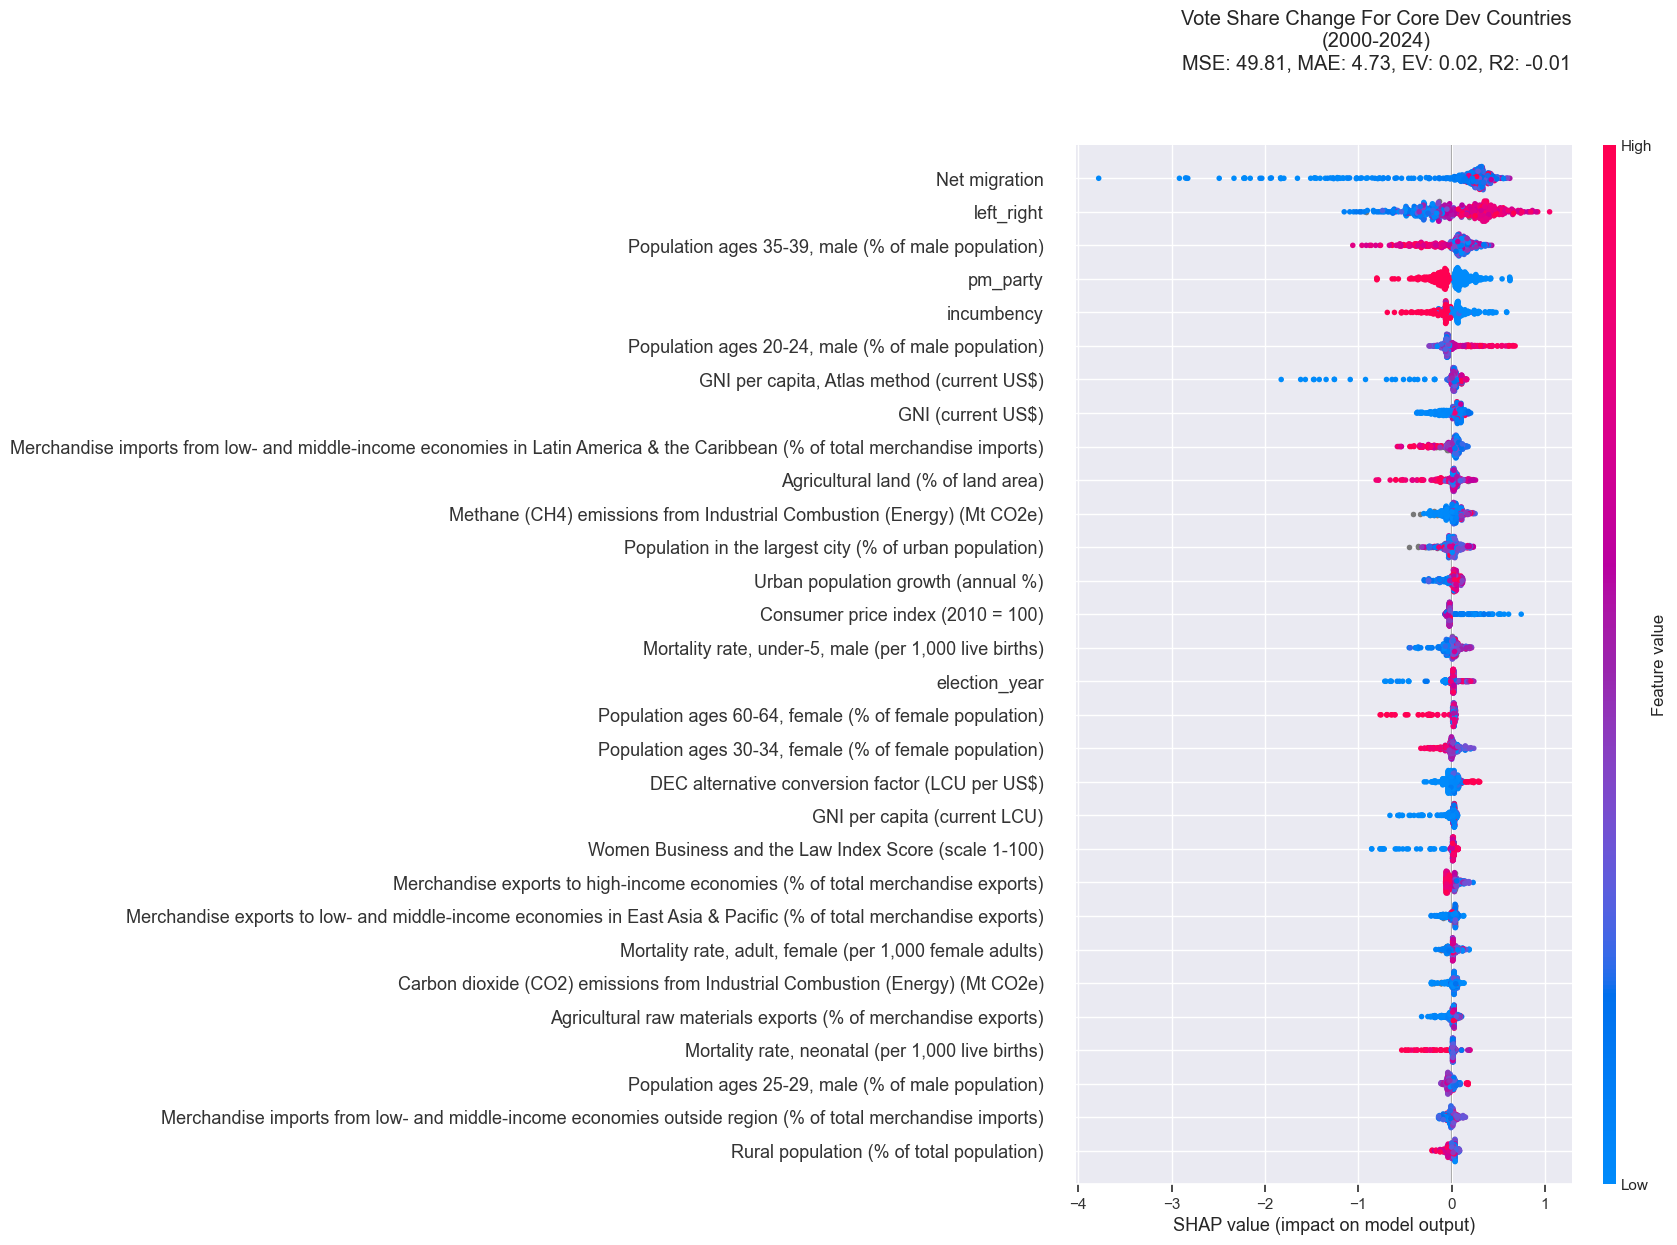

CPU times: total: 1.92 s
Wall time: 1.31 s


In [819]:
%%time

name="vote_share_change"
pattern = "vote_share_change"
#(election_final["country_name_short"].isin( ["USA","GBR","FRA","DEU","CAN","AUS","NZL","AUT","JPN"] ))  &
mask =  (election_final['incumbency']>=1)\
    &(election_final['election_type']=='parliament')\
    &(election_final['election_year']>=2000)\
    &(~election_final['country_name_short'].isin(country_drop_list))
print(mask.sum())
# df, corr_type = make_corr_summary(election_final.drop(drop_list,axis=1)[mask], name, pattern=pattern)
# display_corr(df,name,corr_type)

(explainer, shap_values, train_columns, train_index, alg,output_subfolder,metrics) = xgboost_run(
    title = "Vote Share Change For Core Dev Countries\n(2000-2024)",
                                                    dataset=election_final.drop(drop_list+gdp_list,axis=1)[mask],
                                                    var_list = [name],var_stub_list = [name,pattern,
#                                                     "left_right","election_year",
                                                    
                                                         ],minimum_sample=1,
    verbosity=0)

In [529]:
%%time

name="vote_share_change"
pattern = "vote_share_change"

mask = (election_final["country_name_short"].isin( ["USA"] )) & (election_final["pm_party"]==1)

# df, corr_type = make_corr_summary(election_final.drop(drop_list,axis=1)[mask], name, pattern=pattern)
# display_corr(df,name,corr_type)

(explainer, shap_values, train_columns, train_index, alg,output_subfolder,metrics) = xgboost_run(
    title = "Vote Share Change For USA\n(1960-2023)",
                                                    dataset=election_final.drop(drop_list+gdp_list,axis=1)[mask],
                                                    var_list = [name],var_stub_list = [name,pattern,
#                                                     "pm_party",
#                                                     "left_right","election_year",
                                                         ],minimum_sample=1,
    verbosity=0)

ValueError: The least populated class in y has only 1 member, which is too few. The minimum number of groups for any class cannot be less than 2.

In [517]:
election_final.drop(drop_list,axis=1)[mask]

,left_right,cabinet_party,pm_party,election_year,vote_share_change,presidential,Access to clean fuels and technologies for cooking (% of population),"Access to clean fuels and technologies for cooking, rural (% of rural population)","Access to clean fuels and technologies for cooking, urban (% of urban population)",Access to electricity (% of population),...,"Vulnerable employment, male (% of male employment) (modeled ILO estimate)","Vulnerable employment, total (% of total employment) (modeled ILO estimate)","Wage and salaried workers, female (% of female employment) (modeled ILO estimate)","Wage and salaried workers, male (% of male employment) (modeled ILO estimate)","Wage and salaried workers, total (% of total employment) (modeled ILO estimate)","Water productivity, total (constant 2015 US$ GDP per cubic meter of total freshwater withdrawal)",Wholesale price index (2010 = 100),Women Business and the Law Index Score (scale 1-100),Women's share of population ages 15+ living with HIV (%),Young people (ages 15-24) newly infected with HIV
131,7.3903,1.0,1.0,1961,-3.60,NaN,NaN,NaN,NaN,NaN,...,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN
135,7.3903,1.0,1.0,1963,3.60,NaN,NaN,NaN,NaN,NaN,...,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN
140,7.3903,1.0,1.0,1966,3.00,NaN,NaN,NaN,NaN,NaN,...,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN
146,7.3903,1.0,1.0,1969,-5.30,NaN,NaN,NaN,NaN,NaN,...,NaN,NaN,NaN,NaN,NaN,NaN,18.989838,NaN,NaN,NaN
151,7.3903,1.0,1.0,1972,-2.80,NaN,NaN,NaN,NaN,NaN,...,NaN,NaN,NaN,NaN,NaN,NaN,19.760287,54.375,NaN,NaN
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
9081,6.9873,1.0,1.0,2011,3.17,NaN,94.5,83.4,99.4,100.0,...,27.470446,33.126807,51.338842,65.812402,61.711257,14.013679,111.085287,80.000,28.833615,NaN
9087,6.9873,1.0,1.0,2015,-8.96,NaN,94.8,83.8,99.5,100.0,...,25.068616,28.595647,61.831120,69.005012,66.864080,16.092233,NaN,82.500,24.420619,NaN
9093,6.9873,1.0,1.0,2015,8.63,NaN,94.8,83.8,99.5,100.0,...,25.068616,28.595647,61.831120,69.005012,66.864080,16.092233,NaN,82.500,24.420619,NaN
9098,6.9873,1.0,1.0,2018,-6.88,NaN,95.1,83.5,99.5,100.0,...,24.871059,27.552351,65.273277,69.218642,67.991747,16.187604,NaN,82.500,21.855233,NaN


In [521]:
election_final["left_right"][mask].shape

(660,)

In [534]:
election_final.select_dtypes('number').corrwith(election_final["vote_share_change"]).dropna().sort_values()

vote_share_previous                                                                               -0.294446
cabinet_party                                                                                     -0.264731
pm_party                                                                                          -0.245659
turnout                                                                                           -0.111991
Prevalence of anemia among children (% of children ages 6-59 months)                              -0.079130
                                                                                                     ...   
GNI per capita, PPP (constant 2021 international $)                                                0.065671
Logistics performance index: Ease of arranging competitively priced shipments (1=low to 5=high)    0.067214
seats                                                                                              0.094499
vote_share                  